# PROYECTO INTEGRADOR
## Analizador de Tráfico de Red y Auditoría de Logs

**Universidad:** Universidad Autónoma de Tamaulipas  
**Programa:** Maestría en Ciencias y Tecnologías Computacionales  
**Asignatura:** Programación Básica  
**Profesor:** Dr. Hugo Eduardo Camacho Cruz  
**Estudiante:** Ing. Alberto Carlos Vázquez Cárdenas  
**Fecha de inicio:** 3 de noviembre de 2026  

---

## Presentación del proyecto

El presente proyecto integrador tiene como finalidad desarrollar una herramienta en Python para el análisis de registros de actividad de redes informáticas.

El sistema permitirá procesar información proveniente de archivos de registro, identificar posibles anomalías de seguridad, almacenar eventos en una base de datos y generar representaciones gráficas para facilitar su interpretación.

El desarrollo se realizará progresivamente utilizando los conocimientos adquiridos durante la asignatura de Programación Básica.

## Metodología de desarrollo

Se utilizará Google Colab como entorno principal de programación y documentación.

El cuaderno incluirá:

- Análisis del problema.
- Investigación y fundamentos técnicos.
- Definición de requisitos.
- Diseño de la arquitectura.
- Desarrollo de clases y módulos.
- Implementación del código.
- Pruebas de funcionamiento.
- Identificación y corrección de errores.
- Análisis de resultados.
- Conclusiones.

Durante el desarrollo se documentarán las decisiones relevantes, las dificultades encontradas y las modificaciones realizadas.

## Estado inicial

**Fecha:** 3 de noviembre de 2026.

**Etapa:** Inicio y comprensión del problema.

**Documento base:** Especificación oficial del proyecto integrador proporcionada por el profesor.

**Estado de implementación:** No iniciado.

# 1. Introducción

El monitoreo del tráfico de red permite analizar las comunicaciones entre dispositivos e identificar comportamientos que podrían representar problemas de seguridad informática.

En una red pueden generarse numerosos registros de conexiones, accesos y transferencia de datos. Su análisis manual puede resultar complicado cuando aumenta la cantidad de dispositivos o eventos registrados.

Este proyecto propone desarrollar un analizador de tráfico de red mediante Python, utilizando programación orientada a objetos y herramientas de procesamiento de datos.

El sistema permitirá leer archivos de registros, identificar posibles anomalías mediante reglas de detección, almacenar información en una base de datos SQLite y generar visualizaciones que faciliten la interpretación de los resultados.

**Objetivo general:** Desarrollar una herramienta modular para el análisis y la auditoría de registros de tráfico de red, aplicando los conocimientos adquiridos durante la asignatura de Programación Básica.

# 2. Desarrollo e implementación

### 2.1. Conjunto de datos de prueba

Para desarrollar y comprobar el funcionamiento del analizador, se utilizará inicialmente un conjunto de registros ficticios de tráfico de red en formato CSV. Estos datos permitirán probar los mecanismos de lectura, almacenamiento, detección de anomalías y visualización.


In [ ]:
!wget -q --show-progress -O ctu13_escenario7.binetflow "https://mcfp.felk.cvut.cz/publicDatasets/CTU-Malware-Capture-Botnet-48/detailed-bidirectional-flow-labels/capture20110816-2.binetflow"

ctu13_escenario7.bi 100%[===================>]  14.91M  7.24MB/s    in 2.1s    


In [ ]:
import pandas as pd

datos = pd.read_csv("ctu13_escenario7.binetflow", nrows=5)

display(datos)

,StartTime,Dur,Proto,SrcAddr,Sport,Dir,DstAddr,Dport,State,sTos,dTos,TotPkts,TotBytes,SrcBytes,Label
0,2011/08/16 13:51:24.049047,1277.465088,udp,147.32.84.59,7525,<->,213.239.192.34,50012,CON,0,0,1606,1508937,1245441,flow=Background-Established-cmpgw-CVUT
1,2011/08/16 13:51:24.049051,1200.943726,udp,147.32.84.59,7525,<->,188.40.100.105,50012,CON,0,0,1240,992275,425194,flow=Background-Established-cmpgw-CVUT
2,2011/08/16 13:51:24.049832,1276.750610,tcp,80.98.130.52,51686,<?>,147.32.84.229,13363,PA_PA,0,0,112,12484,8482,flow=Background
3,2011/08/16 13:51:24.049954,1190.095215,udp,147.32.84.59,7525,<->,78.46.38.219,55012,CON,0,0,1841,1692037,1429143,flow=Background-Established-cmpgw-CVUT
4,2011/08/16 13:51:24.050042,1257.621094,udp,147.32.84.59,7525,<->,213.239.199.195,51012,CON,0,0,1890,1782878,1324527,flow=Background-Established-cmpgw-CVUT


In [ ]:
import csv

with open("ctu13_escenario7.binetflow", "r", encoding="utf-8") as archivo:
    lector = csv.DictReader(archivo)

    registro = next(lector)

    print("IP de origen:", registro["SrcAddr"])
    print("IP de destino:", registro["DstAddr"])
    print("Protocolo:", registro["Proto"])
    print("Bytes transmitidos:", registro["TotBytes"])
    print("Clasificación:", registro["Label"])

IP de origen: 147.32.84.59
IP de destino: 213.239.192.34
Protocolo: udp
Bytes transmitidos: 1508937
Clasificación: flow=Background-Established-cmpgw-CVUT


In [ ]:
from pathlib import Path

archivo = Path("ctu13_escenario7.binetflow")

print("Archivo disponible:", archivo.exists())

Archivo disponible: True


## 2.2. Diseño y arquitectura del sistema

El analizador de tráfico de red se desarrollará mediante una arquitectura modular utilizando Python y programación orientada a objetos.

El objetivo de esta estructura es separar las responsabilidades del programa, facilitar su mantenimiento y permitir que posteriormente pueda ejecutarse en diferentes entornos.

**Componentes principales:**

- **log_engine:** lectura y procesamiento de registros de tráfico de red.
- **security_core:** representación de conexiones y equipos, así como aplicación de reglas para detectar posibles anomalías.
- **db_manager:** almacenamiento y consulta de registros e incidentes mediante SQLite.
- **visualizer:** análisis estadístico y generación de gráficas con Pandas y Matplotlib.
- **main.py:** punto de entrada para ejecutar las funciones del sistema.

### Fuentes de información

Inicialmente se utilizarán registros reales del conjunto de datos CTU-13, escenario 7, desarrollado por investigadores de la Universidad Técnica Checa.

Posteriormente se buscará incorporar la lectura de capturas obtenidas mediante Wireshark/TShark, con el propósito de comprobar el funcionamiento del analizador utilizando tráfico procedente de una computadora propia.

### Criterio de diseño

Los componentes de lectura, análisis, almacenamiento y visualización se mantendrán separados para reducir dependencias entre ellos.

El desarrollo se realizará inicialmente en Google Colab, utilizando archivos Python independientes (`.py`) para facilitar su posterior ejecución en un entorno local.

In [ ]:
from pathlib import Path

Path("log_engine").mkdir(exist_ok=True)

In [ ]:
%%writefile log_engine/lector_ctu13.py

import csv

def leer_ctu13(ruta_archivo):
    with open(ruta_archivo, "r", encoding="utf-8", newline="") as archivo:
        lector = csv.DictReader(archivo)

        for registro in lector:
            yield registro

Writing log_engine/lector_ctu13.py


In [ ]:
from log_engine.lector_ctu13 import leer_ctu13

registros = leer_ctu13("ctu13_escenario7.binetflow")

primer_registro = next(registros)

print("IP origen:", primer_registro["SrcAddr"])
print("IP destino:", primer_registro["DstAddr"])
print("Protocolo:", primer_registro["Proto"])

IP origen: 147.32.84.59
IP destino: 213.239.192.34
Protocolo: udp


In [ ]:
from pathlib import Path

Path("security_core").mkdir(exist_ok=True)

In [ ]:
%%writefile security_core/conexion_red.py

class ConexionRed:

    def __init__(self, fecha_hora, ip_origen, ip_destino,
                 puerto_destino, protocolo, bytes_transmitidos):

        self.fecha_hora = fecha_hora
        self.ip_origen = ip_origen
        self.ip_destino = ip_destino
        self.puerto_destino = puerto_destino
        self.protocolo = protocolo
        self.bytes_transmitidos = bytes_transmitidos

Writing security_core/conexion_red.py


In [ ]:
from security_core.conexion_red import ConexionRed

conexion = ConexionRed(
    fecha_hora=primer_registro["StartTime"],
    ip_origen=primer_registro["SrcAddr"],
    ip_destino=primer_registro["DstAddr"],
    puerto_destino=primer_registro["Dport"],
    protocolo=primer_registro["Proto"],
    bytes_transmitidos=int(primer_registro["TotBytes"])
)

In [ ]:
print(conexion.ip_destino)

213.239.192.34


In [ ]:
%%writefile log_engine/normalizador.py

from security_core.conexion_red import ConexionRed


def convertir_ctu13(registro):

    return ConexionRed(
        fecha_hora=registro["StartTime"],
        ip_origen=registro["SrcAddr"],
        ip_destino=registro["DstAddr"],
        puerto_destino=registro["Dport"],
        protocolo=registro["Proto"],
        bytes_transmitidos=int(registro["TotBytes"])
    )

Writing log_engine/normalizador.py


In [ ]:
from log_engine.normalizador import convertir_ctu13

conexion_prueba = convertir_ctu13(primer_registro)

print("Origen:", conexion_prueba.ip_origen)
print("Destino:", conexion_prueba.ip_destino)
print("Bytes:", conexion_prueba.bytes_transmitidos)

Origen: 147.32.84.59
Destino: 213.239.192.34
Bytes: 1508937


### 2.3. Prueba de integración de módulos

Se realizará una prueba de procesamiento secuencial de 1,000 registros del conjunto CTU-13.

El propósito es verificar la integración entre el lector de archivos y el normalizador de datos, así como comprobar que el sistema puede convertir múltiples registros en objetos `ConexionRed` y calcular el volumen acumulado de tráfico.

La lectura se limitará inicialmente a 1,000 registros para facilitar las pruebas antes de procesar el archivo completo.

In [ ]:
from itertools import islice
from log_engine.lector_ctu13 import leer_ctu13
from log_engine.normalizador import convertir_ctu13

cantidad = 0
total_bytes = 0

for registro in islice(leer_ctu13("ctu13_escenario7.binetflow"), 1000):

    conexion = convertir_ctu13(registro)

    cantidad += 1
    total_bytes += conexion.bytes_transmitidos

print("Flujos procesados:", cantidad)
print("Bytes acumulados:", total_bytes)

Flujos procesados: 1000
Bytes acumulados: 1540799127


In [ ]:
import pandas as pd

muestra = pd.read_csv("ctu13_escenario7.binetflow", nrows=1000)

print("Registros según Pandas:", len(muestra))
print("Bytes según Pandas:", muestra["TotBytes"].sum())

print("¿Coinciden los resultados?",
      len(muestra) == cantidad and
      muestra["TotBytes"].sum() == total_bytes)

Registros según Pandas: 1000
Bytes según Pandas: 1540799127
¿Coinciden los resultados? True


### 2.3. Prueba de integración de módulos

Se realizó una prueba de integración utilizando los primeros 1,000 registros del escenario 7 del conjunto de datos CTU-13.

El sistema utilizó los módulos `lector_ctu13.py`, `normalizador.py` y la clase `ConexionRed` para leer los registros, convertirlos en objetos y calcular el volumen acumulado de bytes.

**Resultados obtenidos:**

- Flujos procesados: 1,000.
- Bytes acumulados: 1,540,799,127.
- Errores de ejecución observados: ninguno.

**Verificación de resultados:**

Se realizó un cálculo independiente mediante Pandas utilizando los mismos 1,000 registros. Los resultados coincidieron tanto en la cantidad de flujos como en el volumen acumulado de bytes.

Esta comprobación proporciona evidencia del funcionamiento inicial de los módulos de lectura y procesamiento.

Quedan pendientes las pruebas con registros incompletos, valores incorrectos y el procesamiento completo del archivo.

In [ ]:
from pathlib import Path

Path("db_manager").mkdir(exist_ok=True)

In [ ]:
%%writefile db_manager/database.py

import sqlite3


def crear_base_datos(ruta_db="net_inspector.db"):

    with sqlite3.connect(ruta_db) as db:
        db.execute("""
            CREATE TABLE IF NOT EXISTS conexiones (
                id INTEGER PRIMARY KEY AUTOINCREMENT,
                fecha_hora TEXT,
                ip_origen TEXT,
                ip_destino TEXT,
                puerto_destino TEXT,
                protocolo TEXT,
                bytes_transmitidos INTEGER
            )
        """)


def guardar_conexiones(conexiones, ruta_db="net_inspector.db"):

    with sqlite3.connect(ruta_db) as db:
        db.executemany("""
            INSERT INTO conexiones (
                fecha_hora,
                ip_origen,
                ip_destino,
                puerto_destino,
                protocolo,
                bytes_transmitidos
            )
            VALUES (?, ?, ?, ?, ?, ?)
        """, (
            (
                conexion.fecha_hora,
                conexion.ip_origen,
                conexion.ip_destino,
                conexion.puerto_destino,
                conexion.protocolo,
                conexion.bytes_transmitidos
            )
            for conexion in conexiones
        ))


def consultar_resumen(ruta_db="net_inspector.db"):

    with sqlite3.connect(ruta_db) as db:
        resultado = db.execute("""
            SELECT COUNT(*), SUM(bytes_transmitidos)
            FROM conexiones
        """).fetchone()

    return resultado

Writing db_manager/database.py


In [ ]:
from db_manager.database import crear_base_datos

crear_base_datos()

print("Base de datos inicializada correctamente")

Base de datos inicializada correctamente


In [ ]:
from pathlib import Path
from itertools import islice
import importlib
import db_manager.database as database

importlib.reload(database)

ruta_db = "ctu13_prueba.db"

# Reiniciamos únicamente la base de datos de prueba.
Path(ruta_db).unlink(missing_ok=True)

database.crear_base_datos(ruta_db)

registros = islice(
    leer_ctu13("ctu13_escenario7.binetflow"),
    1000
)

conexiones = (convertir_ctu13(registro) for registro in registros)

database.guardar_conexiones(conexiones, ruta_db)

cantidad_db, bytes_db = database.consultar_resumen(ruta_db)

print("Conexiones almacenadas:", cantidad_db)
print("Bytes almacenados:", bytes_db)

Conexiones almacenadas: 1000
Bytes almacenados: 1540799127


In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

nombre_respaldo = "net_inspector_respaldo_2026-11-04.zip"

carpetas = [
    "log_engine",
    "security_core",
    "db_manager"
]

archivos = [
    "ctu13_escenario7.binetflow",
    "ctu13_prueba.db"
]

with ZipFile(nombre_respaldo, "w", ZIP_DEFLATED) as zipf:

    for carpeta in carpetas:
        for archivo in Path(carpeta).rglob("*.py"):
            zipf.write(archivo)

    for archivo in archivos:
        if Path(archivo).exists():
            zipf.write(archivo)

print("Respaldo creado:", nombre_respaldo)

Respaldo creado: net_inspector_respaldo_2026-11-04.zip


In [ ]:
from google.colab import files

files.download("net_inspector_respaldo_2026-11-04.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sqlite3

with sqlite3.connect("ctu13_prueba.db") as db:

    consulta = db.execute("""
        SELECT
            ip_origen,
            COUNT(*) AS total_conexiones,
            SUM(bytes_transmitidos) AS total_bytes
        FROM conexiones
        GROUP BY ip_origen
        ORDER BY total_conexiones DESC
        LIMIT 5
    """)

    resultados = consulta.fetchall()

for resultado in resultados:
    print(resultado)

('147.32.84.59', 249, 201488073)
('147.32.84.138', 92, 684928)
('147.32.84.229', 81, 449237)
('147.32.84.94', 42, 1393536)
('147.32.86.50', 19, 49845)


In [ ]:
import sqlite3

ip_objetivo = "147.32.84.59"

with sqlite3.connect("ctu13_prueba.db") as db:

    resultado = db.execute("""
        SELECT
            COUNT(*),
            SUM(bytes_transmitidos),
            ROUND(AVG(bytes_transmitidos), 2),
            COUNT(DISTINCT puerto_destino)
        FROM conexiones
        WHERE ip_origen = ?
    """, (ip_objetivo,)).fetchone()

print("Dirección IP:", ip_objetivo)
print("Total de flujos:", resultado[0])
print("Bytes acumulados:", resultado[1])
print("Promedio de bytes:", resultado[2])
print("Puertos de destino diferentes:", resultado[3])

Dirección IP: 147.32.84.59
Total de flujos: 249
Bytes acumulados: 201488073
Promedio de bytes: 809189.05
Puertos de destino diferentes: 41


In [ ]:
import sqlite3

ip_objetivo = "147.32.84.59"

with sqlite3.connect("ctu13_prueba.db") as db:

    resultado = db.execute("""
        SELECT
            MIN(fecha_hora),
            MAX(fecha_hora),
            COUNT(DISTINCT ip_destino),
            COUNT(DISTINCT puerto_destino)
        FROM conexiones
        WHERE ip_origen = ?
    """, (ip_objetivo,)).fetchone()

print("Primer registro:", resultado[0])
print("Último registro:", resultado[1])
print("Destinos diferentes:", resultado[2])
print("Puertos diferentes:", resultado[3])

Primer registro: 2011/08/16 13:51:24.049047
Último registro: 2011/08/16 13:51:29.621579
Destinos diferentes: 169
Puertos diferentes: 41


In [ ]:
%%writefile security_core/detector_anomalias.py

from collections import defaultdict, deque
from datetime import datetime, timedelta


class DetectorAnomalias:

    def __init__(self, umbral_flujos=100, ventana_segundos=60):
        self.umbral_flujos = umbral_flujos
        self.ventana = timedelta(seconds=ventana_segundos)

    def detectar_rafagas(self, conexiones):

        ventanas = defaultdict(deque)
        alertados = set()

        for conexion in conexiones:

            momento = datetime.strptime(
                conexion.fecha_hora,
                "%Y/%m/%d %H:%M:%S.%f"
            )

            ip = conexion.ip_origen
            eventos = ventanas[ip]

            eventos.append(momento)

            while eventos and momento - eventos[0] > self.ventana:
                eventos.popleft()

            if len(eventos) >= self.umbral_flujos and ip not in alertados:

                alertados.add(ip)

                yield {
                    "tipo": "RAFAGA_DE_FLUJOS",
                    "ip_origen": ip,
                    "cantidad": len(eventos),
                    "inicio": str(eventos[0]),
                    "fin": str(momento)
                }

Writing security_core/detector_anomalias.py


In [ ]:
from itertools import islice

from log_engine.lector_ctu13 import leer_ctu13
from log_engine.normalizador import convertir_ctu13
from security_core.detector_anomalias import DetectorAnomalias


registros = islice(
    leer_ctu13("ctu13_escenario7.binetflow"),
    1000
)

conexiones = (
    convertir_ctu13(registro)
    for registro in registros
)

detector = DetectorAnomalias(
    umbral_flujos=100,
    ventana_segundos=60
)

alertas = list(detector.detectar_rafagas(conexiones))

print("Alertas detectadas:", len(alertas))

for alerta in alertas:
    print(alerta)

Alertas detectadas: 1
{'tipo': 'RAFAGA_DE_FLUJOS', 'ip_origen': '147.32.84.59', 'cantidad': 100, 'inicio': '2011-08-16 13:51:24.049047', 'fin': '2011-08-16 13:51:27.372798'}


In [ ]:
%%writefile db_manager/incidentes.py

import sqlite3


def guardar_alertas(alertas, umbral, ventana_segundos,
                    ruta_db="net_inspector.db"):

    with sqlite3.connect(ruta_db) as db:

        db.execute("""
            CREATE TABLE IF NOT EXISTS incidentes (
                id INTEGER PRIMARY KEY AUTOINCREMENT,
                tipo TEXT NOT NULL,
                ip_origen TEXT NOT NULL,
                cantidad INTEGER NOT NULL,
                inicio TEXT NOT NULL,
                fin TEXT NOT NULL,
                umbral INTEGER NOT NULL,
                ventana_segundos INTEGER NOT NULL,
                UNIQUE(tipo, ip_origen, inicio, fin,
                       umbral, ventana_segundos)
            )
        """)

        db.executemany("""
            INSERT OR IGNORE INTO incidentes (
                tipo, ip_origen, cantidad, inicio, fin,
                umbral, ventana_segundos
            )
            VALUES (?, ?, ?, ?, ?, ?, ?)
        """, (
            (
                alerta["tipo"],
                alerta["ip_origen"],
                alerta["cantidad"],
                alerta["inicio"],
                alerta["fin"],
                umbral,
                ventana_segundos
            )
            for alerta in alertas
        ))

Writing db_manager/incidentes.py


In [ ]:
from db_manager.incidentes import guardar_alertas
import sqlite3

guardar_alertas(
    alertas,
    umbral=100,
    ventana_segundos=60,
    ruta_db="ctu13_prueba.db"
)

with sqlite3.connect("ctu13_prueba.db") as db:

    incidentes = db.execute("""
        SELECT tipo, ip_origen, cantidad
        FROM incidentes
    """).fetchall()

print("Incidentes almacenados:", len(incidentes))

for incidente in incidentes:
    print(incidente)

Incidentes almacenados: 1
('RAFAGA_DE_FLUJOS', '147.32.84.59', 100)


In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

nombre_respaldo = "net_inspector_respaldo_2026-11-04_v2.zip"

archivos = [
    "log_engine/lector_ctu13.py",
    "log_engine/normalizador.py",
    "security_core/conexion_red.py",
    "security_core/detector_anomalias.py",
    "db_manager/database.py",
    "db_manager/incidentes.py",
    "ctu13_escenario7.binetflow",
    "ctu13_prueba.db"
]

faltantes = [ruta for ruta in archivos if not Path(ruta).is_file()]

if faltantes:
    print("Faltan archivos:", faltantes)
else:
    with ZipFile(nombre_respaldo, "w", ZIP_DEFLATED) as zipf:
        for ruta in archivos:
            zipf.write(ruta)

    print("Respaldo actualizado correctamente")
    print("Archivos incluidos:", len(archivos))

Respaldo actualizado correctamente
Archivos incluidos: 8


In [ ]:
from google.colab import files

files.download("net_inspector_respaldo_2026-11-04_v2.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print(os.getcwd())
print(os.listdir())


/content
['.config', 'security_core', 'db_manager', 'net_inspector_respaldo_2026-11-04_v2.zip', 'net_inspector_respaldo_2026-11-04.zip', 'log_engine', 'ctu13_prueba.db', 'net_inspector.db', 'ctu13_escenario7.binetflow', 'sample_data']


In [ ]:
import sqlite3

# Abrimos la base de datos existente
conexion = sqlite3.connect("ctu13_prueba.db")

# Consultamos las tablas disponibles
cursor = conexion.cursor()

cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type = 'table'
""")

tablas = cursor.fetchall()

print("TABLAS ENCONTRADAS:")

for tabla in tablas:
    print(tabla[0])

conexion.close()

TABLAS ENCONTRADAS:
conexiones
sqlite_sequence
incidentes


In [ ]:
import sqlite3

conexion = sqlite3.connect("ctu13_prueba.db")
cursor = conexion.cursor()

cursor.execute("PRAGMA table_info(conexiones)")
columnas = cursor.fetchall()

print("COLUMNAS DE LA TABLA CONEXIONES:\n")

for columna in columnas:
    print(f"{columna[1]} — Tipo: {columna[2]}")

cursor.execute("SELECT COUNT(*) FROM conexiones")
total = cursor.fetchone()[0]

print(f"\nTotal de conexiones almacenadas: {total}")

conexion.close()

COLUMNAS DE LA TABLA CONEXIONES:

id — Tipo: INTEGER
fecha_hora — Tipo: TEXT
ip_origen — Tipo: TEXT
ip_destino — Tipo: TEXT
puerto_destino — Tipo: TEXT
protocolo — Tipo: TEXT
bytes_transmitidos — Tipo: INTEGER

Total de conexiones almacenadas: 1000


In [ ]:
import sqlite3
import pandas as pd

conexion = sqlite3.connect("ctu13_prueba.db")

consulta = """
SELECT protocolo, COUNT(*) AS total
FROM conexiones
GROUP BY protocolo
ORDER BY total DESC
"""

df_protocolos = pd.read_sql_query(consulta, conexion)

conexion.close()

print(df_protocolos)

  protocolo  total
0       udp    613
1       tcp    363
2      icmp     20
3       arp      2
4      rtcp      1
5   ipx/spx      1


In [ ]:
import sqlite3
import pandas as pd

conexion = sqlite3.connect("ctu13_prueba.db")

consulta = """
SELECT puerto_destino, COUNT(*) AS total
FROM conexiones
GROUP BY puerto_destino
ORDER BY total DESC
LIMIT 10
"""

df_puertos_destino = pd.read_sql_query(consulta, conexion)

conexion.close()

print(df_puertos_destino)

  puerto_destino  total
0          13363    168
1             53    147
2             80    109
3          50012     54
4            443     45
5          51012     21
6          53012     16
7          52012     16
8          55012     15
9          54012     13


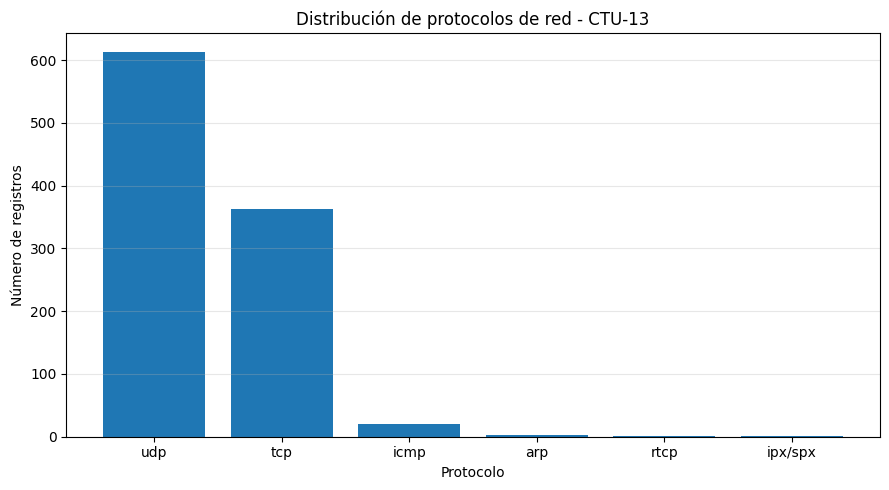

In [ ]:
import matplotlib.pyplot as plt

# Crear el espacio de la gráfica
plt.figure(figsize=(9, 5))

# Dibujar las barras
plt.bar(df_protocolos["protocolo"], df_protocolos["total"])

# Agregar título y nombres de los ejes
plt.title("Distribución de protocolos de red - CTU-13")
plt.xlabel("Protocolo")
plt.ylabel("Número de registros")

# Mostrar una cuadrícula horizontal
plt.grid(axis="y", alpha=0.3)

# Ajustar y mostrar la gráfica
plt.tight_layout()
plt.show()

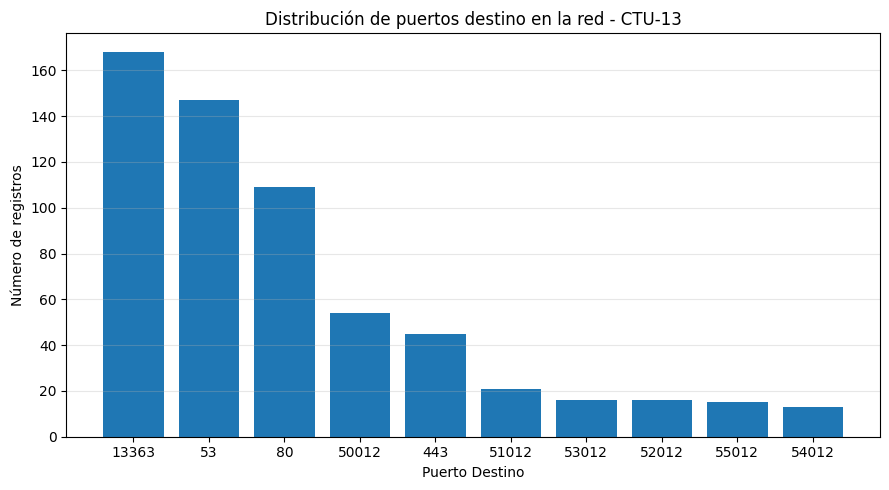

In [ ]:
import matplotlib.pyplot as plt

# Crear el espacio de la gráfica
plt.figure(figsize=(9, 5))

# Dibujar las barras
plt.bar(df_puertos_destino["puerto_destino"], df_puertos_destino["total"])

# Agregar título y nombres de los ejes
plt.title("Distribución de puertos destino en la red - CTU-13")
plt.xlabel("Puerto Destino")
plt.ylabel("Número de registros")

# Mostrar una cuadrícula horizontal
plt.grid(axis="y", alpha=0.3)

# Ajustar y mostrar la gráfica
plt.tight_layout()
plt.savefig("puertos_destino_ctu13.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import sqlite3

conexion = sqlite3.connect("ctu13_prueba.db")

tablas = conexion.execute(
    "SELECT name FROM sqlite_master WHERE type='table'"
).fetchall()

print(tablas)

conexion.close()

[('conexiones',), ('sqlite_sequence',), ('incidentes',)]


In [ ]:
import sqlite3

conexion = sqlite3.connect("ctu13_prueba.db")

columnas = conexion.execute(
    "PRAGMA table_info(conexiones)"
).fetchall()

for columna in columnas:
    print(columna)

conexion.close()

(0, 'id', 'INTEGER', 0, None, 1)
(1, 'fecha_hora', 'TEXT', 0, None, 0)
(2, 'ip_origen', 'TEXT', 0, None, 0)
(3, 'ip_destino', 'TEXT', 0, None, 0)
(4, 'puerto_destino', 'TEXT', 0, None, 0)
(5, 'protocolo', 'TEXT', 0, None, 0)
(6, 'bytes_transmitidos', 'INTEGER', 0, None, 0)


In [ ]:
import sqlite3

conexion = sqlite3.connect("ctu13_prueba.db")

consulta = """
SELECT fecha_hora, bytes_transmitidos
FROM conexiones
LIMIT 10
"""

resultados = conexion.execute(consulta).fetchall()

for registro in resultados:
    print(registro)

conexion.close()


('2011/08/16 13:51:24.049047', 1508937)
('2011/08/16 13:51:24.049051', 992275)
('2011/08/16 13:51:24.049832', 12484)
('2011/08/16 13:51:24.049954', 1692037)
('2011/08/16 13:51:24.050042', 1782878)
('2011/08/16 13:51:24.050374', 2278436)
('2011/08/16 13:51:24.050832', 88134500)
('2011/08/16 13:51:24.051606', 2238605)
('2011/08/16 13:51:24.051846', 1520182)
('2011/08/16 13:51:24.051899', 1876000)


In [ ]:
import sqlite3

conexion = sqlite3.connect("ctu13_prueba.db")

consulta = """
SELECT
    COUNT(*) AS total_conexiones,
    MIN(fecha_hora) AS primera_fecha,
    MAX(fecha_hora) AS ultima_fecha,
    COUNT(DISTINCT SUBSTR(fecha_hora, 1, 16)) AS minutos_distintos
FROM conexiones
"""

resultado = conexion.execute(consulta).fetchone()

print("Total de conexiones:", resultado[0])
print("Primera conexión:", resultado[1])
print("Última conexión:", resultado[2])
print("Minutos diferentes:", resultado[3])

conexion.close()

Total de conexiones: 1000
Primera conexión: 2011/08/16 13:51:24.049047
Última conexión: 2011/08/16 13:51:29.722037
Minutos diferentes: 1


In [ ]:
import os
import csv

archivo = "ctu13_escenario7.binetflow"

# Consultar tamaño del archivo
tamano = os.path.getsize(archivo)

print("Tamaño del archivo en MB:", round(tamano / (1024 * 1024), 2))

# Consultar columnas del archivo
with open(archivo, "r", encoding="utf-8-sig", newline="") as f:
    lector = csv.reader(f)
    encabezados = next(lector)

print("\nColumnas disponibles:")

for columna in encabezados:
    print(columna)


Tamaño del archivo en MB: 14.91

Columnas disponibles:
StartTime
Dur
Proto
SrcAddr
Sport
Dir
DstAddr
Dport
State
sTos
dTos
TotPkts
TotBytes
SrcBytes
Label


In [ ]:
import csv

archivo = "ctu13_escenario7.binetflow"

total_registros = 0
primera_fecha = None
ultima_fecha = None
minutos = set()

with open(archivo, "r", encoding="utf-8-sig", newline="") as f:

    lector = csv.DictReader(f)

    for registro in lector:

        fecha = registro["StartTime"].strip()

        if not fecha:
            continue

        total_registros += 1

        if primera_fecha is None or fecha < primera_fecha:
            primera_fecha = fecha

        if ultima_fecha is None or fecha > ultima_fecha:
            ultima_fecha = fecha

        minutos.add(fecha[:16])

print("Total de registros:", total_registros)
print("Primera conexión:", primera_fecha)
print("Última conexión:", ultima_fecha)
print("Minutos diferentes:", len(minutos))

Total de registros: 114077
Primera conexión: 2011/08/16 13:51:24.049047
Última conexión: 2011/08/16 14:12:41.499668
Minutos diferentes: 22


In [ ]:
import pandas as pd

# Leer únicamente las columnas necesarias
df_trafico = pd.read_csv(
    "ctu13_escenario7.binetflow",
    usecols=["StartTime", "TotBytes"]
)

# Convertir las fechas
df_trafico["fecha_hora"] = pd.to_datetime(
    df_trafico["StartTime"],
    format="%Y/%m/%d %H:%M:%S.%f",
    errors="coerce"
)

# Convertir los bytes a valores numéricos
df_trafico["bytes_transmitidos"] = pd.to_numeric(
    df_trafico["TotBytes"],
    errors="coerce"
)

# Descartar registros con fechas o bytes inválidos
df_validos = df_trafico.dropna(
    subset=["fecha_hora", "bytes_transmitidos"]
).copy()

# Agrupar las fechas por minuto
df_validos["minuto"] = df_validos["fecha_hora"].dt.floor("min")

# Sumar los bytes registrados en cada minuto
df_por_minuto = df_validos.groupby(
    "minuto", as_index=False
)["bytes_transmitidos"].sum()

# Mostrar resultados
print("Registros válidos:", len(df_validos))
print("Minutos analizados:", len(df_por_minuto))

display(df_por_minuto.head(10))

Registros válidos: 114077
Minutos analizados: 22


,minuto,bytes_transmitidos
0,2011-08-16 13:51:00,2340464629
1,2011-08-16 13:52:00,1110100337
2,2011-08-16 13:53:00,273462103
3,2011-08-16 13:54:00,65114415
4,2011-08-16 13:55:00,109958739
5,2011-08-16 13:56:00,229783193
6,2011-08-16 13:57:00,199357457
7,2011-08-16 13:58:00,110830809
8,2011-08-16 13:59:00,173180275
9,2011-08-16 14:00:00,201531928


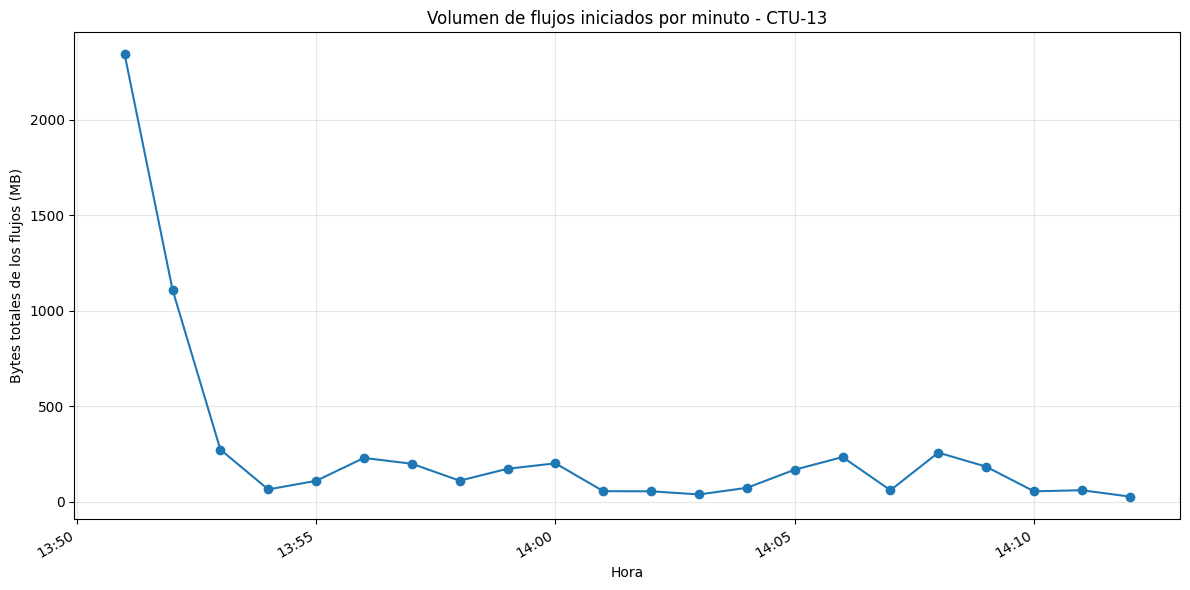

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Convertir bytes a megabytes
df_por_minuto["megabytes"] = (
    df_por_minuto["bytes_transmitidos"] / 1000000
)

# Crear figura
fig, ax = plt.subplots(figsize=(12, 6))

# Dibujar gráfica de líneas
ax.plot(
    df_por_minuto["minuto"],
    df_por_minuto["megabytes"],
    marker="o",
    linestyle="-"
)

# Configurar títulos y etiquetas
ax.set_title(
    "Volumen de flujos iniciados por minuto - CTU-13"
)

ax.set_xlabel("Hora")
ax.set_ylabel("Bytes totales de los flujos (MB)")

# Formato de las horas
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M")
)

# Cuadrícula
ax.grid(True, alpha=0.3)

# Ajustar presentación
fig.autofmt_xdate()
plt.tight_layout()

# Guardar gráfica
plt.savefig(
    "trafico_por_minuto_ctu13.png",
    dpi=300,
    bbox_inches="tight"
)

# Mostrar gráfica
plt.show()

In [ ]:
import os

print("Archivos disponibles:")
print(os.listdir())

print("\nVariable de gráfica temporal:")
print("df_por_minuto" in globals())

Archivos disponibles:
['.config', 'security_core', 'db_manager', 'net_inspector_respaldo_2026-11-04_v2.zip', 'trafico_por_minuto_ctu13.png', 'net_inspector_respaldo_2026-11-04.zip', 'log_engine', 'ctu13_prueba.db', 'puertos_destino_ctu13.png', 'net_inspector.db', 'ctu13_escenario7.binetflow', 'sample_data']

Variable de gráfica temporal:
True


In [ ]:
from pathlib import Path

imagenes = list(Path(".").glob("*.png"))

print("Imágenes encontradas:", len(imagenes))

for imagen in imagenes:
    print(imagen.name)

Imágenes encontradas: 3
trafico_por_minuto_ctu13.png
distribucion_protocolos_ctu13.png
puertos_destino_ctu13.png


  protocolo  total
0       udp    613
1       tcp    363
2      icmp     20
3       arp      2
4      rtcp      1
5   ipx/spx      1


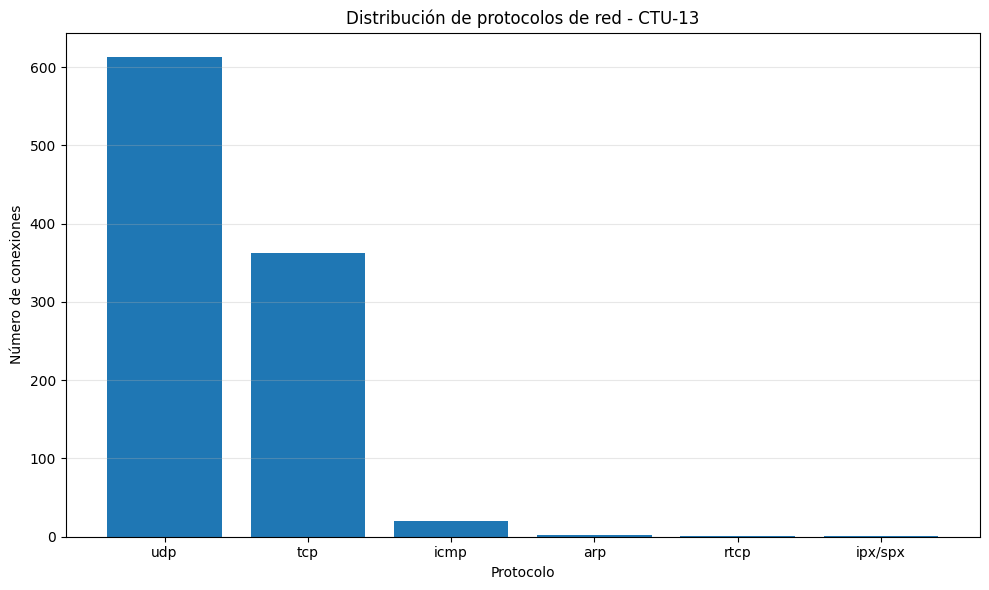

Gráfica guardada correctamente.


In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Consultar los protocolos registrados
with sqlite3.connect("ctu13_prueba.db") as conexion:
    df_protocolos = pd.read_sql_query("""
        SELECT protocolo, COUNT(*) AS total
        FROM conexiones
        GROUP BY protocolo
        ORDER BY total DESC
    """, conexion)

# Mostrar resultados
print(df_protocolos)

# Construir gráfica
fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    df_protocolos["protocolo"],
    df_protocolos["total"]
)

ax.set_title("Distribución de protocolos de red - CTU-13")
ax.set_xlabel("Protocolo")
ax.set_ylabel("Número de conexiones")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Guardar imagen
fig.savefig(
    "distribucion_protocolos_ctu13.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfica guardada correctamente.")

In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

nombre_respaldo = "net_inspector_respaldo_2026-11-10.zip"

# Carpetas del proyecto
carpetas = [
    "security_core",
    "db_manager",
    "log_engine",
    "visualizer"
]

# Archivos principales
archivos = [
    "ctu13_prueba.db",
    "net_inspector.db",
    "ctu13_escenario7.binetflow"
]

# Agregar imágenes y archivos Python
archivos += [str(p) for p in Path(".").glob("*.png")]
archivos += [str(p) for p in Path(".").glob("*.py")]

with ZipFile(nombre_respaldo, "w", ZIP_DEFLATED) as respaldo:

    for carpeta in carpetas:
        ruta = Path(carpeta)

        if ruta.exists():
            for archivo in ruta.rglob("*"):
                if archivo.is_file() and "__pycache__" not in archivo.parts:
                    respaldo.write(archivo)

    for archivo in archivos:
        ruta = Path(archivo)

        if ruta.is_file():
            respaldo.write(ruta)

# Verificar contenido
with ZipFile(nombre_respaldo, "r") as respaldo:
    print("Archivos respaldados:", len(respaldo.namelist()))
    print("Integridad:", "Correcta" if respaldo.testzip() is None else "Error")

print("Respaldo creado:", nombre_respaldo)

Archivos respaldados: 12
Integridad: Correcta
Respaldo creado: net_inspector_respaldo_2026-11-10.zip


In [ ]:
from google.colab import files

files.download("net_inspector_respaldo_2026-11-10.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

print("ESTRUCTURA ACTUAL DEL PROYECTO")
print("=" * 40)

carpetas = [
    "log_engine",
    "security_core",
    "db_manager",
    "visualizer"
]

for carpeta in carpetas:
    ruta = Path(carpeta)

    print(f"\n{carpeta}/")

    if ruta.exists():
        archivos = list(ruta.glob("*.py"))

        if archivos:
            for archivo in archivos:
                print("  ", archivo.name)
        else:
            print("   Sin archivos Python")
    else:
        print("   Carpeta todavía no creada")

print("\nARCHIVOS PYTHON PRINCIPALES")

for archivo in Path(".").glob("*.py"):
    print(archivo.name)

ESTRUCTURA ACTUAL DEL PROYECTO

log_engine/
   lector_ctu13.py
   normalizador.py

security_core/
   conexion_red.py
   detector_anomalias.py

db_manager/
   incidentes.py
   database.py

visualizer/
   Carpeta todavía no creada

ARCHIVOS PYTHON PRINCIPALES


In [ ]:
from pathlib import Path

# Crear carpeta del módulo
Path("visualizer").mkdir(exist_ok=True)

# Crear archivo de inicialización
Path("visualizer/__init__.py").touch(exist_ok=True)

print("Módulo visualizer preparado correctamente")

!ls -la

Módulo visualizer preparado correctamente
total 20
drwxr-xr-x 1 root root 4096 Nov 11 05:17 .
drwxr-xr-x 1 root root 4096 Nov 11 05:03 ..
drwxr-xr-x 4 root root 4096 Oct 26 22:18 .config
drwxr-xr-x 1 root root 4096 Oct 26 22:18 sample_data
drwxr-xr-x 2 root root 4096 Nov 11 05:17 visualizer


In [ ]:
!unzip -l net_inspector_respaldo_2026-11-10.zip

Archive:  net_inspector_respaldo_2026-11-10.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
      387  2026-11-10 21:16   security_core/conexion_red.py
     1141  2026-11-10 21:17   security_core/detector_anomalias.py
     1250  2026-11-10 21:17   db_manager/incidentes.py
     1458  2026-11-10 21:16   db_manager/database.py
      219  2026-11-10 21:16   log_engine/lector_ctu13.py
      369  2026-11-10 21:16   log_engine/normalizador.py
    98304  2026-11-10 21:17   ctu13_prueba.db
    12288  2026-11-10 21:16   net_inspector.db
 15630512  2015-01-30 16:22   ctu13_escenario7.binetflow
   160107  2026-11-10 22:35   trafico_por_minuto_ctu13.png
    95675  2026-11-10 22:44   distribucion_protocolos_ctu13.png
    95921  2026-11-10 22:21   puertos_destino_ctu13.png
---------                     -------
 16097631                     12 files


In [ ]:
!unzip -n net_inspector_respaldo_2026-11-10.zip

Archive:  net_inspector_respaldo_2026-11-10.zip
  inflating: security_core/conexion_red.py  
  inflating: security_core/detector_anomalias.py  
  inflating: db_manager/incidentes.py  
  inflating: db_manager/database.py  
  inflating: log_engine/lector_ctu13.py  
  inflating: log_engine/normalizador.py  
  inflating: ctu13_prueba.db         
  inflating: net_inspector.db        
  inflating: ctu13_escenario7.binetflow  
  inflating: trafico_por_minuto_ctu13.png  
  inflating: distribucion_protocolos_ctu13.png  
  inflating: puertos_destino_ctu13.png  


In [ ]:
!cat log_engine/normalizador.py


from security_core.conexion_red import ConexionRed


def convertir_ctu13(registro):

    return ConexionRed(
        fecha_hora=registro["StartTime"],
        ip_origen=registro["SrcAddr"],
        ip_destino=registro["DstAddr"],
        puerto_destino=registro["Dport"],
        protocolo=registro["Proto"],
        bytes_transmitidos=int(registro["TotBytes"])
    )


In [ ]:
from log_engine.normalizador import convertir_ctu13

registro_prueba = {
    "StartTime": "2026-11-10 20:00:00",
    "SrcAddr": "192.168.1.50",
    "DstAddr": "8.8.8.8",
    "Dport": "443",
    "Proto": "tcp",
    "TotBytes": "2048"
}

conexion = convertir_ctu13(registro_prueba)

print("Tipo de objeto:", type(conexion).__name__)
print("IP origen:", conexion.ip_origen)
print("IP destino:", conexion.ip_destino)
print("Bytes:", conexion.bytes_transmitidos)

Tipo de objeto: ConexionRed
IP origen: 192.168.1.50
IP destino: 8.8.8.8
Bytes: 2048


In [ ]:
from security_core.conexion_red import ConexionRed

def convertir_generico(registro):
    return ConexionRed(
        fecha_hora=registro["timestamp"],
        ip_origen=registro["src_ip"],
        ip_destino=registro["dst_ip"],
        puerto_destino=registro["dst_port"],
        protocolo=registro["protocol"],
        bytes_transmitidos=int(registro["bytes"])
    )


# Registro de prueba con otro formato
registro_generico = {
    "timestamp": "2026-11-10 21:00:00",
    "src_ip": "192.168.1.100",
    "dst_ip": "8.8.4.4",
    "dst_port": "443",
    "protocol": "tcp",
    "bytes": "3500"
}

conexion_2 = convertir_generico(registro_generico)

print("Tipo:", type(conexion_2).__name__)
print("Origen:", conexion_2.ip_origen)
print("Destino:", conexion_2.ip_destino)
print("Bytes:", conexion_2.bytes_transmitidos)

Tipo: ConexionRed
Origen: 192.168.1.100
Destino: 8.8.4.4
Bytes: 3500


In [ ]:
from pathlib import Path

archivo = Path("log_engine/normalizador.py")

contenido = archivo.read_text(encoding="utf-8")

nueva_funcion = """

def convertir_generico(registro):
    return ConexionRed(
        fecha_hora=registro["timestamp"],
        ip_origen=registro["src_ip"],
        ip_destino=registro["dst_ip"],
        puerto_destino=registro["dst_port"],
        protocolo=registro["protocol"],
        bytes_transmitidos=int(registro["bytes"])
    )
"""

if "def convertir_generico(" not in contenido:
    archivo.write_text(
        contenido.rstrip() + "\n" + nueva_funcion,
        encoding="utf-8"
    )
    print("Normalizador genérico agregado correctamente.")
else:
    print("El normalizador genérico ya existe.")

Normalizador genérico agregado correctamente.


In [ ]:
import importlib
import log_engine.normalizador as normalizador

# Recargar el módulo para reconocer los cambios recientes
importlib.reload(normalizador)

# Probar los dos formatos
conexion_1 = normalizador.convertir_ctu13(registro_prueba)
conexion_2 = normalizador.convertir_generico(registro_generico)

print("=== PRUEBA DE NORMALIZADORES ===")
print("CTU-13:", conexion_1.ip_origen)
print("Genérico:", conexion_2.ip_origen)

print("Tipo CTU-13:", type(conexion_1).__name__)
print("Tipo genérico:", type(conexion_2).__name__)

=== PRUEBA DE NORMALIZADORES ===
CTU-13: 192.168.1.50
Genérico: 192.168.1.100
Tipo CTU-13: ConexionRed
Tipo genérico: ConexionRed


In [ ]:
from pathlib import Path

archivos = [
    "log_engine/lector_ctu13.py",
    "security_core/conexion_red.py",
    "security_core/detector_anomalias.py",
    "db_manager/database.py",
    "db_manager/incidentes.py"
]

for nombre in archivos:
    print(f"\n========== {nombre} ==========")
    print(Path(nombre).read_text(encoding="utf-8"))


========== log_engine/lector_ctu13.py ==========

import csv

def leer_ctu13(ruta_archivo):
    with open(ruta_archivo, "r", encoding="utf-8", newline="") as archivo:
        lector = csv.DictReader(archivo)

        for registro in lector:
            yield registro


========== security_core/conexion_red.py ==========

class ConexionRed:

    def __init__(self, fecha_hora, ip_origen, ip_destino,
                 puerto_destino, protocolo, bytes_transmitidos):

        self.fecha_hora = fecha_hora
        self.ip_origen = ip_origen
        self.ip_destino = ip_destino
        self.puerto_destino = puerto_destino
        self.protocolo = protocolo
        self.bytes_transmitidos = bytes_transmitidos


========== security_core/detector_anomalias.py ==========

from collections import defaultdict, deque
from datetime import datetime, timedelta


class DetectorAnomalias:

    def __init__(self, umbral_flujos=100, ventana_segundos=60):
        self.umbral_flujos = umbral_flujos
        se

In [ ]:
!grep -nE '^(class |def |[[:space:]]+def )' log_engine/lector_ctu13.py security_core/conexion_red.py security_core/detector_anomalias.py db_manager/database.py db_manager/incidentes.py

log_engine/lector_ctu13.py:4:def leer_ctu13(ruta_archivo):
security_core/conexion_red.py:2:class ConexionRed:
security_core/conexion_red.py:4:    def __init__(self, fecha_hora, ip_origen, ip_destino,
security_core/detector_anomalias.py:6:class DetectorAnomalias:
security_core/detector_anomalias.py:8:    def __init__(self, umbral_flujos=100, ventana_segundos=60):
security_core/detector_anomalias.py:12:    def detectar_rafagas(self, conexiones):
db_manager/database.py:5:def crear_base_datos(ruta_db="net_inspector.db"):
db_manager/database.py:21:def guardar_conexiones(conexiones, ruta_db="net_inspector.db"):
db_manager/database.py:47:def consultar_resumen(ruta_db="net_inspector.db"):
db_manager/incidentes.py:5:def guardar_alertas(alertas, umbral, ventana_segundos,


In [ ]:
%%writefile main.py

from itertools import islice
from datetime import datetime
from pathlib import Path

from log_engine.lector_ctu13 import leer_ctu13
from log_engine.normalizador import convertir_ctu13

from security_core.detector_anomalias import DetectorAnomalias

from db_manager.database import (
    crear_base_datos,
    guardar_conexiones,
    consultar_resumen
)

from db_manager.incidentes import guardar_alertas


def main():

    print("================================")
    print("       NET INSPECTOR")
    print("================================")

    # Configuración de la prueba
    archivo = "ctu13_escenario7.binetflow"
    limite = 1000
    umbral = 100
    ventana = 60

    # Crear una base independiente para esta prueba
    identificador = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    ruta_db = f"net_inspector_integracion_{identificador}.db"

    # Verificar que exista el archivo de entrada
    if not Path(archivo).exists():
        print("Error: no se encontró el archivo de tráfico.")
        return

    # Leer y normalizar registros
    registros = leer_ctu13(archivo)

    conexiones = [
        convertir_ctu13(registro)
        for registro in islice(registros, limite)
    ]

    print("Conexiones procesadas:", len(conexiones))

    # Analizar posibles anomalías
    detector = DetectorAnomalias(
        umbral_flujos=umbral,
        ventana_segundos=ventana
    )

    alertas = list(detector.detectar_rafagas(conexiones))

    print("Alertas detectadas:", len(alertas))

    # Crear base de datos
    crear_base_datos(ruta_db)

    # Guardar conexiones
    guardar_conexiones(conexiones, ruta_db)

    # Guardar alertas
    guardar_alertas(alertas, umbral, ventana, ruta_db)

    # Consultar resultados
    cantidad, total_bytes = consultar_resumen(ruta_db)

    print("--------------------------------")
    print("Conexiones almacenadas:", cantidad)
    print("Bytes registrados:", total_bytes)
    print("Base de datos:", ruta_db)
    print("--------------------------------")
    print("Análisis finalizado correctamente")


if __name__ == "__main__":
    main()

Writing main.py


In [ ]:
!python main.py

       NET INSPECTOR
Conexiones procesadas: 1000
Alertas detectadas: 1
--------------------------------
Conexiones almacenadas: 1000
Bytes registrados: 1540799127
Base de datos: net_inspector_integracion_20261111_060052_419031.db
--------------------------------
Análisis finalizado correctamente


In [ ]:
%%writefile visualizer/resumen.py

import sqlite3
from pathlib import Path
import matplotlib.pyplot as plt


def graficar_protocolos(ruta_db):

    # Consultar los protocolos almacenados
    with sqlite3.connect(ruta_db) as db:

        datos = db.execute("""
            SELECT protocolo, COUNT(*)
            FROM conexiones
            GROUP BY protocolo
            ORDER BY COUNT(*) DESC
        """).fetchall()

    if not datos:
        print("No existen conexiones para graficar.")
        return None

    # Separar protocolos y cantidades
    protocolos, cantidades = zip(*datos)

    # Generar gráfica
    fig, ax = plt.subplots(figsize=(8, 5))

    ax.bar(protocolos, cantidades)

    ax.set_title("Net Inspector - Distribución de protocolos")
    ax.set_xlabel("Protocolo")
    ax.set_ylabel("Cantidad de conexiones")

    fig.tight_layout()

    # Guardar imagen
    ruta_salida = Path("visualizer/protocolos_integracion.png")

    fig.savefig(ruta_salida, dpi=150)
    plt.close(fig)

    return ruta_salida

Writing visualizer/resumen.py


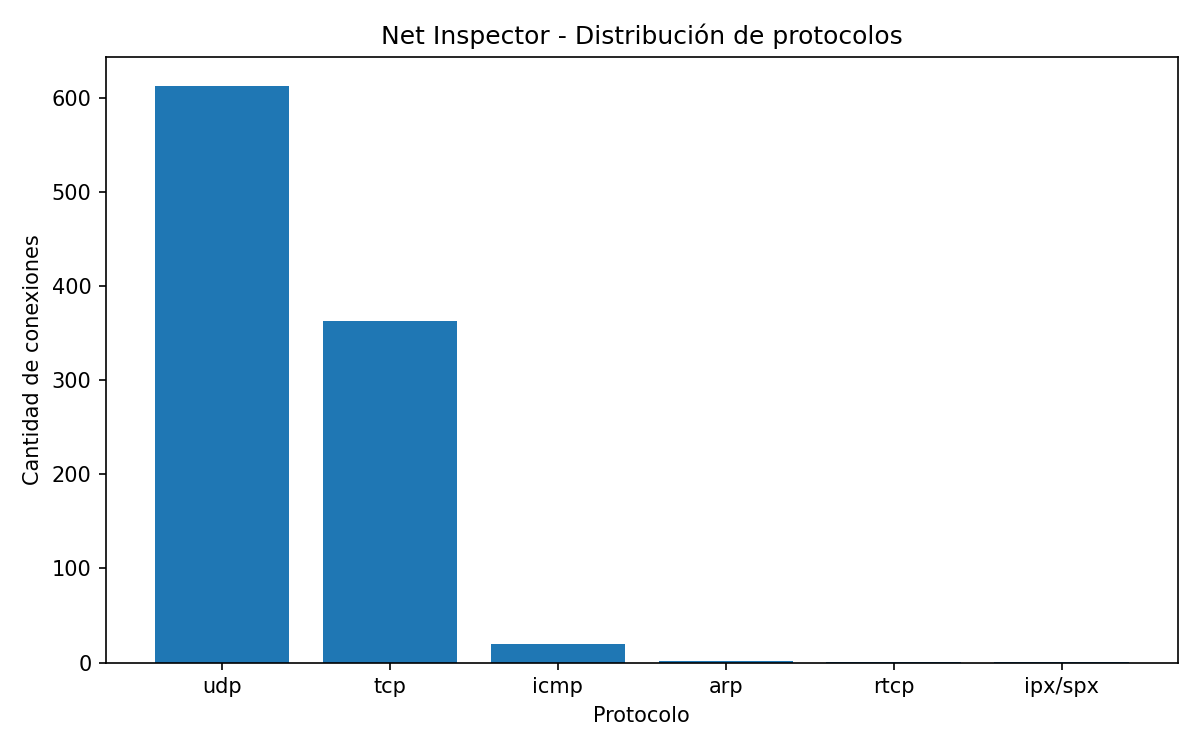

In [ ]:
from pathlib import Path
from IPython.display import Image, display

from visualizer.resumen import graficar_protocolos

# Localizar la base de datos más reciente
bases = list(Path(".").glob("net_inspector_integracion_*.db"))

ruta_db = max(bases, key=lambda archivo: archivo.stat().st_mtime)

# Generar gráfica
imagen = graficar_protocolos(ruta_db)

if imagen is not None:
    display(Image(filename=str(imagen)))

In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

# Nombre del respaldo
nombre_respaldo = "net_inspector_respaldo_2026-11-11.zip"

# Registro del estado del proyecto
estado = """
NET INSPECTOR — ESTADO DEL PROYECTO
Fecha: 11 de noviembre de 2026

MAESTRÍA EN CIENCIAS Y TECNOLOGÍAS COMPUTACIONALES
Materia: Programación Básica

AVANCES CONFIRMADOS

1. Normalizador CTU-13 validado.
2. Normalizador genérico agregado y probado.
3. Clase ConexionRed funcionando.
4. Detector de anomalías integrado.
5. Almacenamiento SQLite funcionando.
6. Registro de alertas integrado.
7. Archivo main.py creado y ejecutado.
8. Visualizer/resumen.py creado.
9. Gráfica de protocolos generada correctamente.

PRUEBA DE INTEGRACIÓN

Registros procesados: 1000
Registros almacenados: 1000
Bytes registrados: 1540799127
Alertas detectadas: 1

LIMITACIONES

- main.py utiliza actualmente CTU-13.
- El normalizador genérico solo se probó con datos ficticios.
- Las visualizaciones todavía no se ejecutan desde main.py.
- Falta mejorar la validación de datos y manejo de errores.
- Falta realizar pruebas integrales más extensas.

SIGUIENTE ACTIVIDAD

Integrar visualizer/resumen.py con main.py.

Después:
- Incorporar las demás gráficas.
- Mejorar selección de fuentes de registros.
- Validar errores y registros incompletos.
- Continuar pruebas y documentación.

ESTADO GENERAL

Primera integración funcional completada.
Proyecto en desarrollo.
"""

Path("ESTADO_NET_INSPECTOR.txt").write_text(
    estado,
    encoding="utf-8"
)

# Archivos principales
archivos = [
    Path("main.py"),
    Path("ctu13_escenario7.binetflow"),
    Path("ESTADO_NET_INSPECTOR.txt")
]

# Incorporar módulos completos
for carpeta in [
    "log_engine",
    "security_core",
    "db_manager",
    "visualizer"
]:
    archivos.extend(
        p for p in Path(carpeta).rglob("*")
        if p.is_file()
    )

# Incorporar bases de datos e imágenes
for patron in ["*.db", "*.png"]:
    archivos.extend(
        p for p in Path(".").glob(patron)
        if p.is_file()
    )

# Eliminar duplicados y archivos inexistentes
archivos = sorted(set(
    p for p in archivos if p.is_file()
))

# Crear respaldo
with ZipFile(nombre_respaldo, "w", ZIP_DEFLATED) as zipf:
    for archivo in archivos:
        zipf.write(archivo, archivo.as_posix())

# Verificar integridad
with ZipFile(nombre_respaldo, "r") as zipf:
    error = zipf.testzip()

if error is None:
    print("RESPALDO CREADO Y VERIFICADO")
    print("Archivos incluidos:", len(archivos))
    print("Nombre:", nombre_respaldo)

    files.download(nombre_respaldo)
else:
    print("Error de integridad:", error)

RESPALDO CREADO Y VERIFICADO
Archivos incluidos: 26
Nombre: net_inspector_respaldo_2026-11-11.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print("Archivos disponibles:")
print(os.listdir("/content"))

Archivos disponibles:
['.config', 'net_inspector_respaldo_2026-11-11.zip', 'sample_data']


In [ ]:
import zipfile

archivo = "/content/net_inspector_respaldo_2026-11-11.zip"

with zipfile.ZipFile(archivo, "r") as zip_ref:
    print("Archivos encontrados en el respaldo:")
    for nombre in zip_ref.namelist():
        print(nombre)

Archivos encontrados en el respaldo:
ESTADO_NET_INSPECTOR.txt
ctu13_escenario7.binetflow
ctu13_prueba.db
db_manager/__pycache__/database.cpython-313.pyc
db_manager/__pycache__/incidentes.cpython-313.pyc
db_manager/database.py
db_manager/incidentes.py
distribucion_protocolos_ctu13.png
log_engine/__pycache__/lector_ctu13.cpython-313.pyc
log_engine/__pycache__/normalizador.cpython-313.pyc
log_engine/lector_ctu13.py
log_engine/normalizador.py
main.py
net_inspector.db
net_inspector_integracion_20261111_060052_419031.db
puertos_destino_ctu13.png
security_core/__pycache__/conexion_red.cpython-313.pyc
security_core/__pycache__/detector_anomalias.cpython-313.pyc
security_core/conexion_red.py
security_core/detector_anomalias.py
trafico_por_minuto_ctu13.png
visualizer/__init__.py
visualizer/__pycache__/__init__.cpython-313.pyc
visualizer/__pycache__/resumen.cpython-313.pyc
visualizer/protocolos_integracion.png
visualizer/resumen.py


In [ ]:
import zipfile
import os

archivo = "/content/net_inspector_respaldo_2026-11-11.zip"

with zipfile.ZipFile(archivo, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Proyecto restaurado correctamente.")
print("\nArchivos disponibles:")

for nombre in sorted(os.listdir("/content")):
    print(nombre)

Proyecto restaurado correctamente.

Archivos disponibles:
.config
ESTADO_NET_INSPECTOR.txt
ctu13_escenario7.binetflow
ctu13_prueba.db
db_manager
distribucion_protocolos_ctu13.png
log_engine
main.py
net_inspector.db
net_inspector_integracion_20261111_060052_419031.db
net_inspector_respaldo_2026-11-11.zip
puertos_destino_ctu13.png
sample_data
security_core
trafico_por_minuto_ctu13.png
visualizer


In [ ]:
from pathlib import Path

archivos = [
    "/content/main.py",
    "/content/visualizer/resumen.py"
]

for archivo in archivos:
    print("\n" + "=" * 50)
    print("ARCHIVO:", archivo)
    print("=" * 50)

    contenido = Path(archivo).read_text(encoding="utf-8")
    print(contenido)


ARCHIVO: /content/main.py

from itertools import islice
from datetime import datetime
from pathlib import Path

from log_engine.lector_ctu13 import leer_ctu13
from log_engine.normalizador import convertir_ctu13

from security_core.detector_anomalias import DetectorAnomalias

from db_manager.database import (
    crear_base_datos,
    guardar_conexiones,
    consultar_resumen
)

from db_manager.incidentes import guardar_alertas


def main():

    print("================================")
    print("       NET INSPECTOR")
    print("================================")

    # Configuración de la prueba
    archivo = "ctu13_escenario7.binetflow"
    limite = 1000
    umbral = 100
    ventana = 60

    # Crear una base independiente para esta prueba
    identificador = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    ruta_db = f"net_inspector_integracion_{identificador}.db"

    # Verificar que exista el archivo de entrada
    if not Path(archivo).exists():
        print("Error: no se encont

In [ ]:
from pathlib import Path

archivo = Path("/content/main.py")
codigo = archivo.read_text(encoding="utf-8")

# Verificar los puntos donde modificaremos el código
importacion_original = "from db_manager.incidentes import guardar_alertas"
linea_final = '    print("Análisis finalizado correctamente")'

if codigo.count(importacion_original) != 1 or codigo.count(linea_final) != 1:
    raise ValueError("No se encontraron los puntos esperados de integración.")

# Incorporar la función de visualización
nueva_importacion = "from visualizer.resumen import graficar_protocolos"

if nueva_importacion not in codigo:
    codigo = codigo.replace(
        importacion_original,
        importacion_original + "\n" + nueva_importacion
    )

# Ejecutar la gráfica después de guardar los datos
nueva_funcion = """    ruta_grafica = graficar_protocolos(ruta_db)
    if ruta_grafica is not None:
        print("Gráfica guardada en:", ruta_grafica)

"""

if "ruta_grafica = graficar_protocolos(ruta_db)" not in codigo:
    codigo = codigo.replace(
        linea_final,
        nueva_funcion + linea_final
    )

# Guardar las modificaciones
archivo.write_text(codigo, encoding="utf-8")

print("Integración incorporada en main.py")

Integración incorporada en main.py


In [ ]:
%run /content/main.py

       NET INSPECTOR
Conexiones procesadas: 1000
Alertas detectadas: 1
--------------------------------
Conexiones almacenadas: 1000
Bytes registrados: 1540799127
Base de datos: net_inspector_integracion_20261117_223121_847870.db
--------------------------------
Gráfica guardada en: visualizer/protocolos_integracion.png
Análisis finalizado correctamente


<Figure size 640x480 with 0 Axes>

Gráfica encontrada correctamente.


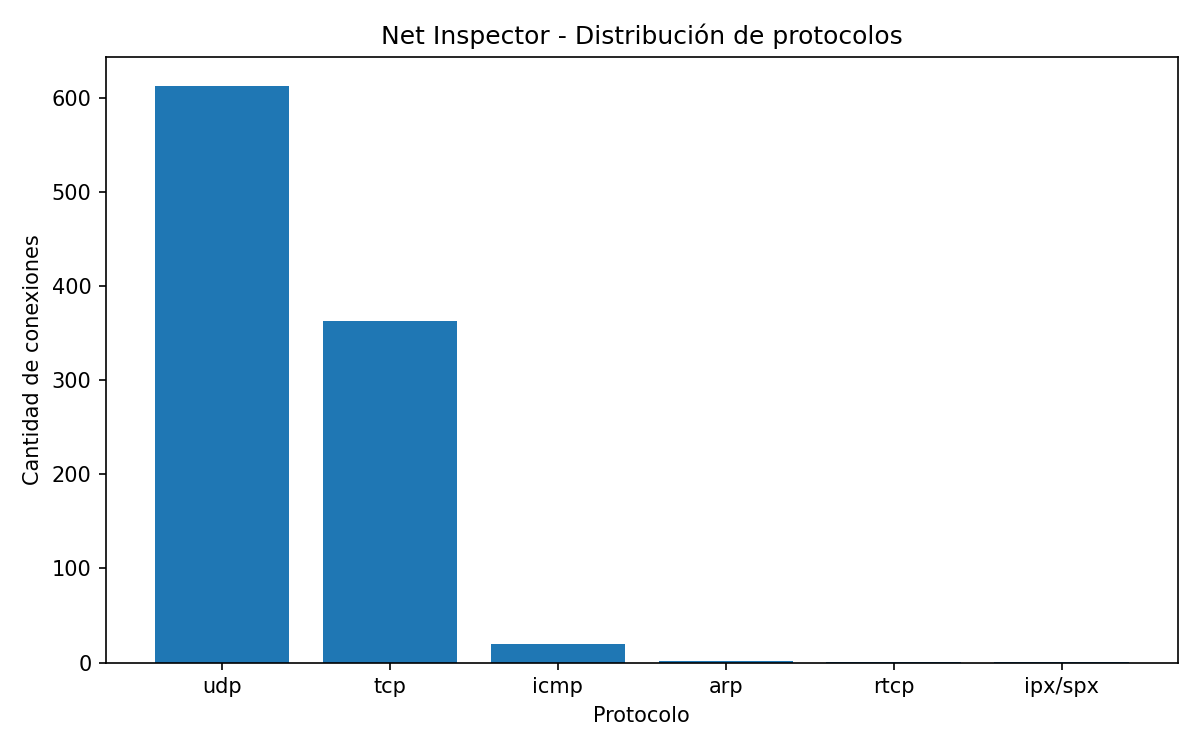

In [ ]:
from pathlib import Path
from IPython.display import Image, display

ruta = Path("/content/visualizer/protocolos_integracion.png")

if ruta.exists():
    print("Gráfica encontrada correctamente.")
    display(Image(filename=str(ruta)))
else:
    print("No se encontró la gráfica.")

In [ ]:
import sqlite3
from pathlib import Path

# Localizar la base de datos más reciente
bases = list(Path("/content").glob(
    "net_inspector_integracion_*.db"
))

ruta_db = max(bases, key=lambda archivo: archivo.stat().st_mtime)

print("Base de datos:", ruta_db.name)

# Conectar con SQLite
with sqlite3.connect(ruta_db) as conexion:

    # Consultar la estructura de la tabla
    columnas = conexion.execute(
        "PRAGMA table_info(conexiones)"
    ).fetchall()

    print("\nColumnas disponibles:")

    for columna in columnas:
        print(columna[1])

Base de datos: net_inspector_integracion_20261117_223121_847870.db

Columnas disponibles:
id
fecha_hora
ip_origen
ip_destino
puerto_destino
protocolo
bytes_transmitidos


In [ ]:
from pathlib import Path

archivo = Path("/content/visualizer/resumen.py")

codigo = archivo.read_text(encoding="utf-8")

nueva_funcion = '''

def graficar_puertos_destino(ruta_db):

    # Consultar los 10 puertos más frecuentes
    with sqlite3.connect(ruta_db) as db:

        datos = db.execute("""
            SELECT puerto_destino, COUNT(*) AS total
            FROM conexiones
            WHERE puerto_destino IS NOT NULL
            AND TRIM(CAST(puerto_destino AS TEXT)) != ''
            GROUP BY puerto_destino
            ORDER BY total DESC
            LIMIT 10
        """).fetchall()

    if not datos:
        print("No existen puertos para graficar.")
        return None

    # Separar puertos y cantidades
    puertos, cantidades = zip(*datos)

    # Crear gráfica
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.bar([str(p) for p in puertos], cantidades)

    ax.set_title("Net Inspector - Puertos de destino")
    ax.set_xlabel("Puerto de destino")
    ax.set_ylabel("Cantidad de conexiones")

    plt.xticks(rotation=45)

    fig.tight_layout()

    # Guardar imagen
    ruta_salida = (
        Path(__file__).resolve().parent
        / "puertos_destino_integracion.png"
    )

    fig.savefig(ruta_salida, dpi=150)
    plt.close(fig)

    return ruta_salida
'''

if "def graficar_puertos_destino(" not in codigo:
    archivo.write_text(
        codigo + nueva_funcion,
        encoding="utf-8"
    )
    print("Función agregada correctamente.")
else:
    print("La función ya existe.")

Función agregada correctamente.


Gráfica generada correctamente:


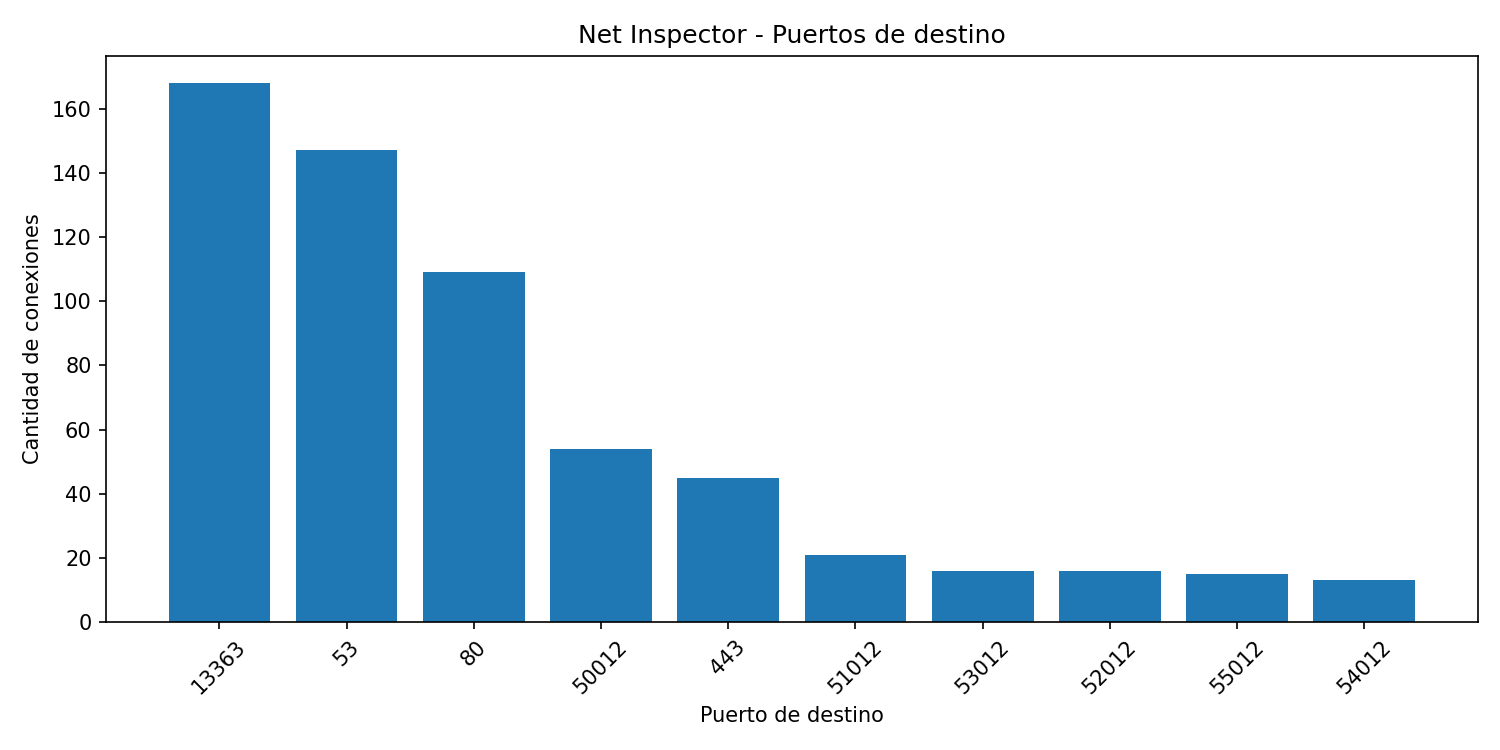

In [ ]:
import importlib
from pathlib import Path
from IPython.display import Image, display

import visualizer.resumen as resumen

# Actualizar el módulo después de modificarlo
importlib.reload(resumen)

# Recuperar la base de datos más reciente
bases = list(
    Path("/content").glob("net_inspector_integracion_*.db")
)

ruta_db = max(
    bases,
    key=lambda archivo: archivo.stat().st_mtime
)

# Generar gráfica
ruta_grafica = resumen.graficar_puertos_destino(ruta_db)

if ruta_grafica is not None:
    print("Gráfica generada correctamente:")
    display(Image(filename=str(ruta_grafica)))

In [ ]:
from pathlib import Path

archivo = Path("/content/main.py")
codigo = archivo.read_text(encoding="utf-8")

# Localizar la importación actual
importacion_original = (
    "from visualizer.resumen import graficar_protocolos"
)

importacion_nueva = (
    "from visualizer.resumen import "
    "graficar_protocolos, graficar_puertos_destino"
)

# Localizar el final del programa
linea_final = '    print("Análisis finalizado correctamente")'

# Código que integra la segunda gráfica
integracion = '''
    # Generar gráfica de puertos de destino
    ruta_grafica_puertos = graficar_puertos_destino(ruta_db)

    if ruta_grafica_puertos is not None:
        print("Gráfica de puertos:", ruta_grafica_puertos)

'''

# Comprobar que podemos modificar el código de forma segura
if "graficar_puertos_destino" not in codigo:

    if (
        codigo.count(importacion_original) != 1
        or codigo.count(linea_final) != 1
    ):
        raise ValueError("No se encontraron los puntos de integración.")

    # Modificar la importación
    codigo = codigo.replace(
        importacion_original,
        importacion_nueva
    )

    # Incorporar la nueva función
    codigo = codigo.replace(
        linea_final,
        integracion + linea_final
    )

    # Guardar respaldo del archivo anterior
    Path("/content/main.py.bak").write_text(
        archivo.read_text(encoding="utf-8"),
        encoding="utf-8"
    )

    # Guardar los cambios
    archivo.write_text(codigo, encoding="utf-8")

    print("Segunda visualización integrada correctamente.")

else:
    print("La función ya está integrada.")

Segunda visualización integrada correctamente.


In [ ]:
%run /content/main.py

       NET INSPECTOR
Conexiones procesadas: 1000
Alertas detectadas: 1
--------------------------------
Conexiones almacenadas: 1000
Bytes registrados: 1540799127
Base de datos: net_inspector_integracion_20261117_230126_408846.db
--------------------------------
Gráfica guardada en: visualizer/protocolos_integracion.png
Gráfica de puertos: /content/visualizer/puertos_destino_integracion.png
Análisis finalizado correctamente


<Figure size 640x480 with 0 Axes>

In [ ]:
import sqlite3
from pathlib import Path

# Localizar la base de datos más reciente
bases = list(
    Path("/content").glob("net_inspector_integracion_*.db")
)

ruta_db = max(
    bases,
    key=lambda archivo: archivo.stat().st_mtime
)

# Consultar cinco registros
with sqlite3.connect(ruta_db) as db:

    registros = db.execute("""
        SELECT fecha_hora, bytes_transmitidos
        FROM conexiones
        LIMIT 5
    """).fetchall()

# Mostrar resultados
print("Primeros cinco registros:\n")

for fecha, bytes_total in registros:
    print("Fecha:", fecha, "| Bytes:", bytes_total)

Primeros cinco registros:

Fecha: 2011/08/16 13:51:24.049047 | Bytes: 1508937
Fecha: 2011/08/16 13:51:24.049051 | Bytes: 992275
Fecha: 2011/08/16 13:51:24.049832 | Bytes: 12484
Fecha: 2011/08/16 13:51:24.049954 | Bytes: 1692037
Fecha: 2011/08/16 13:51:24.050042 | Bytes: 1782878


In [ ]:
from pathlib import Path

archivo = Path("/content/visualizer/resumen.py")

codigo = archivo.read_text(encoding="utf-8")

nueva_funcion = '''

def graficar_trafico_por_minuto(ruta_db):

    from datetime import datetime
    from collections import defaultdict

    # Consultar fechas y bytes almacenados
    with sqlite3.connect(ruta_db) as db:

        datos = db.execute("""
            SELECT fecha_hora, bytes_transmitidos
            FROM conexiones
            WHERE fecha_hora IS NOT NULL
            AND bytes_transmitidos IS NOT NULL
        """).fetchall()

    if not datos:
        print("No existen registros para graficar.")
        return None

    # Agrupar bytes por minuto
    trafico = defaultdict(int)

    for fecha_texto, cantidad_bytes in datos:

        fecha = datetime.strptime(
            fecha_texto,
            "%Y/%m/%d %H:%M:%S.%f"
        )

        minuto = fecha.replace(
            second=0,
            microsecond=0
        )

        trafico[minuto] += int(cantidad_bytes)

    # Ordenar los minutos cronológicamente
    minutos = sorted(trafico.keys())

    # Convertir bytes a MiB
    cantidades = [
        trafico[minuto] / (1024 ** 2)
        for minuto in minutos
    ]

    # Crear gráfica
    fig, ax = plt.subplots(figsize=(11, 5))

    ax.plot(
        minutos,
        cantidades,
        marker="o"
    )

    ax.set_title("Net Inspector - Tráfico por minuto")
    ax.set_xlabel("Fecha y hora")
    ax.set_ylabel("Tráfico (MiB por minuto)")

    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=0)

    fig.autofmt_xdate()
    fig.tight_layout()

    # Guardar gráfica
    ruta_salida = (
        Path(__file__).resolve().parent
        / "trafico_por_minuto_integracion.png"
    )

    fig.savefig(ruta_salida, dpi=150)
    plt.close(fig)

    print("Minutos representados:", len(minutos))

    return ruta_salida
'''

if "def graficar_trafico_por_minuto(" not in codigo:

    archivo.write_text(
        codigo + nueva_funcion,
        encoding="utf-8"
    )

    print("Función agregada correctamente.")

else:
    print("La función ya existe.")


Función agregada correctamente.


Minutos representados: 1
Gráfica generada correctamente.


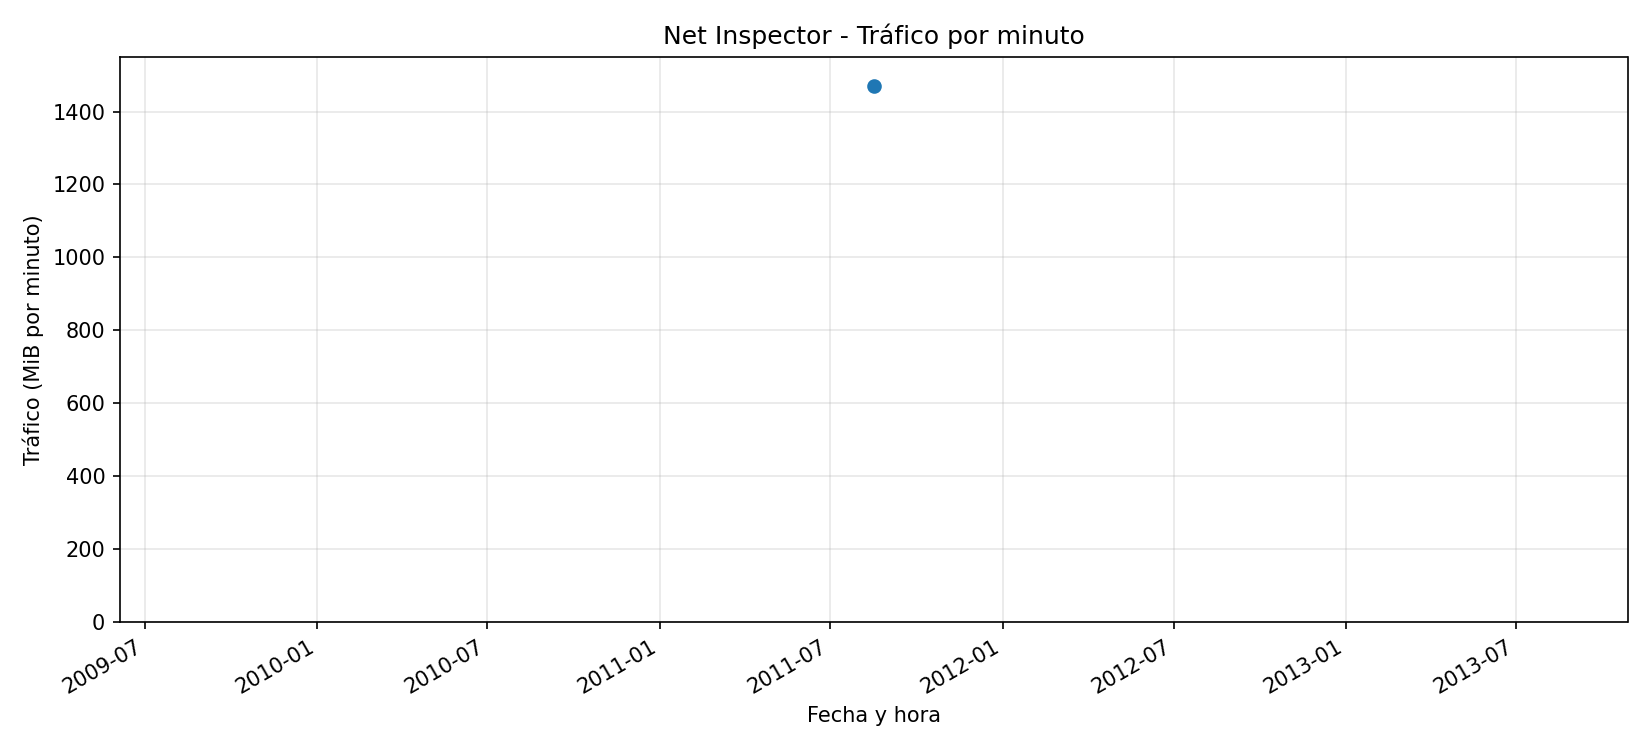

In [ ]:
import importlib
from pathlib import Path
from IPython.display import Image, display

import visualizer.resumen as resumen

# Recargar el módulo actualizado
importlib.reload(resumen)

# Localizar la base de datos más reciente
bases = list(
    Path("/content").glob("net_inspector_integracion_*.db")
)

ruta_db = max(
    bases,
    key=lambda archivo: archivo.stat().st_mtime
)

# Generar la tercera gráfica
ruta_grafica = resumen.graficar_trafico_por_minuto(ruta_db)

if ruta_grafica is not None:

    print("Gráfica generada correctamente.")

    display(Image(filename=str(ruta_grafica)))

In [ ]:
from log_engine.lector_ctu13 import leer_ctu13
from datetime import datetime

archivo = "/content/ctu13_escenario7.binetflow"

minutos = set()
primera_fecha = None
ultima_fecha = None

for indice, registro in enumerate(leer_ctu13(archivo), start=1):

    fecha = datetime.strptime(
        registro["StartTime"],
        "%Y/%m/%d %H:%M:%S.%f"
    )

    minuto = fecha.replace(
        second=0,
        microsecond=0
    )

    minutos.add(minuto)

    if primera_fecha is None:
        primera_fecha = fecha

    ultima_fecha = fecha

    if indice in (1000, 5000, 10000):
        print(
            f"{indice} registros:",
            len(minutos),
            "minutos diferentes"
        )

    if indice == 10000:
        break

print("\nPrimera fecha:", primera_fecha)
print("Última fecha:", ultima_fecha)

1000 registros: 1 minutos diferentes
5000 registros: 1 minutos diferentes
10000 registros: 2 minutos diferentes

Primera fecha: 2011-08-16 13:51:24.049047
Última fecha: 2011-08-16 13:52:33.082523


In [ ]:
from collections import Counter
from datetime import datetime

from log_engine.lector_ctu13 import leer_ctu13

archivo = "/content/ctu13_escenario7.binetflow"

conexiones_por_minuto = Counter()

total = 0
primera_fecha = None
ultima_fecha = None

for registro in leer_ctu13(archivo):

    fecha = datetime.strptime(
        registro["StartTime"],
        "%Y/%m/%d %H:%M:%S.%f"
    )

    minuto = fecha.replace(second=0, microsecond=0)

    conexiones_por_minuto[minuto] += 1
    total += 1

    if primera_fecha is None or fecha < primera_fecha:
        primera_fecha = fecha

    if ultima_fecha is None or fecha > ultima_fecha:
        ultima_fecha = fecha

print("===== ANÁLISIS TEMPORAL CTU-13 =====")

print("Total de conexiones:", total)
print("Minutos diferentes:", len(conexiones_por_minuto))

print("Primera fecha:", primera_fecha)
print("Última fecha:", ultima_fecha)

print("\nConexiones por minuto:")

for minuto, cantidad in sorted(conexiones_por_minuto.items()):
    print(minuto, ":", cantidad)

===== ANÁLISIS TEMPORAL CTU-13 =====
Total de conexiones: 114077
Minutos diferentes: 22
Primera fecha: 2011-08-16 13:51:24.049047
Última fecha: 2011-08-16 14:12:41.499668

Conexiones por minuto:
2011-08-16 13:51:00 : 6039
2011-08-16 13:52:00 : 6691
2011-08-16 13:53:00 : 5501
2011-08-16 13:54:00 : 5209
2011-08-16 13:55:00 : 5224
2011-08-16 13:56:00 : 5223
2011-08-16 13:57:00 : 5425
2011-08-16 13:58:00 : 5782
2011-08-16 13:59:00 : 4933
2011-08-16 14:00:00 : 5865
2011-08-16 14:01:00 : 5686
2011-08-16 14:02:00 : 5464
2011-08-16 14:03:00 : 5052
2011-08-16 14:04:00 : 4930
2011-08-16 14:05:00 : 4560
2011-08-16 14:06:00 : 5454
2011-08-16 14:07:00 : 4056
2011-08-16 14:08:00 : 4989
2011-08-16 14:09:00 : 4743
2011-08-16 14:10:00 : 4613
2011-08-16 14:11:00 : 4944
2011-08-16 14:12:00 : 3694


In [ ]:
from pathlib import Path
import shutil

archivo = Path("/content/main.py")

# Crear respaldo antes de modificar
respaldo = Path("/content/main_antes_tercera_grafica.py")

shutil.copy2(archivo, respaldo)

codigo = archivo.read_text(encoding="utf-8")

# Aumentar registros de prueba
if "    limite = 1000" in codigo:
    codigo = codigo.replace(
        "    limite = 1000",
        "    limite = 30000"
    )

# Integrar tercera función
importacion_actual = (
    "from visualizer.resumen import "
    "graficar_protocolos, graficar_puertos_destino"
)

importacion_nueva = (
    "from visualizer.resumen import ("
    "graficar_protocolos, "
    "graficar_puertos_destino, "
    "graficar_trafico_por_minuto)"
)

if "graficar_trafico_por_minuto" not in codigo:

    if codigo.count(importacion_actual) != 1:
        raise ValueError("No se encontró la importación esperada.")

    codigo = codigo.replace(
        importacion_actual,
        importacion_nueva
    )

    integracion = '''
    # Generar gráfica temporal
    ruta_grafica_trafico = graficar_trafico_por_minuto(ruta_db)

    if ruta_grafica_trafico is not None:
        print("Gráfica temporal:", ruta_grafica_trafico)

'''

    linea_final = '    print("Análisis finalizado correctamente")'

    if codigo.count(linea_final) != 1:
        raise ValueError("No se encontró el punto de integración.")

    codigo = codigo.replace(
        linea_final,
        integracion + linea_final
    )

# Guardar modificaciones
archivo.write_text(codigo, encoding="utf-8")

print("NET INSPECTOR actualizado correctamente.")
print("Límite de prueba: 30,000 conexiones.")
print("Tercera visualización integrada.")

NET INSPECTOR actualizado correctamente.
Límite de prueba: 30,000 conexiones.
Tercera visualización integrada.


In [ ]:
%run /content/main.py

       NET INSPECTOR
Conexiones procesadas: 30000
Alertas detectadas: 13
--------------------------------
Conexiones almacenadas: 30000
Bytes registrados: 3908360301
Base de datos: net_inspector_integracion_20261117_231150_129509.db
--------------------------------
Gráfica guardada en: visualizer/protocolos_integracion.png
Gráfica de puertos: /content/visualizer/puertos_destino_integracion.png
Minutos representados: 6
Gráfica temporal: /content/visualizer/trafico_por_minuto_integracion.png
Análisis finalizado correctamente


<Figure size 640x480 with 0 Axes>

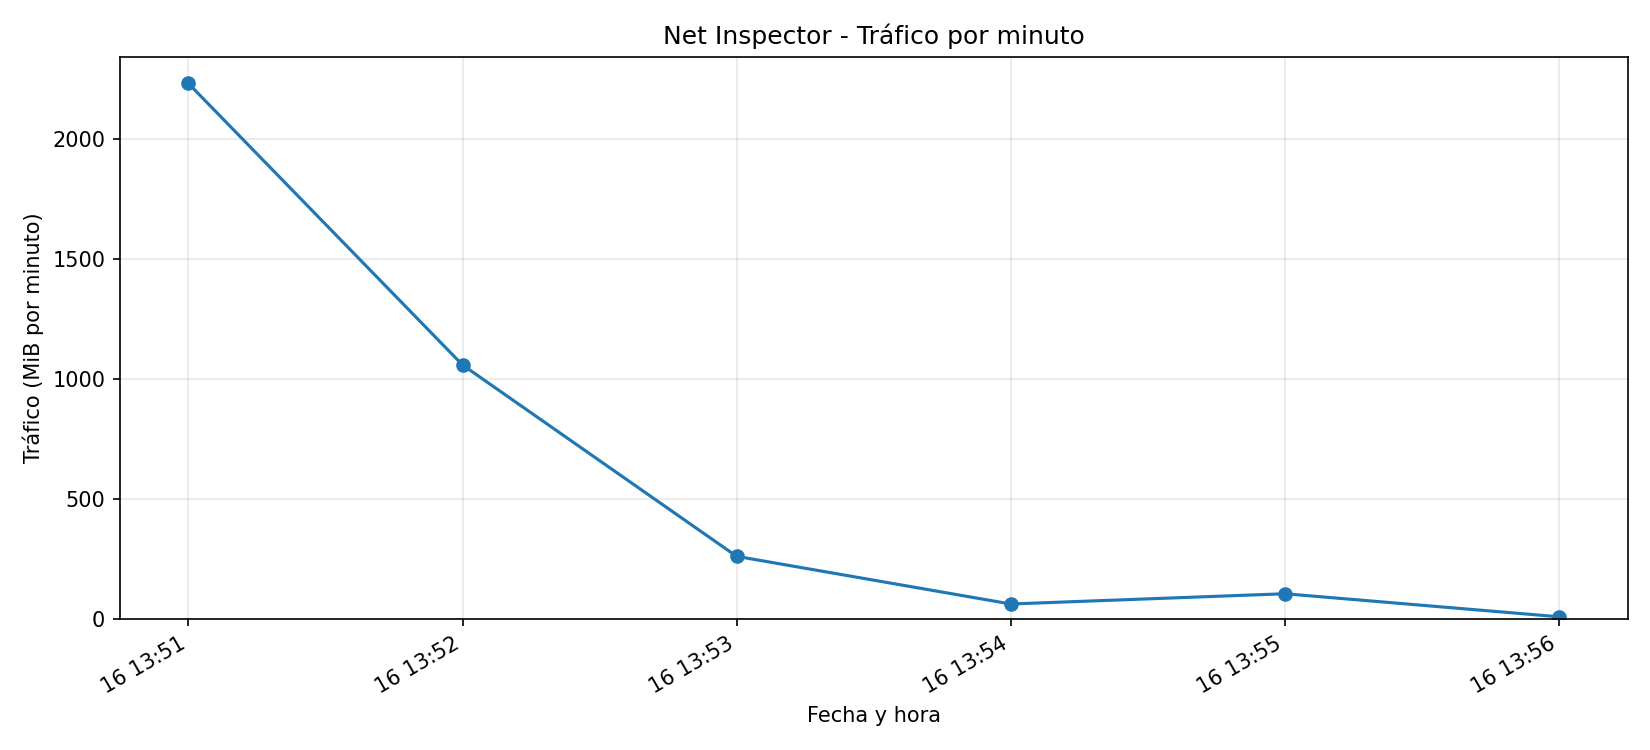

In [ ]:
from IPython.display import Image, display

display(
    Image(
        filename="/content/visualizer/trafico_por_minuto_integracion.png"
    )
)

In [ ]:
import sqlite3
from pathlib import Path

# Localizar la base de datos más reciente
bases = list(
    Path("/content").glob("net_inspector_integracion_*.db")
)

ruta_db = max(
    bases,
    key=lambda archivo: archivo.stat().st_mtime
)

with sqlite3.connect(ruta_db) as db:

    # Contar conexiones almacenadas
    total = db.execute("""
        SELECT COUNT(*)
        FROM conexiones
    """).fetchone()[0]

    # Agrupar conexiones y bytes por minuto
    resultados = db.execute("""
        SELECT
            SUBSTR(fecha_hora, 1, 16) AS minuto,
            COUNT(*) AS conexiones,
            ROUND(SUM(bytes_transmitidos) / 1048576.0, 2)
                AS total_mib
        FROM conexiones
        GROUP BY SUBSTR(fecha_hora, 1, 16)
        ORDER BY minuto
    """).fetchall()

print("===== VALIDACIÓN NET INSPECTOR =====")
print("Base de datos:", ruta_db.name)
print("Conexiones almacenadas:", total)
print("Minutos representados:", len(resultados))

print("\nDISTRIBUCIÓN TEMPORAL:\n")

for minuto, conexiones, mib in resultados:
    print(
        f"{minuto} | "
        f"Conexiones: {conexiones} | "
        f"Tráfico: {mib} MiB"
    )

===== VALIDACIÓN NET INSPECTOR =====
Base de datos: net_inspector_integracion_20261117_231150_129509.db
Conexiones almacenadas: 30000
Minutos representados: 6

DISTRIBUCIÓN TEMPORAL:

2011/08/16 13:51 | Conexiones: 6039 | Tráfico: 2232.04 MiB
2011/08/16 13:52 | Conexiones: 6691 | Tráfico: 1058.67 MiB
2011/08/16 13:53 | Conexiones: 5501 | Tráfico: 260.79 MiB
2011/08/16 13:54 | Conexiones: 5209 | Tráfico: 62.1 MiB
2011/08/16 13:55 | Conexiones: 5224 | Tráfico: 104.86 MiB
2011/08/16 13:56 | Conexiones: 1336 | Tráfico: 8.83 MiB


In [ ]:
from pathlib import Path
import shutil
import ast

archivo = Path("/content/main.py")

codigo = archivo.read_text(encoding="utf-8")

# Configuración anterior
anterior = "    limite = 30000"

# Configuración nueva
nuevo = "    limite = None  # Procesar todos los registros"

if codigo.count(anterior) != 1:
    raise ValueError("No se encontró la configuración esperada.")

# Preparar modificación
codigo_nuevo = codigo.replace(anterior, nuevo)

# Comprobar sintaxis antes de guardar
ast.parse(codigo_nuevo)

# Respaldar versión anterior
respaldo = Path("/content/main_30000_registros.py")
shutil.copy2(archivo, respaldo)

# Guardar modificación
archivo.write_text(codigo_nuevo, encoding="utf-8")

print("Configuración actualizada correctamente.")
print("Modo: procesamiento completo del dataset.")
print("Respaldo creado:", respaldo.name)

Configuración actualizada correctamente.
Modo: procesamiento completo del dataset.
Respaldo creado: main_30000_registros.py


In [ ]:
%run /content/main.py

       NET INSPECTOR
Conexiones procesadas: 114077
Alertas detectadas: 35
--------------------------------
Conexiones almacenadas: 114077
Bytes registrados: 6085522848
Base de datos: net_inspector_integracion_20261117_232248_904485.db
--------------------------------
Gráfica guardada en: visualizer/protocolos_integracion.png
Gráfica de puertos: /content/visualizer/puertos_destino_integracion.png
Minutos representados: 22
Gráfica temporal: /content/visualizer/trafico_por_minuto_integracion.png
Análisis finalizado correctamente


<Figure size 640x480 with 0 Axes>

===== AUDITORÍA NET INSPECTOR =====
Base de datos: net_inspector_integracion_20261117_232248_904485.db
Conexiones: 114077
Bytes: 6085522848
Minutos: 22

VALIDACIÓN EXITOSA

Visualizaciones:
OK: protocolos_integracion.png
OK: puertos_destino_integracion.png
OK: trafico_por_minuto_integracion.png


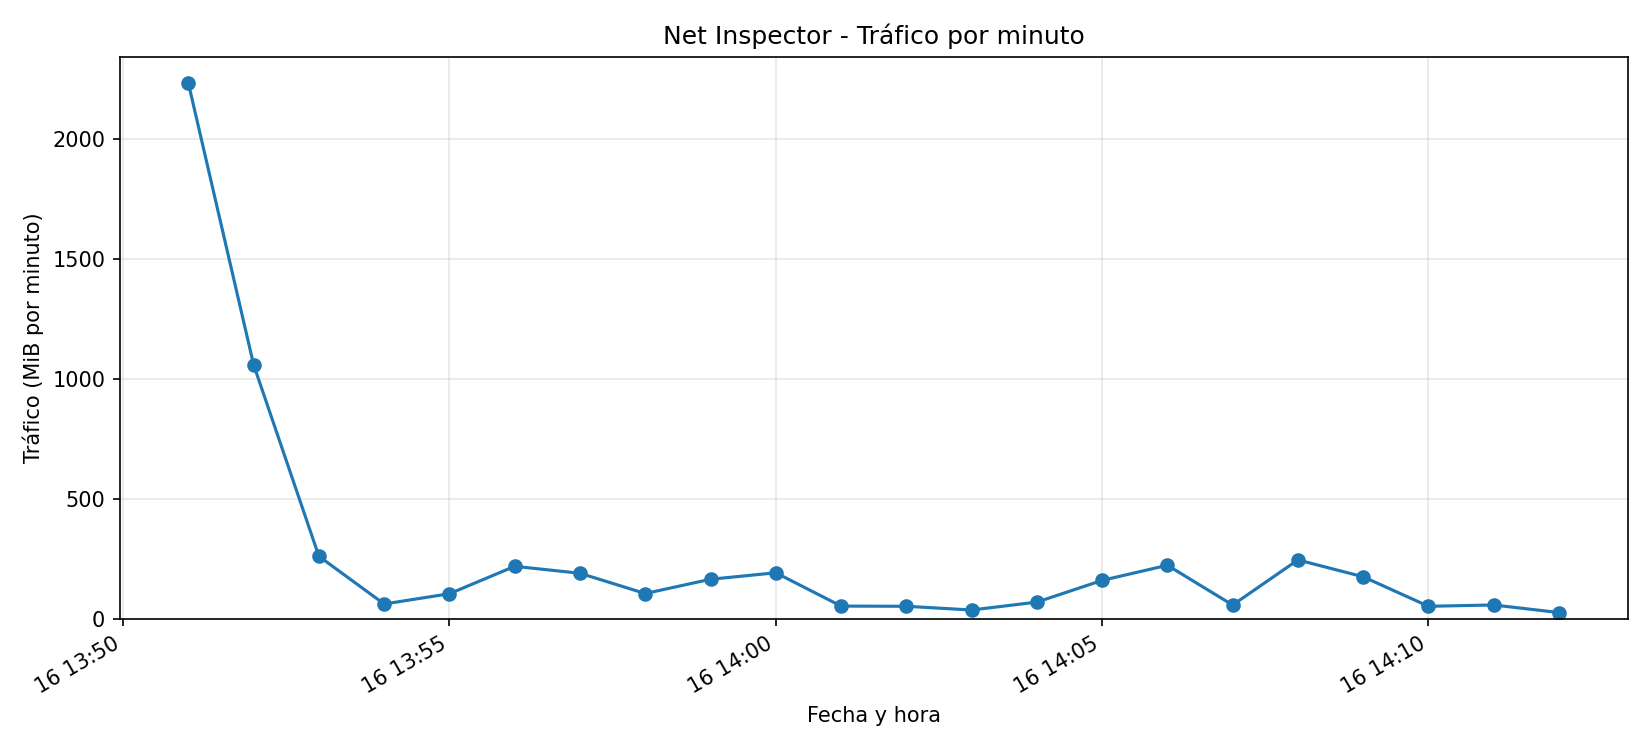

In [ ]:
import sqlite3
from pathlib import Path
from IPython.display import Image, display

# Localizar la base de datos más reciente
bases = list(
    Path("/content").glob("net_inspector_integracion_*.db")
)

ruta_db = max(
    bases,
    key=lambda archivo: archivo.stat().st_mtime
)

# Consultar los datos almacenados
with sqlite3.connect(ruta_db) as db:

    total, bytes_total = db.execute("""
        SELECT
            COUNT(*),
            SUM(bytes_transmitidos)
        FROM conexiones
    """).fetchone()

    minutos = db.execute("""
        SELECT COUNT(DISTINCT SUBSTR(fecha_hora, 1, 16))
        FROM conexiones
    """).fetchone()[0]

print("===== AUDITORÍA NET INSPECTOR =====")

print("Base de datos:", ruta_db.name)
print("Conexiones:", total)
print("Bytes:", bytes_total)
print("Minutos:", minutos)

# Verificar resultados
if (
    total == 114077
    and bytes_total == 6085522848
    and minutos == 22
):
    print("\nVALIDACIÓN EXITOSA")
else:
    print("\nREVISAR RESULTADOS")

# Comprobar las tres gráficas
imagenes = [
    "protocolos_integracion.png",
    "puertos_destino_integracion.png",
    "trafico_por_minuto_integracion.png"
]

print("\nVisualizaciones:")

for nombre in imagenes:

    ruta = Path("/content/visualizer") / nombre

    if ruta.exists():
        print("OK:", nombre)
    else:
        print("FALTA:", nombre)

# Mostrar gráfica temporal completa
ruta_grafica = Path(
    "/content/visualizer/trafico_por_minuto_integracion.png"
)

if ruta_grafica.exists():
    display(Image(filename=str(ruta_grafica)))

In [10]:
import ipywidgets as widgets
from IPython.display import display, Image, clear_output
from pathlib import Path
import sqlite3

# Localizar la base de datos más reciente
bases = list(
    Path("/content").glob("net_inspector_integracion_*.db")
)

if not bases:
    raise FileNotFoundError("No se encontró una base de datos.")

ruta_db = max(
    bases,
    key=lambda archivo: archivo.stat().st_mtime
)

# Consultar estadísticas
with sqlite3.connect(ruta_db) as db:

    total, bytes_total = db.execute("""
        SELECT COUNT(*), SUM(bytes_transmitidos)
        FROM conexiones
    """).fetchone()

# Visualizaciones disponibles
graficas = {
    "Distribución de protocolos":
        "/content/visualizer/protocolos_integracion.png",

    "Puertos de destino":
        "/content/visualizer/puertos_destino_integracion.png",

    "Tráfico por minuto":
        "/content/visualizer/trafico_por_minuto_integracion.png"
}

# Crear título
titulo = widgets.HTML(
    "<h2>NET INSPECTOR</h2>"
    "<h4>Panel de análisis de tráfico de red</h4>"
)

# Mostrar estadísticas
estadisticas = widgets.HTML(
    f"<b>Conexiones analizadas:</b> {total:,}<br>"
    f"<b>Bytes registrados:</b> {bytes_total:,}<br>"
    f"<b>Base de datos:</b> {ruta_db.name}"
)

# Menú para seleccionar gráfica
selector = widgets.Dropdown(
    options=list(graficas.keys()),
    description="Gráfica:",
    style={"description_width": "initial"}
)

# Botón
boton = widgets.Button(
    description="Mostrar gráfica",
    button_style="primary"
)

# Área de resultados
salida = widgets.Output()

# Función del botón
def mostrar_grafica(b=None):

    with salida:

        clear_output(wait=True)

        nombre = selector.value
        ruta = Path(graficas[nombre])

        if ruta.exists():

            print("Visualización:", nombre)

            display(
                Image(filename=str(ruta), width=850)
            )

        else:
            print("No se encontró la gráfica.")

# Asociar botón con función
boton.on_click(mostrar_grafica)

# Construir interfaz
interfaz = widgets.VBox([
    titulo,
    estadisticas,
    selector,
    boton,
    salida
])

display(interfaz)

# Mostrar primera gráfica automáticamente
mostrar_grafica()

In [ ]:
titulo.value = """
<div style="font-family:Arial; padding:15px 0;">

    <h1 style="color:#163B65; margin-bottom:5px;">
        ACV NetLab
    </h1>

    <h3 style="color:#444; margin-top:0;">
        Laboratorio de Análisis de Tráfico y Seguridad de Redes
    </h3>

    <hr>

    <p>
        <b>Proyecto académico</b><br>
        Maestría en Ciencias y Tecnologías Computacionales<br>
        Universidad Autónoma de Tamaulipas (UAT)
    </p>

    <p>
        <b>Desarrollado por:</b> Alberto Carlos Vázquez
    </p>

    <hr>

</div>
"""

In [ ]:
from pathlib import Path
import shutil
import re
import ast

archivo = Path("/content/main.py")
codigo = archivo.read_text(encoding="utf-8")

# Nueva definición de la función principal
definicion_original = "def main():"

definicion_nueva = '''def main(
    archivo="ctu13_escenario7.binetflow",
    limite=None,
    umbral=100,
    ventana=60
):'''

# Localizar la configuración anterior
patron = (
    r"(?m)^    archivo = .*?\n"
    r"    limite = .*?\n"
    r"    umbral = .*?\n"
    r"    ventana = .*?\n"
)

if codigo.count(definicion_original) != 1:
    raise ValueError("No se encontró la función principal esperada.")

codigo_nuevo = codigo.replace(
    definicion_original,
    definicion_nueva
)

codigo_nuevo, cambios = re.subn(
    patron,
    "",
    codigo_nuevo
)

if cambios != 1:
    raise ValueError("No se encontró la configuración esperada.")

# Verificar sintaxis
ast.parse(codigo_nuevo)

# Crear respaldo
shutil.copy2(
    archivo,
    "/content/main_antes_interfaz.py"
)

# Guardar modificación
archivo.write_text(codigo_nuevo, encoding="utf-8")

print("Función principal actualizada correctamente.")
print("Ahora admite parámetros configurables.")

Función principal actualizada correctamente.
Ahora admite parámetros configurables.


In [ ]:
import importlib
import main as net_inspector

importlib.reload(net_inspector)

# Prueba controlada de 1,000 conexiones
net_inspector.main(limite=1000)

       NET INSPECTOR
Conexiones procesadas: 1000
Alertas detectadas: 1
--------------------------------
Conexiones almacenadas: 1000
Bytes registrados: 1540799127
Base de datos: net_inspector_integracion_20261117_233705_690501.db
--------------------------------
Gráfica guardada en: visualizer/protocolos_integracion.png
Gráfica de puertos: /content/visualizer/puertos_destino_integracion.png
Minutos representados: 1
Gráfica temporal: /content/visualizer/trafico_por_minuto_integracion.png
Análisis finalizado correctamente


In [ ]:
from pathlib import Path
import shutil
import ast

archivo = Path("/content/main.py")
codigo = archivo.read_text(encoding="utf-8")

punto = '    print("Análisis finalizado correctamente")'

retorno = '''

    return {
        "base_datos": ruta_db,
        "conexiones": cantidad,
        "bytes": total_bytes,
        "alertas": len(alertas),
        "graficas": {
            "Protocolos": str(ruta_grafica) if ruta_grafica else None,
            "Puertos": str(ruta_grafica_puertos) if ruta_grafica_puertos else None,
            "Tráfico temporal": str(ruta_grafica_trafico) if ruta_grafica_trafico else None
        }
    }
'''

if '    return {\n        "base_datos": ruta_db,' not in codigo:

    if codigo.count(punto) != 1:
        raise ValueError("No se encontró el punto de modificación.")

    codigo_nuevo = codigo.replace(
        punto,
        punto + retorno
    )

    ast.parse(codigo_nuevo)

    shutil.copy2(
        archivo,
        "/content/main_antes_resultados.py"
    )

    archivo.write_text(
        codigo_nuevo,
        encoding="utf-8"
    )

    print("Motor actualizado correctamente.")

else:
    print("El motor ya devuelve resultados.")

Motor actualizado correctamente.


In [11]:
import importlib
from pathlib import Path

import ipywidgets as widgets
from IPython.display import display, Image, clear_output

import main as net_inspector

importlib.reload(net_inspector)

# Archivos disponibles
archivos = sorted(
    p.name for p in Path("/content").glob("*.binetflow")
)

if not archivos:
    raise FileNotFoundError("No se encontraron archivos de tráfico.")

# Controles
selector_archivo = widgets.Dropdown(
    options=archivos,
    description="Archivo:",
    style={"description_width": "initial"}
)

limite_registros = widgets.BoundedIntText(
    value=1000,
    min=1,
    max=1000000,
    description="Conexiones:"
)

analizar_todo = widgets.Checkbox(
    value=False,
    description="Analizar archivo completo"
)

control_umbral = widgets.BoundedIntText(
    value=100,
    min=1,
    max=1000000,
    description="Umbral:"
)

control_ventana = widgets.BoundedIntText(
    value=60,
    min=1,
    max=86400,
    description="Ventana (s):"
)

boton_analizar = widgets.Button(
    description="Ejecutar análisis",
    button_style="success",
    icon="play"
)

selector_grafica = widgets.Dropdown(
    options=["Protocolos", "Puertos", "Tráfico temporal"],
    description="Visualización:"
)

boton_grafica = widgets.Button(
    description="Mostrar gráfica",
    button_style="primary"
)

estado = widgets.HTML("<b>Estado:</b> Listo para analizar.")

estadisticas = widgets.HTML("")

salida_programa = widgets.Output()
salida_grafica = widgets.Output()

resultado_actual = {}

# Mostrar gráfica seleccionada
def mostrar_visualizacion(b=None):

    with salida_grafica:
        clear_output(wait=True)

        datos = resultado_actual.get("datos")

        if datos is None:
            print("Primero ejecuta un análisis.")
            return

        ruta = datos["graficas"].get(selector_grafica.value)

        if ruta and Path(ruta).exists():
            display(Image(filename=ruta, width=850))
        else:
            print("No se encontró la visualización.")

# Ejecutar el motor
def ejecutar_analisis(b):

    boton_analizar.disabled = True
    estado.value = "<b>Estado:</b> Procesando..."

    try:
        limite = (
            None if analizar_todo.value
            else limite_registros.value
        )

        with salida_programa:
            clear_output(wait=True)

            resultado = net_inspector.main(
                archivo=str(
                    Path("/content") / selector_archivo.value
                ),
                limite=limite,
                umbral=control_umbral.value,
                ventana=control_ventana.value
            )

        if resultado is None:
            raise RuntimeError("El motor no devolvió resultados.")

        resultado_actual["datos"] = resultado

        estadisticas.value = f"""
        <h3>Resultados del análisis</h3>
        <b>Conexiones:</b> {resultado['conexiones']:,}<br>
        <b>Bytes:</b> {resultado['bytes']:,}<br>
        <b>Alertas experimentales:</b> {resultado['alertas']:,}<br>
        <b>Base de datos:</b> {resultado['base_datos']}
        """

        estado.value = "<b>Estado:</b> Análisis completado."

        mostrar_visualizacion()

    except Exception as error:

        estado.value = "<b>Estado:</b> Error durante el análisis."

        with salida_programa:
            print("Error:", error)

    finally:
        boton_analizar.disabled = False

# Asociar eventos
boton_analizar.on_click(ejecutar_analisis)
boton_grafica.on_click(mostrar_visualizacion)

# Interfaz principal
panel = widgets.VBox([
    widgets.HTML("""
        <h1>ACV NetLab</h1>
        <h3>Laboratorio de Análisis de Tráfico y Seguridad de Redes</h3>
        <p>
        Maestría en Ciencias y Tecnologías Computacionales<br>
        Universidad Autónoma de Tamaulipas<br>
        <b>Alberto Carlos Vázquez</b>
        </p>
        <hr>
    """),

    widgets.HTML("<h3>Configuración del análisis</h3>"),

    selector_archivo,
    limite_registros,
    analizar_todo,
    control_umbral,
    control_ventana,
    boton_analizar,

    estado,
    estadisticas,

    widgets.HTML("<h3>Visualizaciones</h3>"),

    selector_grafica,
    boton_grafica,
    salida_grafica,

    widgets.HTML("<h3>Registro de ejecución</h3>"),
    salida_programa
])

display(panel)

In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from datetime import datetime
from google.colab import files
import sqlite3

base = Path("/content")

fecha = datetime.now().strftime("%Y-%m-%d_%H%M")

nombre_zip = f"ACV_NetLab_respaldo_{fecha}.zip"
ruta_zip = base / nombre_zip

# Identificar la base de datos con 114,077 conexiones
base_completa = None

for ruta in sorted(base.glob("net_inspector_integracion_*.db")):
    with sqlite3.connect(ruta) as db:
        cantidad = db.execute(
            "SELECT COUNT(*) FROM conexiones"
        ).fetchone()[0]

    if cantidad == 114077:
        base_completa = ruta
        break

if base_completa is None:
    raise FileNotFoundError(
        "No se encontró la base de datos de la prueba completa."
    )

# Seleccionar los archivos necesarios
archivos = [
    base / "main.py",
    base / "ctu13_escenario7.binetflow",
    base / "ESTADO_NET_INSPECTOR.txt",
    base_completa
]

# Incorporar los módulos Python
for carpeta in [
    "log_engine",
    "security_core",
    "db_manager",
    "visualizer"
]:
    archivos.extend((base / carpeta).glob("*.py"))

# Incorporar las visualizaciones
archivos.extend((base / "visualizer").glob("*.png"))

# Crear respaldo
with ZipFile(ruta_zip, "w", ZIP_DEFLATED) as zipf:

    for archivo in archivos:
        if archivo.exists():
            zipf.write(
                archivo,
                arcname=archivo.relative_to(base)
            )

print("Respaldo generado:", nombre_zip)
print("Base de datos conservada:", base_completa.name)

# Descargar a la computadora
files.download(str(ruta_zip))

Respaldo generado: ACV_NetLab_respaldo_2026-11-17_2342.zip
Base de datos conservada: net_inspector_integracion_20261117_232248_904485.db


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

archivos = [
    "/content/security_core/conexion_red.py",
    "/content/security_core/detector_anomalias.py"
]

for archivo in archivos:

    ruta = Path(archivo)

    print("\n" + "=" * 60)
    print("ARCHIVO:", ruta.name)
    print("=" * 60)

    if ruta.exists():

        lineas = ruta.read_text(
            encoding="utf-8"
        ).splitlines()

        for numero, linea in enumerate(lineas, start=1):
            print(f"{numero:3} | {linea}")

    else:
        print("Archivo no encontrado.")


ARCHIVO: conexion_red.py
  1 | 
  2 | class ConexionRed:
  3 | 
  4 |     def __init__(self, fecha_hora, ip_origen, ip_destino,
  5 |                  puerto_destino, protocolo, bytes_transmitidos):
  6 | 
  7 |         self.fecha_hora = fecha_hora
  8 |         self.ip_origen = ip_origen
  9 |         self.ip_destino = ip_destino
 10 |         self.puerto_destino = puerto_destino
 11 |         self.protocolo = protocolo
 12 |         self.bytes_transmitidos = bytes_transmitidos

ARCHIVO: detector_anomalias.py
  1 | 
  2 | from collections import defaultdict, deque
  3 | from datetime import datetime, timedelta
  4 | 
  5 | 
  6 | class DetectorAnomalias:
  7 | 
  8 |     def __init__(self, umbral_flujos=100, ventana_segundos=60):
  9 |         self.umbral_flujos = umbral_flujos
 10 |         self.ventana = timedelta(seconds=ventana_segundos)
 11 | 
 12 |     def detectar_rafagas(self, conexiones):
 13 | 
 14 |         ventanas = defaultdict(deque)
 15 |         alertados = set()
 16 

In [ ]:
from security_core.conexion_red import ConexionRed

conexion_1 = ConexionRed(
    fecha_hora="2011/08/16 13:51:24.049047",
    ip_origen="192.168.1.10",
    ip_destino="8.8.8.8",
    puerto_destino=53,
    protocolo="udp",
    bytes_transmitidos=1500
)

print("Origen:", conexion_1.ip_origen)
print("Destino:", conexion_1.ip_destino)
print("Protocolo:", conexion_1.protocolo)
print("Bytes:", conexion_1.bytes_transmitidos)

Origen: 192.168.1.10
Destino: 8.8.8.8
Protocolo: udp
Bytes: 1500


In [ ]:
conexion_1.ip_destino = "192.168.1.20"

print(conexion_1.ip_destino)


conexion_1.protocolo ="tcp"

print(conexion_1.protocolo)

192.168.1.20
tcp


In [ ]:
from security_core.conexion_red import ConexionRed

conexion_2 = ConexionRed(
    fecha_hora="2011/08/16 13:51:24.049047",
    ip_origen="192.168.1.30",
    ip_destino="8.8.8.8",
    puerto_destino=53,
    protocolo="udp",
    bytes_transmitidos=1500
)

print("cámara 1:", conexion_1.ip_origen)
print("camara 2:", conexion_2.ip_origen)


cámara 1: 192.168.1.10
camara 2: 192.168.1.30


In [ ]:
conexion_2.ip_origen = "192.168.1.50"

print("Objeto 1:")
print(vars(conexion_1))

print("\nObjeto 2:")
print(vars(conexion_2))

Objeto 1:
{'fecha_hora': '2011/08/16 13:51:24.049047', 'ip_origen': '192.168.1.10', 'ip_destino': '192.168.1.20', 'puerto_destino': 53, 'protocolo': 'tcp', 'bytes_transmitidos': 1500, 'ip': '192.168.1.20'}

Objeto 2:
{'fecha_hora': '2011/08/16 13:51:24.049047', 'ip_origen': '192.168.1.50', 'ip_destino': '8.8.8.8', 'puerto_destino': 53, 'protocolo': 'udp', 'bytes_transmitidos': 1500}


In [ ]:
class Camara:

    def __init__(self, nombre_recibido):
        self.nombre = nombre_recibido

    def mostrar_nombre(self):
        print(self.nombre)

    def cambiar_nombre(self, nuevo_nombre):
        self.nombre = nuevo_nombre

    def mostrar_estado(self):
        print("La cámara", self.nombre, "está registrada.")


camara_1 = Camara("Patio")
camara_2 = Camara("Cochera")

camara_1.cambiar_nombre("Jardín")
camara_2.cambiar_nombre("Entrada principal")

camara_1.mostrar_nombre()
camara_2.mostrar_nombre()

camara_1.mostrar_estado()
camara_2.mostrar_estado()

camara_1.cambiar_nombre("estacionamiento")
camara_1.mostrar_estado()

Jardín
Entrada principal
La cámara Jardín está registrada.
La cámara Entrada principal está registrada.
La cámara estacionamiento está registrada.


In [ ]:
from pathlib import Path

print("Archivo principal:", Path("/content/main.py").exists())
print("Clase ConexionRed:", Path("/content/security_core/conexion_red.py").exists())
print("Dataset CTU-13:", Path("/content/ctu13_escenario7.binetflow").exists())


Archivo principal: False
Clase ConexionRed: False
Dataset CTU-13: False


In [ ]:
from pathlib import Path
import zipfile

carpeta = Path("/content")

respaldos = sorted(
    carpeta.glob("ACV_NetLab_respaldo_*.zip"),
    key=lambda archivo: archivo.stat().st_mtime,
    reverse=True
)

if not respaldos:
    print("No se encontró el respaldo ZIP de ACV NetLab.")
else:
    respaldo = respaldos[0]
    print("Respaldo encontrado:", respaldo.name)

    with zipfile.ZipFile(respaldo, "r") as zip_ref:
        zip_ref.extractall(carpeta)

    print("Archivos restaurados.")
    print("main.py:", (carpeta / "main.py").exists())
    print("conexion_red.py:", (carpeta / "security_core/conexion_red.py").exists())
    print("Dataset CTU-13:", (carpeta / "ctu13_escenario7.binetflow").exists())

Respaldo encontrado: ACV_NetLab_respaldo_2026-11-17_2342.zip
Archivos restaurados.
main.py: True
conexion_red.py: True
Dataset CTU-13: True


In [ ]:
class DetectorAnomalias:

    def __init__(self, umbral_flujos=100, ventana_segundos=60):
        self.umbral_flujos = umbral_flujos
        self.ventana = timedelta(seconds=ventana_segundos)

In [ ]:
from security_core.detector_anomalias import DetectorAnomalias

detector_1 = DetectorAnomalias(
    umbral_flujos=6,
    ventana_segundos=30
)

print("Umbral:", detector_1.umbral_flujos)
print("Ventana:", detector_1.ventana)


detector_2 = DetectorAnomalias(
    umbral_flujos=200,
    ventana_segundos=60
)

print("Umbral:", detector_2.umbral_flujos)
print("Ventana:", detector_2.ventana)

Umbral: 6
Ventana: 0:00:30
Umbral: 200
Ventana: 0:01:00


In [ ]:
detector_1.umbral_flujos = 10
print(detector_1.umbral_flujos)

10


In [ ]:
import main

resultado = main.main(limite=1000)

print("\nRESULTADO DEL ANÁLISIS:")
print(resultado)

       NET INSPECTOR
Conexiones procesadas: 1000
Alertas detectadas: 1
--------------------------------
Conexiones almacenadas: 1000
Bytes registrados: 1540799127
Base de datos: net_inspector_integracion_20261118_041121_729222.db
--------------------------------
Gráfica guardada en: visualizer/protocolos_integracion.png
Gráfica de puertos: /content/visualizer/puertos_destino_integracion.png
Minutos representados: 1
Gráfica temporal: /content/visualizer/trafico_por_minuto_integracion.png
Análisis finalizado correctamente

RESULTADO DEL ANÁLISIS:
{'base_datos': 'net_inspector_integracion_20261118_041121_729222.db', 'conexiones': 1000, 'bytes': 1540799127, 'alertas': 1, 'graficas': {'Protocolos': 'visualizer/protocolos_integracion.png', 'Puertos': '/content/visualizer/puertos_destino_integracion.png', 'Tráfico temporal': '/content/visualizer/trafico_por_minuto_integracion.png'}}


In [ ]:
from pathlib import Path
import sqlite3

ruta_db = Path(resultado["base_datos"])

print("=== VERIFICACIÓN DE BASE DE DATOS ===")
print("Archivo encontrado:", ruta_db.exists())

if ruta_db.exists():
    with sqlite3.connect(ruta_db) as conexion:
        tablas = conexion.execute(
            "SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%'"
        ).fetchall()

        for (tabla,) in tablas:
            nombre_seguro = tabla.replace('"', '""')
            cantidad = conexion.execute(
                f'SELECT COUNT(*) FROM "{nombre_seguro}"'
            ).fetchone()[0]

            print(f"{tabla}: {cantidad} registros")

print("\n=== VERIFICACIÓN DE GRÁFICAS ===")

for nombre, archivo in resultado["graficas"].items():
    ruta = Path(archivo)
    print(nombre, ":", "Existe" if ruta.is_file() else "No encontrada")

=== VERIFICACIÓN DE BASE DE DATOS ===
Archivo encontrado: True
conexiones: 1000 registros
incidentes: 1 registros

=== VERIFICACIÓN DE GRÁFICAS ===
Protocolos : Existe
Puertos : Existe
Tráfico temporal : Existe


In [ ]:
%%writefile /content/security_core/host.py

class Host:

    def __init__(self, ip):
        self.ip = ip
        self.total_conexiones = 0
        self.total_bytes = 0

    def registrar_conexion(self, conexion):

        if conexion.ip_origen != self.ip:
            raise ValueError("La conexión no pertenece a este host")

        self.total_conexiones += 1
        self.total_bytes += int(conexion.bytes_transmitidos)

    def mostrar_resumen(self):

        print("IP:", self.ip)
        print("Conexiones:", self.total_conexiones)
        print("Bytes:", self.total_bytes)

Writing /content/security_core/host.py


In [ ]:
from security_core.host import Host
from security_core.conexion_red import ConexionRed

# Creamos un dispositivo de red
host_1 = Host("192.168.1.10")

# Creamos una conexión de ese dispositivo
conexion_prueba = ConexionRed(
    fecha_hora="2011/08/16 13:51:24.049047",
    ip_origen="192.168.1.10",
    ip_destino="8.8.8.8",
    puerto_destino=53,
    protocolo="udp",
    bytes_transmitidos=1500
)

# Registramos la conexión
host_1.registrar_conexion(conexion_prueba)

# Mostramos los resultados
host_1.mostrar_resumen()

IP: 192.168.1.10
Conexiones: 1
Bytes: 1500


In [ ]:
from itertools import islice

from log_engine.lector_ctu13 import leer_ctu13
from log_engine.normalizador import convertir_ctu13
from security_core.host import Host

hosts = {}

registros = leer_ctu13("ctu13_escenario7.binetflow")

for registro in islice(registros, 1000):

    conexion = convertir_ctu13(registro)
    ip = conexion.ip_origen

    if ip not in hosts:
        hosts[ip] = Host(ip)

    hosts[ip].registrar_conexion(conexion)

print("Hosts identificados:", len(hosts))

ordenados = sorted(
    hosts.values(),
    key=lambda host: host.total_conexiones,
    reverse=True
)

print("\n=== CINCO HOSTS CON MÁS CONEXIONES ===")

for host in ordenados[:5]:
    print(
        "IP:", host.ip,
        "| Conexiones:", host.total_conexiones,
        "| Bytes:", host.total_bytes
    )

Hosts identificados: 364

=== CINCO HOSTS CON MÁS CONEXIONES ===
IP: 147.32.84.59 | Conexiones: 249 | Bytes: 201488073
IP: 147.32.84.138 | Conexiones: 92 | Bytes: 684928
IP: 147.32.84.229 | Conexiones: 81 | Bytes: 449237
IP: 147.32.84.94 | Conexiones: 42 | Bytes: 1393536
IP: 147.32.86.50 | Conexiones: 19 | Bytes: 49845


In [ ]:
from pathlib import Path
from shutil import copy2

original = Path("/content/main.py")
respaldo = Path("/content/main_antes_hosts.py")

copy2(original, respaldo)

print("Copia creada:", respaldo.exists())

Copia creada: True


In [ ]:
import importlib
import main

importlib.reload(main)

resultado = main.main(limite=1000)

       NET INSPECTOR
Conexiones procesadas: 1000

=== CINCO HOSTS CON MÁS CONEXIONES ===
IP: 147.32.84.59 | Conexiones: 249 | Bytes: 201488073
IP: 147.32.84.138 | Conexiones: 92 | Bytes: 684928
IP: 147.32.84.229 | Conexiones: 81 | Bytes: 449237
IP: 147.32.84.94 | Conexiones: 42 | Bytes: 1393536
IP: 147.32.86.50 | Conexiones: 19 | Bytes: 49845
Alertas detectadas: 1
--------------------------------
Conexiones almacenadas: 1000
Bytes registrados: 1540799127
Base de datos: net_inspector_integracion_20261118_042819_565127.db
--------------------------------
Gráfica guardada en: visualizer/protocolos_integracion.png
Gráfica de puertos: /content/visualizer/puertos_destino_integracion.png
Minutos representados: 1
Gráfica temporal: /content/visualizer/trafico_por_minuto_integracion.png
Análisis finalizado correctamente


In [ ]:
from pathlib import Path
from datetime import datetime
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

raiz = Path("/content")

nombre = f"ACV_NetLab_respaldo_{datetime.now():%Y-%m-%d_%H%M}.zip"
respaldo = raiz / nombre

archivos = [
    raiz / "main.py",
    raiz / "main_antes_hosts.py",
    raiz / "ctu13_escenario7.binetflow"
]

for carpeta in ["log_engine", "security_core", "db_manager", "visualizer"]:
    ruta = raiz / carpeta

    if ruta.exists():
        archivos.extend(
            archivo for archivo in ruta.rglob("*")
            if archivo.is_file()
            and "__pycache__" not in archivo.parts
            and archivo.suffix in [".py", ".png"]
        )

# Conservar la base de datos más reciente
bases = sorted(
    raiz.glob("net_inspector_integracion_*.db"),
    key=lambda archivo: archivo.stat().st_mtime,
    reverse=True
)

if bases:
    archivos.append(bases[0])

with ZipFile(respaldo, "w", ZIP_DEFLATED) as zip_ref:
    for archivo in archivos:
        if archivo.exists():
            zip_ref.write(archivo, archivo.relative_to(raiz))

print("Respaldo generado:", respaldo.name)

with ZipFile(respaldo) as zip_ref:
    nombres = zip_ref.namelist()
    print("main.py incluido:", "main.py" in nombres)
    print("host.py incluido:", "security_core/host.py" in nombres)
    print("Archivos incluidos:", len(nombres))

files.download(str(respaldo))

Respaldo generado: ACV_NetLab_respaldo_2026-11-18_0430.zip
main.py incluido: True
host.py incluido: True
Archivos incluidos: 16


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

archivos = [
    "/content/log_engine/lector_ctu13.py",
    "/content/log_engine/normalizador.py"
]

for archivo in archivos:
    ruta = Path(archivo)

    print("\n" + "=" * 50)
    print("ARCHIVO:", ruta.name)
    print("=" * 50)

    if ruta.exists():
        lineas = ruta.read_text(encoding="utf-8").splitlines()

        for numero, linea in enumerate(lineas, start=1):
            print(f"{numero:3} | {linea}")
    else:
        print("Archivo no encontrado")


ARCHIVO: lector_ctu13.py
  1 | 
  2 | import csv
  3 | 
  4 | def leer_ctu13(ruta_archivo):
  5 |     with open(ruta_archivo, "r", encoding="utf-8", newline="") as archivo:
  6 |         lector = csv.DictReader(archivo)
  7 | 
  8 |         for registro in lector:
  9 |             yield registro

ARCHIVO: normalizador.py
  1 | 
  2 | from security_core.conexion_red import ConexionRed
  3 | 
  4 | 
  5 | def convertir_ctu13(registro):
  6 | 
  7 |     return ConexionRed(
  8 |         fecha_hora=registro["StartTime"],
  9 |         ip_origen=registro["SrcAddr"],
 10 |         ip_destino=registro["DstAddr"],
 11 |         puerto_destino=registro["Dport"],
 12 |         protocolo=registro["Proto"],
 13 |         bytes_transmitidos=int(registro["TotBytes"])
 14 |     )
 15 | 
 16 | 
 17 | def convertir_generico(registro):
 18 |     return ConexionRed(
 19 |         fecha_hora=registro["timestamp"],
 20 |         ip_origen=registro["src_ip"],
 21 |         ip_destino=registro["dst_ip"],
 

In [ ]:
from log_engine.normalizador import convertir_ctu13

registro_prueba = {
    "StartTime": "2011/08/16 13:51:24.049047",
    "SrcAddr": "192.168.1.10",
    "DstAddr": "8.8.8.8",
    "Dport": "53",
    "Proto": "udp",
    "TotBytes": "desconocido"
}

try:
    conexion = convertir_ctu13(registro_prueba)
    print("Registro procesado correctamente")

except ValueError as error:
    print("Se detectó un dato incorrecto:")
    print(error)

Se detectó un dato incorrecto:
invalid literal for int() with base 10: 'desconocido'


In [ ]:
from pathlib import Path
from shutil import copy2

archivo = Path("/content/main.py")

# Crear una copia antes de modificar
copy2(archivo, "/content/main_antes_validaciones.py")

print("=== CÓDIGO ACTUAL ===")

lineas = archivo.read_text(encoding="utf-8").splitlines()

for numero, linea in enumerate(lineas, start=1):
    if 25 <= numero <= 60:
        print(f"{numero:3} | {linea}")

=== CÓDIGO ACTUAL ===
 25 |     limite=None,
 26 |     umbral=100,
 27 |     ventana=60
 28 | ):
 29 | 
 30 |     print("================================")
 31 |     print("       NET INSPECTOR")
 32 |     print("================================")
 33 | 
 34 |     # Configuración de la prueba
 35 | 
 36 |     # Crear una base independiente para esta prueba
 37 |     identificador = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
 38 |     ruta_db = f"net_inspector_integracion_{identificador}.db"
 39 | 
 40 |     # Verificar que exista el archivo de entrada
 41 |     if not Path(archivo).exists():
 42 |         print("Error: no se encontró el archivo de tráfico.")
 43 |         return
 44 | 
 45 |     # Leer y normalizar registros
 46 |     registros = leer_ctu13(archivo)
 47 | 
 48 |     conexiones = [
 49 |         convertir_ctu13(registro)
 50 |         for registro in islice(registros, limite)
 51 |     ]
 52 | 
 53 |     print("Conexiones procesadas:", len(conexiones))
 54 | 
 55 |    

In [ ]:
import importlib
import main

importlib.reload(main)

resultado = main.main(limite=1000)

       NET INSPECTOR
Conexiones procesadas: 1000
Registros rechazados: 0

=== CINCO HOSTS CON MÁS CONEXIONES ===
IP: 147.32.84.59 | Conexiones: 249 | Bytes: 201488073
IP: 147.32.84.138 | Conexiones: 92 | Bytes: 684928
IP: 147.32.84.229 | Conexiones: 81 | Bytes: 449237
IP: 147.32.84.94 | Conexiones: 42 | Bytes: 1393536
IP: 147.32.86.50 | Conexiones: 19 | Bytes: 49845
Alertas detectadas: 1
--------------------------------
Conexiones almacenadas: 1000
Bytes registrados: 1540799127
Base de datos: net_inspector_integracion_20261118_044051_623049.db
--------------------------------
Gráfica guardada en: visualizer/protocolos_integracion.png
Gráfica de puertos: /content/visualizer/puertos_destino_integracion.png
Minutos representados: 1
Gráfica temporal: /content/visualizer/trafico_por_minuto_integracion.png
Análisis finalizado correctamente


In [ ]:
import csv
from itertools import islice
from log_engine.lector_ctu13 import leer_ctu13

# Leer 1,000 registros válidos
registros = list(islice(
    leer_ctu13("ctu13_escenario7.binetflow"),
    1000
))

# Crear un registro defectuoso
registro_malo = registros[0].copy()
registro_malo["TotBytes"] = "desconocido"

# Agregarlo entre los registros válidos
registros.insert(1, registro_malo)

# Guardar un archivo independiente de prueba
archivo_prueba = "ctu13_prueba_errores.binetflow"

with open(archivo_prueba, "w", newline="", encoding="utf-8") as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=registros[0].keys())
    escritor.writeheader()
    escritor.writerows(registros)

print("Registros de prueba:", len(registros))
print("Archivo creado:", archivo_prueba)

Registros de prueba: 1001
Archivo creado: ctu13_prueba_errores.binetflow


In [ ]:
resultado_prueba = main.main(
    archivo="ctu13_prueba_errores.binetflow",
    limite=None
)

       NET INSPECTOR
Registro 2 rechazado: invalid literal for int() with base 10: 'desconocido'
Conexiones procesadas: 1000
Registros rechazados: 1

=== CINCO HOSTS CON MÁS CONEXIONES ===
IP: 147.32.84.59 | Conexiones: 249 | Bytes: 201488073
IP: 147.32.84.138 | Conexiones: 92 | Bytes: 684928
IP: 147.32.84.229 | Conexiones: 81 | Bytes: 449237
IP: 147.32.84.94 | Conexiones: 42 | Bytes: 1393536
IP: 147.32.86.50 | Conexiones: 19 | Bytes: 49845
Alertas detectadas: 1
--------------------------------
Conexiones almacenadas: 1000
Bytes registrados: 1540799127
Base de datos: net_inspector_integracion_20261118_044240_064570.db
--------------------------------
Gráfica guardada en: visualizer/protocolos_integracion.png
Gráfica de puertos: /content/visualizer/puertos_destino_integracion.png
Minutos representados: 1
Gráfica temporal: /content/visualizer/trafico_por_minuto_integracion.png
Análisis finalizado correctamente


In [ ]:
from pathlib import Path
from datetime import datetime
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

raiz = Path("/content")

nombre = f"ACV_NetLab_respaldo_{datetime.now():%Y-%m-%d_%H%M%S}.zip"
respaldo = raiz / nombre

archivos = []

# Archivos principales y pruebas
for nombre_archivo in [
    "main.py",
    "main_antes_hosts.py",
    "main_antes_validaciones.py",
    "ctu13_escenario7.binetflow",
    "ctu13_prueba_errores.binetflow"
]:
    ruta = raiz / nombre_archivo
    if ruta.is_file():
        archivos.append(ruta)

# Módulos y gráficas
for carpeta in ["log_engine", "security_core", "db_manager", "visualizer"]:
    ruta = raiz / carpeta

    if ruta.exists():
        archivos.extend(
            archivo for archivo in ruta.rglob("*")
            if archivo.is_file()
            and "__pycache__" not in archivo.parts
            and archivo.suffix in [".py", ".png"]
        )

# Base de datos más reciente
bases = sorted(
    raiz.glob("net_inspector_integracion_*.db"),
    key=lambda archivo: archivo.stat().st_mtime,
    reverse=True
)

if bases:
    archivos.append(bases[0])

# Crear respaldo
with ZipFile(respaldo, "w", ZIP_DEFLATED) as zip_ref:
    for archivo in archivos:
        zip_ref.write(archivo, archivo.relative_to(raiz))

# Verificar archivos esenciales
with ZipFile(respaldo) as zip_ref:
    incluidos = set(zip_ref.namelist())

    for archivo in [
        "main.py",
        "security_core/host.py",
        "ctu13_escenario7.binetflow",
        "ctu13_prueba_errores.binetflow"
    ]:
        print(archivo, ":", "Incluido" if archivo in incluidos else "FALTA")

print("\nRespaldo creado:", respaldo.name)
print("Total de archivos:", len(archivos))

files.download(str(respaldo))

main.py : Incluido
security_core/host.py : Incluido
ctu13_escenario7.binetflow : Incluido
ctu13_prueba_errores.binetflow : Incluido

Respaldo creado: ACV_NetLab_respaldo_2026-11-18_044854.zip
Total de archivos: 18


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
resultado_error = main.main(
    archivo="archivo_inexistente.binetflow",
    limite=100
)


       NET INSPECTOR
Error: no se encontró el archivo de tráfico.


In [ ]:
from pathlib import Path

archivos = [
    "/content/db_manager/database.py",
    "/content/db_manager/incidentes.py"
]

for archivo in archivos:
    ruta = Path(archivo)

    print("\n" + "=" * 50)
    print("ARCHIVO:", ruta.name)
    print("=" * 50)

    if ruta.exists():
        for numero, linea in enumerate(
            ruta.read_text(encoding="utf-8").splitlines(),
            start=1
        ):
            print(f"{numero:3} | {linea}")
    else:
        print("Archivo no encontrado")


ARCHIVO: database.py
  1 | 
  2 | import sqlite3
  3 | 
  4 | 
  5 | def crear_base_datos(ruta_db="net_inspector.db"):
  6 | 
  7 |     with sqlite3.connect(ruta_db) as db:
  8 |         db.execute("""
  9 |             CREATE TABLE IF NOT EXISTS conexiones (
 10 |                 id INTEGER PRIMARY KEY AUTOINCREMENT,
 11 |                 fecha_hora TEXT,
 12 |                 ip_origen TEXT,
 13 |                 ip_destino TEXT,
 14 |                 puerto_destino TEXT,
 15 |                 protocolo TEXT,
 16 |                 bytes_transmitidos INTEGER
 17 |             )
 18 |         """)
 19 | 
 20 | 
 21 | def guardar_conexiones(conexiones, ruta_db="net_inspector.db"):
 22 | 
 23 |     with sqlite3.connect(ruta_db) as db:
 24 |         db.executemany("""
 25 |             INSERT INTO conexiones (
 26 |                 fecha_hora,
 27 |                 ip_origen,
 28 |                 ip_destino,
 29 |                 puerto_destino,
 30 |                 protocolo,
 31 |   

In [ ]:
import sqlite3

ruta_db = resultado_prueba["base_datos"]

with sqlite3.connect(ruta_db) as db:

    consulta = """
        SELECT
            ip_origen,
            COUNT(*) AS conexiones,
            SUM(bytes_transmitidos) AS total_bytes,
            AVG(bytes_transmitidos) AS promedio_bytes
        FROM conexiones
        WHERE LOWER(protocolo) = 'tcp'
        GROUP BY ip_origen
        ORDER BY conexiones DESC
        LIMIT 5
    """

    resultados = db.execute(consulta).fetchall()

print("=== CINCO IP CON MÁS CONEXIONES TCP ===")

for ip, conexiones, total, promedio in resultados:
    print(
        "IP:", ip,
        "| Conexiones:", conexiones,
        "| Total bytes:", total,
        "| Promedio bytes:", round(promedio, 2)
    )

=== CINCO IP CON MÁS CONEXIONES TCP ===
IP: 147.32.84.59 | Conexiones: 67 | Total bytes: 32312064 | Promedio bytes: 482269.61
IP: 147.32.84.229 | Conexiones: 26 | Total bytes: 335575 | Promedio bytes: 12906.73
IP: 147.32.86.58 | Conexiones: 14 | Total bytes: 292838 | Promedio bytes: 20917.0
IP: 88.176.79.163 | Conexiones: 10 | Total bytes: 1099566016 | Promedio bytes: 109956601.6
IP: 147.32.85.117 | Conexiones: 10 | Total bytes: 1605284 | Promedio bytes: 160528.4


In [ ]:
import importlib
import db_manager.database as database

importlib.reload(database)

resultados = database.consultar_top_tcp(
    ruta_db=resultado_prueba["base_datos"],
    limite=5
)

for resultado in resultados:
    print(resultado)

('147.32.84.59', 67, 32312064, 482269.6119402985)
('147.32.84.229', 26, 335575, 12906.73076923077)
('147.32.86.58', 14, 292838, 20917.0)
('88.176.79.163', 10, 1099566016, 109956601.6)
('147.32.85.117', 10, 1605284, 160528.4)


In [ ]:
from pathlib import Path

print("=== REVISIÓN DE PANDAS EN ACV NETLAB ===")

encontrado = False

for archivo in Path("/content").rglob("*.py"):

    if "__pycache__" in archivo.parts:
        continue

    lineas = archivo.read_text(encoding="utf-8").splitlines()

    coincidencias = [
        (numero, linea.strip())
        for numero, linea in enumerate(lineas, start=1)
        if "import pandas" in linea
        or "from pandas" in linea
        or "pd." in linea
    ]

    if coincidencias:
        encontrado = True

        print("\nArchivo:", archivo.name)

        for numero, linea in coincidencias:
            print(f"Línea {numero}: {linea}")

if not encontrado:
    print("No se encontraron referencias a Pandas en los módulos Python.")

=== REVISIÓN DE PANDAS EN ACV NETLAB ===
No se encontraron referencias a Pandas en los módulos Python.


In [ ]:
%%writefile /content/visualizer/estadisticas_pandas.py

import sqlite3
import pandas as pd


def resumen_protocolos_pandas(ruta_db):

    # Leer las conexiones almacenadas
    with sqlite3.connect(ruta_db) as db:
        datos = pd.read_sql_query(
            """
            SELECT protocolo, bytes_transmitidos
            FROM conexiones
            """,
            db
        )

    # Agrupar y calcular estadísticas
    resumen = datos.groupby(
        "protocolo",
        as_index=False
    ).agg(
        conexiones=("bytes_transmitidos", "count"),
        total_bytes=("bytes_transmitidos", "sum"),
        promedio_bytes=("bytes_transmitidos", "mean")
    )

    # Ordenar de mayor a menor cantidad de conexiones
    resumen = resumen.sort_values(
        "conexiones",
        ascending=False
    )

    return resumen

Writing /content/visualizer/estadisticas_pandas.py


In [ ]:
from visualizer.estadisticas_pandas import resumen_protocolos_pandas

# Analizar los registros de nuestra base de datos
resumen = resumen_protocolos_pandas(
    resultado_prueba["base_datos"]
)

# Mostrar las estadísticas
print("=== ESTADÍSTICAS POR PROTOCOLO ===")
print(resumen.to_string(index=False))

print("\nTotal de conexiones:", resumen["conexiones"].sum())
print("Total de bytes:", resumen["total_bytes"].sum())

=== ESTADÍSTICAS POR PROTOCOLO ===
protocolo  conexiones  total_bytes  promedio_bytes
      udp         613    181490321    2.960690e+05
      tcp         363   1358598966    3.742697e+06
     icmp          20       676619    3.383095e+04
      arp           2        14340    7.170000e+03
     rtcp           1          131    1.310000e+02
  ipx/spx           1        18750    1.875000e+04

Total de conexiones: 1000
Total de bytes: 1540799127


In [ ]:
import importlib
import main

importlib.reload(main)

resultado = main.main(limite=1000)

       NET INSPECTOR
Conexiones procesadas: 1000
Registros rechazados: 0

=== CINCO HOSTS CON MÁS CONEXIONES ===
IP: 147.32.84.59 | Conexiones: 249 | Bytes: 201488073
IP: 147.32.84.138 | Conexiones: 92 | Bytes: 684928
IP: 147.32.84.229 | Conexiones: 81 | Bytes: 449237
IP: 147.32.84.94 | Conexiones: 42 | Bytes: 1393536
IP: 147.32.86.50 | Conexiones: 19 | Bytes: 49845
Alertas detectadas: 1

=== ESTADÍSTICAS CON PANDAS ===
protocolo  conexiones  total_bytes  promedio_bytes
      udp         613    181490321    2.960690e+05
      tcp         363   1358598966    3.742697e+06
     icmp          20       676619    3.383095e+04
      arp           2        14340    7.170000e+03
     rtcp           1          131    1.310000e+02
  ipx/spx           1        18750    1.875000e+04
--------------------------------
Conexiones almacenadas: 1000
Bytes registrados: 1540799127
Base de datos: net_inspector_integracion_20261118_052742_016955.db
--------------------------------
Gráfica guardada en: visual

In [ ]:
from pathlib import Path
from datetime import datetime
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

raiz = Path("/content")

nombre = f"ACV_NetLab_respaldo_{datetime.now():%Y-%m-%d_%H%M%S}.zip"
respaldo = raiz / nombre

archivos = []

for archivo in raiz.glob("main*.py"):
    archivos.append(archivo)

for nombre_archivo in [
    "ctu13_escenario7.binetflow",
    "ctu13_prueba_errores.binetflow"
]:
    ruta = raiz / nombre_archivo
    if ruta.exists():
        archivos.append(ruta)

for carpeta in ["log_engine", "security_core", "db_manager", "visualizer"]:
    for archivo in (raiz / carpeta).rglob("*"):
        if archivo.is_file() and archivo.suffix in [".py", ".png"]:
            archivos.append(archivo)

bases = list(raiz.glob("net_inspector_integracion_*.db"))

if bases:
    archivos.append(max(bases, key=lambda x: x.stat().st_mtime))

with ZipFile(respaldo, "w", ZIP_DEFLATED) as zip_ref:
    for archivo in archivos:
        zip_ref.write(archivo, archivo.relative_to(raiz))

print("Respaldo creado:", respaldo.name)

with ZipFile(respaldo) as zip_ref:
    for archivo in [
        "main.py",
        "security_core/host.py",
        "db_manager/database.py",
        "visualizer/estadisticas_pandas.py"
    ]:
        print(archivo, ":", archivo in zip_ref.namelist())

files.download(str(respaldo))

Respaldo creado: ACV_NetLab_respaldo_2026-11-18_052937.zip
main.py : True
security_core/host.py : True
db_manager/database.py : True
visualizer/estadisticas_pandas.py : True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
from pathlib import Path

raiz = Path("/content")

archivos = {
    "Programa principal": "main.py",
    "Clase ConexionRed": "security_core/conexion_red.py",
    "Clase Host": "security_core/host.py",
    "Detector de anomalías": "security_core/detector_anomalias.py",
    "Base de datos": "db_manager/database.py",
    "Módulo Pandas": "visualizer/estadisticas_pandas.py",
    "Dataset CTU-13": "ctu13_escenario7.binetflow"
}

print("=== VERIFICACIÓN DE ACV NETLAB ===")

for nombre, archivo in archivos.items():
    ruta = raiz / archivo
    estado = "CORRECTO" if ruta.is_file() else "NO ENCONTRADO"
    print(f"{nombre}: {estado}")

print("\n=== VERIFICACIÓN DE MODIFICACIONES ===")

main = raiz / "main.py"
database = raiz / "db_manager/database.py"

if main.exists():
    codigo = main.read_text(encoding="utf-8")

    print("Host integrado:", "from security_core.host import Host" in codigo)
    print("Pandas integrado:", "resumen_protocolos_pandas(" in codigo)
    print("Control de registros rechazados:", "rechazados" in codigo)

if database.exists():
    codigo_db = database.read_text(encoding="utf-8")

    print("Consulta TCP implementada:", "def consultar_top_tcp(" in codigo_db)

print("\n=== RESPALDOS EN COLAB ===")

respaldos = sorted(raiz.glob("ACV_NetLab_respaldo_*.zip"))

if respaldos:
    for respaldo in respaldos[-3:]:
        print(respaldo.name)
else:
    print("No hay respaldos ZIP cargados actualmente en Colab.")

=== VERIFICACIÓN DE ACV NETLAB ===
Programa principal: NO ENCONTRADO
Clase ConexionRed: NO ENCONTRADO
Clase Host: NO ENCONTRADO
Detector de anomalías: NO ENCONTRADO
Base de datos: NO ENCONTRADO
Módulo Pandas: NO ENCONTRADO
Dataset CTU-13: NO ENCONTRADO

=== VERIFICACIÓN DE MODIFICACIONES ===

=== RESPALDOS EN COLAB ===
ACV_NetLab_respaldo_2026-11-18_052937.zip


In [3]:
from pathlib import Path
from zipfile import ZipFile

raiz = Path("/content")

respaldo = raiz / "ACV_NetLab_respaldo_2026-11-18_052937.zip"

if respaldo.is_file():

    with ZipFile(respaldo, "r") as zip_ref:
        zip_ref.extractall(raiz)

    print("=== RESTAURACIÓN COMPLETADA ===")

    archivos = [
        "main.py",
        "security_core/conexion_red.py",
        "security_core/host.py",
        "security_core/detector_anomalias.py",
        "db_manager/database.py",
        "visualizer/estadisticas_pandas.py",
        "ctu13_escenario7.binetflow"
    ]

    for archivo in archivos:
        ruta = raiz / archivo

        print(
            archivo,
            ":",
            "CORRECTO" if ruta.is_file() else "NO ENCONTRADO"
        )

else:
    print("No se encontró el respaldo ZIP.")

=== RESTAURACIÓN COMPLETADA ===
main.py : CORRECTO
security_core/conexion_red.py : CORRECTO
security_core/host.py : CORRECTO
security_core/detector_anomalias.py : CORRECTO
db_manager/database.py : CORRECTO
visualizer/estadisticas_pandas.py : CORRECTO
ctu13_escenario7.binetflow : CORRECTO


In [4]:
%%writefile /content/log_engine/errores.py

class MalformedLogEntryError(ValueError):
    """Indica que un registro de tráfico contiene datos inválidos."""
    pass

Writing /content/log_engine/errores.py


In [5]:
from shutil import copy2

copy2(
    "/content/log_engine/normalizador.py",
    "/content/normalizador_antes_excepcion.py"
)

print("Copia de seguridad creada correctamente.")

Copia de seguridad creada correctamente.


In [6]:
%%writefile /content/log_engine/normalizador.py

from security_core.conexion_red import ConexionRed
from log_engine.errores import MalformedLogEntryError


def convertir_ctu13(registro):

    try:
        conexion = ConexionRed(
            fecha_hora=registro["StartTime"],
            ip_origen=registro["SrcAddr"],
            ip_destino=registro["DstAddr"],
            puerto_destino=registro["Dport"],
            protocolo=registro["Proto"],
            bytes_transmitidos=int(registro["TotBytes"])
        )

        if not str(conexion.ip_origen or "").strip():
            raise ValueError("IP de origen vacía")

        if not str(conexion.ip_destino or "").strip():
            raise ValueError("IP de destino vacía")

        if conexion.bytes_transmitidos < 0:
            raise ValueError("Cantidad de bytes negativa")

        return conexion

    except (ValueError, KeyError, TypeError) as error:
        raise MalformedLogEntryError(
            f"CTU-13: {error}"
        ) from error


def convertir_generico(registro):

    try:
        conexion = ConexionRed(
            fecha_hora=registro["timestamp"],
            ip_origen=registro["src_ip"],
            ip_destino=registro["dst_ip"],
            puerto_destino=registro["dst_port"],
            protocolo=registro["protocol"],
            bytes_transmitidos=int(registro["bytes"])
        )

        if not str(conexion.ip_origen or "").strip():
            raise ValueError("IP de origen vacía")

        if not str(conexion.ip_destino or "").strip():
            raise ValueError("IP de destino vacía")

        if conexion.bytes_transmitidos < 0:
            raise ValueError("Cantidad de bytes negativa")

        return conexion

    except (ValueError, KeyError, TypeError) as error:
        raise MalformedLogEntryError(
            f"Registro genérico: {error}"
        ) from error

Overwriting /content/log_engine/normalizador.py


In [7]:
from log_engine.lector_ctu13 import leer_ctu13
from log_engine.normalizador import convertir_ctu13
from log_engine.errores import MalformedLogEntryError

# Obtener un registro real
registro = next(leer_ctu13("ctu13_escenario7.binetflow"))

# Crear una copia defectuosa
registro_malo = registro.copy()
registro_malo["TotBytes"] = "desconocido"

try:
    convertir_ctu13(registro_malo)

except MalformedLogEntryError as error:
    print("Excepción personalizada detectada correctamente.")
    print("Tipo:", type(error).__name__)
    print("Detalle:", error)

Excepción personalizada detectada correctamente.
Tipo: MalformedLogEntryError
Detalle: CTU-13: invalid literal for int() with base 10: 'desconocido'


In [8]:
import importlib
from pathlib import Path

import log_engine.normalizador as normalizador
import main

# Actualizar los módulos modificados
importlib.reload(normalizador)
importlib.reload(main)

# Archivo de prueba creado anteriormente
archivo_prueba = Path(
    "/content/ctu13_prueba_errores.binetflow"
)

if archivo_prueba.exists():

    resultado = main.main(
        archivo=str(archivo_prueba),
        limite=None
    )

else:
    print("No se encontró el archivo de prueba.")

       NET INSPECTOR
Registro 2 rechazado: CTU-13: invalid literal for int() with base 10: 'desconocido'
Conexiones procesadas: 1000
Registros rechazados: 1

=== CINCO HOSTS CON MÁS CONEXIONES ===
IP: 147.32.84.59 | Conexiones: 249 | Bytes: 201488073
IP: 147.32.84.138 | Conexiones: 92 | Bytes: 684928
IP: 147.32.84.229 | Conexiones: 81 | Bytes: 449237
IP: 147.32.84.94 | Conexiones: 42 | Bytes: 1393536
IP: 147.32.86.50 | Conexiones: 19 | Bytes: 49845
Alertas detectadas: 1

=== ESTADÍSTICAS CON PANDAS ===
protocolo  conexiones  total_bytes  promedio_bytes
      udp         613    181490321    2.960690e+05
      tcp         363   1358598966    3.742697e+06
     icmp          20       676619    3.383095e+04
      arp           2        14340    7.170000e+03
     rtcp           1          131    1.310000e+02
  ipx/spx           1        18750    1.875000e+04
--------------------------------
Conexiones almacenadas: 1000
Bytes registrados: 1540799127
Base de datos: net_inspector_integracion_20

In [9]:
from pathlib import Path
from datetime import datetime
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

raiz = Path("/content")
nombre = f"ACV_NetLab_AVANCE_{datetime.now():%Y-%m-%d_%H%M%S}.zip"
respaldo = raiz / nombre

archivos = []

# Código principal
archivos.extend(raiz.glob("main*.py"))

# Módulos del proyecto
for carpeta in ["log_engine", "security_core", "db_manager", "visualizer"]:
    ruta = raiz / carpeta

    if ruta.exists():
        archivos.extend(ruta.rglob("*.py"))

# Gráficas
archivos.extend((raiz / "visualizer").glob("*.png"))

# Conjuntos de datos
for nombre_archivo in [
    "ctu13_escenario7.binetflow",
    "ctu13_prueba_errores.binetflow"
]:
    ruta = raiz / nombre_archivo

    if ruta.exists():
        archivos.append(ruta)

# Base de datos más reciente
bases = list(raiz.glob("net_inspector_integracion_*.db"))

if bases:
    archivos.append(max(bases, key=lambda x: x.stat().st_mtime))

# Generar ZIP
with ZipFile(respaldo, "w", ZIP_DEFLATED) as zip_ref:
    for archivo in sorted(set(archivos)):
        zip_ref.write(archivo, archivo.relative_to(raiz))

# Comprobar respaldo
with ZipFile(respaldo) as zip_ref:
    nombres = set(zip_ref.namelist())

    print("=== VERIFICACIÓN DEL RESPALDO ===")

    for archivo in [
        "main.py",
        "log_engine/normalizador.py",
        "log_engine/errores.py",
        "security_core/host.py",
        "db_manager/database.py",
        "visualizer/estadisticas_pandas.py"
    ]:
        print(archivo, archivo in nombres)

    print("Integridad ZIP:", "CORRECTA" if zip_ref.testzip() is None else "ERROR")
    print("Archivos incluidos:", len(nombres))

print("\nRespaldo:", respaldo.name)

files.download(str(respaldo))

=== VERIFICACIÓN DEL RESPALDO ===
main.py True
log_engine/normalizador.py True
log_engine/errores.py True
security_core/host.py True
db_manager/database.py True
visualizer/estadisticas_pandas.py True
Integridad ZIP: CORRECTA
Archivos incluidos: 20

Respaldo: ACV_NetLab_AVANCE_2026-11-18_175230.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
from pathlib import Path
from shutil import copy2

origen = Path("/content/visualizer")
destino = Path("/content/evidencias_30000")

destino.mkdir(exist_ok=True)

graficas = {
    "protocolos_integracion.png": "01_protocolos_30000.png",
    "puertos_destino_integracion.png": "02_puertos_30000.png",
    "trafico_por_minuto_integracion.png": "03_trafico_temporal_30000.png"
}

for original, nuevo in graficas.items():
    archivo = origen / original

    if archivo.is_file():
        copy2(archivo, destino / nuevo)
        print("Guardado:", nuevo)
    else:
        print("No encontrado:", original)

Guardado: 01_protocolos_30000.png
Guardado: 02_puertos_30000.png
Guardado: 03_trafico_temporal_30000.png


In [13]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

raiz = Path("/content")

nombre_zip = "ACV_NetLab_PAQUETE_TECNICO_AVANCE.zip"
ruta_zip = raiz / nombre_zip

# Archivos indispensables
archivos = [
    raiz / "main.py",
    raiz / "ctu13_escenario7.binetflow",
    raiz / "net_inspector_integracion_20261118_180029_069152.db"
]

# Agregar módulos de Python
for carpeta in [
    "log_engine",
    "security_core",
    "db_manager",
    "visualizer"
]:
    archivos.extend((raiz / carpeta).rglob("*.py"))

# Agregar las tres evidencias
archivos.extend((raiz / "evidencias_30000").glob("*.png"))

# Crear archivo de dependencias
dependencias = raiz / "requirements.txt"

dependencias.write_text(
    "pandas\nmatplotlib\nipywidgets\n",
    encoding="utf-8"
)

archivos.append(dependencias)

# Comprobar archivos
faltantes = [str(a) for a in archivos if not a.is_file()]

if faltantes:
    print("ERROR: faltan archivos:")
    for archivo in faltantes:
        print(archivo)

else:
    # Crear ZIP
    with ZipFile(ruta_zip, "w", ZIP_DEFLATED) as zip_ref:
        for archivo in sorted(set(archivos)):
            zip_ref.write(
                archivo,
                archivo.relative_to(raiz)
            )

    # Verificar integridad
    with ZipFile(ruta_zip) as zip_ref:
        integridad = zip_ref.testzip()
        nombres = zip_ref.namelist()

    print("=== PAQUETE TÉCNICO ACV NETLAB ===")
    print("Integridad:", "CORRECTA" if integridad is None else "ERROR")
    print("Archivos incluidos:", len(nombres))
    print("Tamaño (MB):", round(ruta_zip.stat().st_size / 1048576, 2))

    print("\n=== EVIDENCIAS ===")
    for archivo in nombres:
        if archivo.startswith("evidencias_30000/"):
            print(archivo)

    files.download(str(ruta_zip))

=== PAQUETE TÉCNICO ACV NETLAB ===
Integridad: CORRECTA
Archivos incluidos: 18
Tamaño (MB): 3.23

=== EVIDENCIAS ===
evidencias_30000/01_protocolos_30000.png
evidencias_30000/02_puertos_30000.png
evidencias_30000/03_trafico_temporal_30000.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
from pathlib import Path
from zipfile import ZipFile
import subprocess
import sys
import shutil

# Paquete técnico que preparamos
paquete = Path(
    "/content/ACV_NetLab_PAQUETE_TECNICO_AVANCE.zip"
)

# Carpeta independiente para la prueba
carpeta = Path("/content/ACV_NetLab_PRUEBA_AISLADA")

if not paquete.is_file():
    print("ERROR: No se encontró el paquete técnico ZIP.")

else:

    # Limpiar únicamente la carpeta de prueba
    if carpeta.exists():
        shutil.rmtree(carpeta)

    carpeta.mkdir()

    # Extraer el paquete técnico
    with ZipFile(paquete, "r") as zip_ref:
        zip_ref.extractall(carpeta)

    print("=== ARCHIVOS EXTRAÍDOS ===")

    print("main.py:", (carpeta / "main.py").exists())

    print(
        "Dataset:",
        (carpeta / "ctu13_escenario7.binetflow").exists()
    )

    # Ejecutar una prueba con un proceso Python independiente
    print("\n=== EJECUTANDO ACV NETLAB ===")

    prueba = subprocess.run(
        [
            sys.executable,
            "-c",
            "import main; main.main(limite=1000)"
        ],
        cwd=str(carpeta),
        capture_output=True,
        text=True,
        timeout=180
    )

    print(prueba.stdout)

    if prueba.stderr:
        print("=== MENSAJES DE ERROR ===")
        print(prueba.stderr)

    print("\n=== RESULTADO FINAL ===")

    if prueba.returncode == 0:
        print("Python terminó sin errores.")
    else:
        print("La ejecución presentó un problema.")
        print("Código de salida:", prueba.returncode)

=== ARCHIVOS EXTRAÍDOS ===
main.py: True
Dataset: True

=== EJECUTANDO ACV NETLAB ===
       NET INSPECTOR
Conexiones procesadas: 1000
Registros rechazados: 0

=== CINCO HOSTS CON MÁS CONEXIONES ===
IP: 147.32.84.59 | Conexiones: 249 | Bytes: 201488073
IP: 147.32.84.138 | Conexiones: 92 | Bytes: 684928
IP: 147.32.84.229 | Conexiones: 81 | Bytes: 449237
IP: 147.32.84.94 | Conexiones: 42 | Bytes: 1393536
IP: 147.32.86.50 | Conexiones: 19 | Bytes: 49845
Alertas detectadas: 1

=== ESTADÍSTICAS CON PANDAS ===
protocolo  conexiones  total_bytes  promedio_bytes
      udp         613    181490321    2.960690e+05
      tcp         363   1358598966    3.742697e+06
     icmp          20       676619    3.383095e+04
      arp           2        14340    7.170000e+03
     rtcp           1          131    1.310000e+02
  ipx/spx           1        18750    1.875000e+04
--------------------------------
Conexiones almacenadas: 1000
Bytes registrados: 1540799127
Base de datos: net_inspector_integracion_

In [15]:
from pathlib import Path
import sqlite3

carpeta = Path("/content/ACV_NetLab_PRUEBA_AISLADA")

print("=== VERIFICACIÓN DE RESULTADOS ===")

# Localizar la base de datos más reciente
bases = list(carpeta.glob("net_inspector_integracion_*.db"))

if bases:
    base = max(bases, key=lambda x: x.stat().st_mtime)

    with sqlite3.connect(base) as db:
        conexiones, total_bytes = db.execute("""
            SELECT COUNT(*), SUM(bytes_transmitidos)
            FROM conexiones
        """).fetchone()

        incidentes = db.execute("""
            SELECT COUNT(*) FROM incidentes
        """).fetchone()[0]

    print("Base de datos:", base.name)
    print("Conexiones almacenadas:", conexiones)
    print("Bytes almacenados:", total_bytes)
    print("Incidentes almacenados:", incidentes)

    if (
        conexiones == 1000
        and total_bytes == 1540799127
        and incidentes == 1
    ):
        print("RESULTADO SQLITE: APROBADO")
    else:
        print("RESULTADO SQLITE: REVISAR")

else:
    print("RESULTADO SQLITE: NO SE ENCONTRÓ BASE DE DATOS")

print("\n=== GRÁFICAS ===")

graficas = [
    "protocolos_integracion.png",
    "puertos_destino_integracion.png",
    "trafico_por_minuto_integracion.png"
]

for nombre in graficas:
    ruta = carpeta / "visualizer" / nombre

    if ruta.is_file() and ruta.stat().st_size > 0:
        print(nombre, ": CORRECTO")
    else:
        print(nombre, ": NO ENCONTRADO O VACÍO")

=== VERIFICACIÓN DE RESULTADOS ===
Base de datos: net_inspector_integracion_20261118_184828_282059.db
Conexiones almacenadas: 1000
Bytes almacenados: 1540799127
Incidentes almacenados: 1
RESULTADO SQLITE: APROBADO

=== GRÁFICAS ===
protocolos_integracion.png : CORRECTO
puertos_destino_integracion.png : CORRECTO
trafico_por_minuto_integracion.png : CORRECTO


In [21]:
from log_engine.lector_ctu13 import leer_ctu13
from log_engine.normalizador import convertir_ctu13
from log_engine.errores import MalformedLogEntryError

# Obtener un registro real de CTU-13
original = next(leer_ctu13("ctu13_escenario7.binetflow"))

# Preparar diferentes casos de prueba
pruebas = {}

pruebas["Registro correcto"] = original.copy()

pruebas["Bytes negativos"] = original.copy()
pruebas["Bytes negativos"]["TotBytes"] = "-500"

pruebas["Campo faltante"] = original.copy()
del pruebas["Campo faltante"]["TotBytes"]

pruebas["IP inválida"] = original.copy()
pruebas["IP inválida"]["SrcAddr"] = "999.999.999.999"

pruebas["Fecha incorrecta"] = original.copy()
pruebas["Fecha incorrecta"]["StartTime"] = "fecha-invalida"

pruebas["Protocolo vacío"] = original.copy()
pruebas["Protocolo vacío"]["Proto"] = ""

# Ejecutar las pruebas
print("=== AUDITORÍA DE VALIDACIÓN ===")

for nombre, registro in pruebas.items():

    try:
        convertir_ctu13(registro)
        print(nombre, "→ ACEPTADO")

    except MalformedLogEntryError:
        print(nombre, "→ RECHAZADO CORRECTAMENTE")

    except Exception as error:
        print(nombre, "→ ERROR NO CONTROLADO:", type(error).__name__)

=== AUDITORÍA DE VALIDACIÓN ===
Registro correcto → ACEPTADO
Bytes negativos → RECHAZADO CORRECTAMENTE
Campo faltante → RECHAZADO CORRECTAMENTE
IP inválida → RECHAZADO CORRECTAMENTE
Fecha incorrecta → RECHAZADO CORRECTAMENTE
Protocolo vacío → RECHAZADO CORRECTAMENTE


In [17]:
from shutil import copy2

copy2(
    "/content/log_engine/normalizador.py",
    "/content/normalizador_antes_auditoria.py"
)

print("Respaldo creado correctamente.")

Respaldo creado correctamente.


In [19]:
import importlib
import log_engine.normalizador as normalizador

importlib.reload(normalizador)

print("Normalizador actualizado correctamente.")

Normalizador actualizado correctamente.


In [20]:
import importlib
import log_engine.normalizador as normalizador

importlib.reload(normalizador)

print("Normalizador actualizado correctamente.")

Normalizador actualizado correctamente.


In [22]:
import importlib
import log_engine.normalizador as normalizador
import main

# Cargar las modificaciones recientes
importlib.reload(normalizador)
importlib.reload(main)

# Ejecutar el análisis con 30,000 registros reales
resultado_regresion = main.main(
    archivo="ctu13_escenario7.binetflow",
    limite=30000,
    umbral=100,
    ventana=60
)

print("\n=== VERIFICACIÓN DE REGRESIÓN ===")

if resultado_regresion is not None:

    pruebas = {
        "Conexiones": (
            resultado_regresion["conexiones"], 30000
        ),
        "Bytes": (
            resultado_regresion["bytes"], 3908360301
        ),
        "Alertas": (
            resultado_regresion["alertas"], 13
        )
    }

    for nombre, (obtenido, esperado) in pruebas.items():

        if obtenido == esperado:
            print(f"{nombre}: APROBADO")
        else:
            print(
                f"{nombre}: REVISAR "
                f"(obtenido={obtenido}, esperado={esperado})"
            )

else:
    print("ERROR: El análisis no devolvió resultados.")

       NET INSPECTOR
Registro 295 rechazado: CTU-13: '00:15:17:2c:e5:2d' does not appear to be an IPv4 or IPv6 address
Conexiones procesadas: 29999
Registros rechazados: 1

=== CINCO HOSTS CON MÁS CONEXIONES ===
IP: 147.32.84.59 | Conexiones: 5465 | Bytes: 1937682449
IP: 147.32.84.138 | Conexiones: 4290 | Bytes: 1586157
IP: 147.32.84.229 | Conexiones: 2759 | Bytes: 5180384
IP: 147.32.84.94 | Conexiones: 1636 | Bytes: 296056401
IP: 147.32.85.25 | Conexiones: 724 | Bytes: 463510
Alertas detectadas: 13

=== ESTADÍSTICAS CON PANDAS ===
protocolo  conexiones  total_bytes  promedio_bytes
      udp       23140   1333039613    57607.589153
      tcp        6284   2574137374   409633.573202
     icmp         478      1055487     2208.131799
      arp          33        31260      947.272727
     rtcp          26        24363      937.038462
     igmp          20         1200       60.000000
      rtp          14        46160     3297.142857
ipv6-icmp           2          502      251.000000
   

In [23]:
from itertools import islice
from log_engine.lector_ctu13 import leer_ctu13

# Recuperar el registro número 295
registros = leer_ctu13("ctu13_escenario7.binetflow")

registro_295 = next(islice(registros, 294, 295))

print("=== ANÁLISIS DEL REGISTRO 295 ===")

for campo, valor in registro_295.items():
    print(f"{campo}: {valor}")

=== ANÁLISIS DEL REGISTRO 295 ===
StartTime: 2011/08/16 13:51:25.559019
Dur: 1271.796265
Proto: ipx/spx
SrcAddr: 00:15:17:2c:e5:2d
Sport: 
Dir:    ->
DstAddr: ff:ff:ff:ff:ff:ff
Dport: 
State: INT
sTos: 
dTos: 
TotPkts: 202
TotBytes: 18750
SrcBytes: 18750
Label: flow=Background


In [24]:
import importlib
import log_engine.normalizador as normalizador

importlib.reload(normalizador)

conexion = normalizador.convertir_ctu13(registro_295)

print("=== PRUEBA DEL REGISTRO 295 ===")
print("Protocolo:", conexion.protocolo)
print("Origen:", conexion.ip_origen)
print("Destino:", conexion.ip_destino)
print("Bytes:", conexion.bytes_transmitidos)
print("PRUEBA APROBADA")

=== PRUEBA DEL REGISTRO 295 ===
Protocolo: ipx/spx
Origen: 00:15:17:2c:e5:2d
Destino: ff:ff:ff:ff:ff:ff
Bytes: 18750
PRUEBA APROBADA


In [25]:
import importlib
from itertools import islice

from log_engine.lector_ctu13 import leer_ctu13
from log_engine.errores import MalformedLogEntryError
import log_engine.normalizador as normalizador

importlib.reload(normalizador)

# Obtener dos registros reales
original = next(leer_ctu13("ctu13_escenario7.binetflow"))

registro_mac = next(
    islice(leer_ctu13("ctu13_escenario7.binetflow"), 294, 295)
)

# Preparar las ocho pruebas
pruebas = [
    ("Registro correcto", original.copy(), True),

    ("Bytes negativos",
     {**original, "TotBytes": "-500"}, False),

    ("Campo faltante",
     {k: v for k, v in original.items() if k != "TotBytes"}, False),

    ("IP inválida",
     {**original, "SrcAddr": "999.999.999.999"}, False),

    ("Fecha incorrecta",
     {**original, "StartTime": "fecha-invalida"}, False),

    ("Protocolo vacío",
     {**original, "Proto": ""}, False),

    ("IPX/SPX válido",
     registro_mac.copy(), True),

    ("MAC inválida",
     {**registro_mac, "SrcAddr": "GG:15:17:2c:e5:2d"}, False)
]

print("=== AUDITORÍA DE VALIDACIÓN ===")

aprobadas = 0

for nombre, registro, debe_aceptarse in pruebas:

    try:
        normalizador.convertir_ctu13(registro)
        aceptado = True

    except MalformedLogEntryError:
        aceptado = False

    except Exception as error:
        print(f"{nombre}: ERROR NO CONTROLADO ({type(error).__name__})")
        continue

    if aceptado == debe_aceptarse:
        print(f"{nombre}: APROBADO")
        aprobadas += 1
    else:
        print(f"{nombre}: REVISAR")

print("\n=== RESULTADO FINAL ===")
print(f"Pruebas aprobadas: {aprobadas} de {len(pruebas)}")

=== AUDITORÍA DE VALIDACIÓN ===
Registro correcto: APROBADO
Bytes negativos: APROBADO
Campo faltante: APROBADO
IP inválida: APROBADO
Fecha incorrecta: APROBADO
Protocolo vacío: APROBADO
IPX/SPX válido: APROBADO
MAC inválida: APROBADO

=== RESULTADO FINAL ===
Pruebas aprobadas: 8 de 8


In [26]:
import importlib
import log_engine.normalizador as normalizador
import main

# Cargar los cambios más recientes
importlib.reload(normalizador)
importlib.reload(main)

# Ejecutar nuevamente 30,000 registros
resultado = main.main(
    archivo="ctu13_escenario7.binetflow",
    limite=30000,
    umbral=100,
    ventana=60
)

print("\n=== AUDITORÍA DE REGRESIÓN ===")

esperados = {
    "conexiones": 30000,
    "bytes": 3908360301,
    "alertas": 13
}

if resultado is None:
    print("ERROR: El programa no devolvió resultados.")
else:
    aprobadas = 0

    for indicador, esperado in esperados.items():

        obtenido = resultado.get(indicador)

        if obtenido == esperado:
            print(f"{indicador}: APROBADO ({obtenido})")
            aprobadas += 1
        else:
            print(
                f"{indicador}: REVISAR "
                f"(obtenido={obtenido}, esperado={esperado})"
            )

    print("\nResultado:", aprobadas, "de", len(esperados))

    if aprobadas == len(esperados):
        print("REGRESIÓN DE INDICADORES: APROBADA")
    else:
        print("REGRESIÓN DE INDICADORES: REQUIERE REVISIÓN")

       NET INSPECTOR
Conexiones procesadas: 30000
Registros rechazados: 0

=== CINCO HOSTS CON MÁS CONEXIONES ===
IP: 147.32.84.59 | Conexiones: 5465 | Bytes: 1937682449
IP: 147.32.84.138 | Conexiones: 4290 | Bytes: 1586157
IP: 147.32.84.229 | Conexiones: 2759 | Bytes: 5180384
IP: 147.32.84.94 | Conexiones: 1636 | Bytes: 296056401
IP: 147.32.85.25 | Conexiones: 724 | Bytes: 463510
Alertas detectadas: 13

=== ESTADÍSTICAS CON PANDAS ===
protocolo  conexiones  total_bytes  promedio_bytes
      udp       23140   1333039613    57607.589153
      tcp        6284   2574137374   409633.573202
     icmp         478      1055487     2208.131799
      arp          33        31260      947.272727
     rtcp          26        24363      937.038462
     igmp          20         1200       60.000000
      rtp          14        46160     3297.142857
ipv6-icmp           2          502      251.000000
      pim           1         4856     4856.000000
     ipv6           1          736      736.000000

In [27]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

raiz = Path("/content")

nombre = "ACV_NetLab_AUDITADO_18-11-2026.zip"
destino = raiz / nombre

# Archivos principales
archivos = [
    raiz / "main.py",
    raiz / "ctu13_escenario7.binetflow",
    raiz / "ctu13_prueba_errores.binetflow"
]

# Código de todos los módulos
for carpeta in [
    "log_engine",
    "security_core",
    "db_manager",
    "visualizer"
]:
    archivos.extend((raiz / carpeta).rglob("*.py"))

# Base de datos de la última regresión
archivos.append(
    raiz / "net_inspector_integracion_20261118_192356_902604.db"
)

# Evidencias de 30,000 registros
archivos.extend(
    (raiz / "evidencias_30000").glob("*.png")
)

# Dependencias
archivos.append(raiz / "requirements.txt")

faltantes = [
    str(archivo) for archivo in archivos
    if not archivo.is_file()
]

if faltantes:
    print("Faltan archivos:")
    for archivo in faltantes:
        print(archivo)

else:
    with ZipFile(destino, "w", ZIP_DEFLATED) as zip_ref:
        for archivo in sorted(set(archivos)):
            zip_ref.write(
                archivo,
                archivo.relative_to(raiz)
            )

    with ZipFile(destino) as zip_ref:
        error = zip_ref.testzip()
        cantidad = len(zip_ref.namelist())

    print("=== RESPALDO ACTUALIZADO ===")
    print("Integridad:", "CORRECTA" if error is None else "ERROR")
    print("Archivos:", cantidad)
    print("Tamaño MB:", round(destino.stat().st_size / 1048576, 2))

    if error is None:
        files.download(str(destino))

=== RESPALDO ACTUALIZADO ===
Integridad: CORRECTA
Archivos: 19
Tamaño MB: 3.26


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
from pathlib import Path

archivo = Path("/content/security_core/detector_anomalias.py")

print("=== CÓDIGO DEL DETECTOR DE ANOMALÍAS ===")

for numero, linea in enumerate(
    archivo.read_text(encoding="utf-8").splitlines(),
    start=1
):
    print(f"{numero:03d} | {linea}")

=== CÓDIGO DEL DETECTOR DE ANOMALÍAS ===
001 | 
002 | from collections import defaultdict, deque
003 | from datetime import datetime, timedelta
004 | 
005 | 
006 | class DetectorAnomalias:
007 | 
008 |     def __init__(self, umbral_flujos=100, ventana_segundos=60):
009 |         self.umbral_flujos = umbral_flujos
010 |         self.ventana = timedelta(seconds=ventana_segundos)
011 | 
012 |     def detectar_rafagas(self, conexiones):
013 | 
014 |         ventanas = defaultdict(deque)
015 |         alertados = set()
016 | 
017 |         for conexion in conexiones:
018 | 
019 |             momento = datetime.strptime(
020 |                 conexion.fecha_hora,
021 |                 "%Y/%m/%d %H:%M:%S.%f"
022 |             )
023 | 
024 |             ip = conexion.ip_origen
025 |             eventos = ventanas[ip]
026 | 
027 |             eventos.append(momento)
028 | 
029 |             while eventos and momento - eventos[0] > self.ventana:
030 |                 eventos.popleft()
031 | 
032

In [33]:
from datetime import datetime, timedelta
from types import SimpleNamespace

from security_core.detector_anomalias import DetectorAnomalias

inicio = datetime(2026, 11, 18, 12, 0, 0)

def crear_conexion(ip, segundos):
    fecha = inicio + timedelta(seconds=segundos)

    return SimpleNamespace(
        ip_origen=ip,
        fecha_hora=fecha.strftime("%Y/%m/%d %H:%M:%S.%f")
    )

ip_a = "192.168.1.10"
ip_b = "192.168.1.20"

pruebas = {
    "Una rafaga": [
        crear_conexion(ip_a, 0),
        crear_conexion(ip_a, 10),
        crear_conexion(ip_a, 20)
    ],

    "Dos rafagas de la misma IP": [
        crear_conexion(ip_a, 0),
        crear_conexion(ip_a, 10),
        crear_conexion(ip_a, 20),
        crear_conexion(ip_a, 120),
        crear_conexion(ip_a, 130),
        crear_conexion(ip_a, 140)
    ],

    "Dos IP diferentes": [
        crear_conexion(ip_a, 0),
        crear_conexion(ip_a, 10),
        crear_conexion(ip_a, 20),
        crear_conexion(ip_b, 0),
        crear_conexion(ip_b, 10),
        crear_conexion(ip_b, 20)
    ],

    "Registros desordenados": [
        crear_conexion(ip_a, 120),
        crear_conexion(ip_a, 0),
        crear_conexion(ip_a, 1)
    ]
}

print("=== AUDITORÍA DEL DETECTOR ===")

for nombre, conexiones in pruebas.items():

    detector = DetectorAnomalias(
        umbral_flujos=3,
        ventana_segundos=60
    )

    alertas = list(detector.detectar_rafagas(conexiones))

    print(f"\nPrueba: {nombre}")
    print("Alertas generadas:", len(alertas))

    for alerta in alertas:
        print(
            "IP:", alerta["ip_origen"],
            "| Cantidad:", alerta["cantidad"],
            "| Inicio:", alerta["inicio"],
            "| Fin:", alerta["fin"]
        )

=== AUDITORÍA DEL DETECTOR ===

Prueba: Una rafaga
Alertas generadas: 1
IP: 192.168.1.10 | Cantidad: 3 | Inicio: 2026-11-18 12:00:00 | Fin: 2026-11-18 12:00:20

Prueba: Dos rafagas de la misma IP
Alertas generadas: 2
IP: 192.168.1.10 | Cantidad: 3 | Inicio: 2026-11-18 12:00:00 | Fin: 2026-11-18 12:00:20
IP: 192.168.1.10 | Cantidad: 3 | Inicio: 2026-11-18 12:02:00 | Fin: 2026-11-18 12:02:20

Prueba: Dos IP diferentes
Alertas generadas: 2
IP: 192.168.1.10 | Cantidad: 3 | Inicio: 2026-11-18 12:00:00 | Fin: 2026-11-18 12:00:20
IP: 192.168.1.20 | Cantidad: 3 | Inicio: 2026-11-18 12:00:00 | Fin: 2026-11-18 12:00:20

Prueba: Registros desordenados
Alertas generadas: 0


In [30]:
from shutil import copy2

copy2(
    "/content/security_core/detector_anomalias.py",
    "/content/detector_anomalias_antes_auditoria.py"
)

print("Respaldo del detector creado correctamente.")

Respaldo del detector creado correctamente.


In [31]:
%%writefile /content/security_core/detector_anomalias.py

from collections import defaultdict, deque
from datetime import datetime, timedelta


class DetectorAnomalias:

    def __init__(self, umbral_flujos=100, ventana_segundos=60):

        if umbral_flujos < 1:
            raise ValueError("El umbral debe ser mayor que cero")

        if ventana_segundos <= 0:
            raise ValueError("La ventana debe ser mayor que cero")

        self.umbral_flujos = umbral_flujos
        self.ventana = timedelta(seconds=ventana_segundos)

    def detectar_rafagas(self, conexiones):

        # Organizar conexiones cronológicamente
        conexiones_ordenadas = sorted(
            (
                (
                    datetime.strptime(
                        conexion.fecha_hora,
                        "%Y/%m/%d %H:%M:%S.%f"
                    ),
                    conexion
                )
                for conexion in conexiones
            ),
            key=lambda elemento: elemento[0]
        )

        ventanas = defaultdict(deque)
        alertados = set()

        for momento, conexion in conexiones_ordenadas:

            ip = conexion.ip_origen
            eventos = ventanas[ip]

            # Una pausa prolongada inicia un episodio nuevo
            if eventos and momento - eventos[-1] > self.ventana:
                alertados.discard(ip)

            # Eliminar conexiones fuera de la ventana
            while eventos and momento - eventos[0] > self.ventana:
                eventos.popleft()

            # Registrar la conexión actual
            eventos.append(momento)

            # Detectar una ráfaga
            if len(eventos) >= self.umbral_flujos and ip not in alertados:

                alertados.add(ip)

                yield {
                    "tipo": "RAFAGA_DE_FLUJOS",
                    "ip_origen": ip,
                    "cantidad": len(eventos),
                    "inicio": str(eventos[0]),
                    "fin": str(momento)
                }

Overwriting /content/security_core/detector_anomalias.py


In [32]:
import importlib
import security_core.detector_anomalias as modulo_detector

importlib.reload(modulo_detector)

print("Detector actualizado correctamente.")

Detector actualizado correctamente.


In [34]:
import importlib
import sqlite3

import security_core.detector_anomalias as modulo_detector
import main

# Cargar el detector actualizado
importlib.reload(modulo_detector)
importlib.reload(main)

print("=== PRUEBA INTEGRAL DEL DETECTOR ACTUALIZADO ===")

resultado_detector = main.main(
    archivo="ctu13_escenario7.binetflow",
    limite=30000,
    umbral=100,
    ventana=60
)

print("\n=== VERIFICACIÓN DE RESULTADOS ===")

if resultado_detector is None:
    print("ERROR: El programa no devolvió resultados.")

else:
    conexiones = resultado_detector["conexiones"]
    bytes_totales = resultado_detector["bytes"]
    alertas = resultado_detector["alertas"]

    print(
        "Conexiones:",
        "APROBADO" if conexiones == 30000 else "REVISAR"
    )

    print(
        "Bytes:",
        "APROBADO" if bytes_totales == 3908360301 else "REVISAR"
    )

    print("Alertas del detector actualizado:", alertas)

    # Verificar que los resultados estén almacenados en SQLite
    ruta_db = resultado_detector["base_datos"]

    with sqlite3.connect(ruta_db) as db:

        conexiones_sql = db.execute(
            "SELECT COUNT(*) FROM conexiones"
        ).fetchone()[0]

        incidentes_sql = db.execute(
            "SELECT COUNT(*) FROM incidentes"
        ).fetchone()[0]

    print("\n=== VERIFICACIÓN SQLITE ===")
    print("Conexiones almacenadas:", conexiones_sql)
    print("Incidentes almacenados:", incidentes_sql)

    print(
        "Almacenamiento:",
        "APROBADO" if conexiones_sql == 30000 else "REVISAR"
    )

=== PRUEBA INTEGRAL DEL DETECTOR ACTUALIZADO ===
       NET INSPECTOR
Conexiones procesadas: 30000
Registros rechazados: 0

=== CINCO HOSTS CON MÁS CONEXIONES ===
IP: 147.32.84.59 | Conexiones: 5465 | Bytes: 1937682449
IP: 147.32.84.138 | Conexiones: 4290 | Bytes: 1586157
IP: 147.32.84.229 | Conexiones: 2759 | Bytes: 5180384
IP: 147.32.84.94 | Conexiones: 1636 | Bytes: 296056401
IP: 147.32.85.25 | Conexiones: 724 | Bytes: 463510
Alertas detectadas: 13

=== ESTADÍSTICAS CON PANDAS ===
protocolo  conexiones  total_bytes  promedio_bytes
      udp       23140   1333039613    57607.589153
      tcp        6284   2574137374   409633.573202
     icmp         478      1055487     2208.131799
      arp          33        31260      947.272727
     rtcp          26        24363      937.038462
     igmp          20         1200       60.000000
      rtp          14        46160     3297.142857
ipv6-icmp           2          502      251.000000
      pim           1         4856     4856.000000
 

In [35]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

raiz = Path("/content")

nombre_zip = "ACV_NetLab_AUDITORIA_18-11-2026.zip"
ruta_zip = raiz / nombre_zip

# Archivos principales
archivos = [
    raiz / "main.py",
    raiz / "ctu13_escenario7.binetflow",
    raiz / "ctu13_prueba_errores.binetflow",
    raiz / "requirements.txt",
    raiz / "net_inspector_integracion_20261118_195339_959578.db"
]

# Módulos del proyecto
for carpeta in [
    "log_engine",
    "security_core",
    "db_manager",
    "visualizer"
]:
    archivos.extend(
        (raiz / carpeta).rglob("*.py")
    )

# Gráficas de la ejecución más reciente
for nombre in [
    "protocolos_integracion.png",
    "puertos_destino_integracion.png",
    "trafico_por_minuto_integracion.png"
]:
    archivos.append(raiz / "visualizer" / nombre)

# Verificar archivos obligatorios
faltantes = [
    archivo for archivo in archivos
    if not archivo.is_file()
]

if faltantes:

    print("ERROR: faltan archivos.")

    for archivo in faltantes:
        print(archivo)

else:

    with ZipFile(ruta_zip, "w", ZIP_DEFLATED) as zip_ref:

        for archivo in sorted(set(archivos)):
            zip_ref.write(
                archivo,
                archivo.relative_to(raiz)
            )

    with ZipFile(ruta_zip) as zip_ref:

        integridad = zip_ref.testzip()
        nombres = zip_ref.namelist()

    print("=== RESPALDO ACV NETLAB ===")
    print(
        "Integridad:",
        "CORRECTA" if integridad is None else "ERROR"
    )

    print("Archivos:", len(nombres))

    print(
        "Tamaño MB:",
        round(ruta_zip.stat().st_size / 1048576, 2)
    )

    print("\n=== COMPONENTES AUDITADOS ===")

    for nombre in [
        "main.py",
        "log_engine/normalizador.py",
        "log_engine/errores.py",
        "security_core/detector_anomalias.py",
        "security_core/host.py"
    ]:

        print(
            nombre,
            "CORRECTO" if nombre in nombres else "FALTANTE"
        )

    if integridad is None:
        files.download(str(ruta_zip))

=== RESPALDO ACV NETLAB ===
Integridad: CORRECTA
Archivos: 19
Tamaño MB: 3.26

=== COMPONENTES AUDITADOS ===
main.py CORRECTO
log_engine/normalizador.py CORRECTO
log_engine/errores.py CORRECTO
security_core/detector_anomalias.py CORRECTO
security_core/host.py CORRECTO


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
from pathlib import Path
import ast

raiz = Path("/content")

def mostrar_funcion(ruta, nombre_funcion):

    contenido = ruta.read_text(encoding="utf-8")
    arbol = ast.parse(contenido)
    lineas = contenido.splitlines()

    for nodo in arbol.body:

        if isinstance(nodo, ast.FunctionDef):

            if nodo.name == nombre_funcion:

                print(f"\n=== {ruta.name}: {nombre_funcion} ===")

                for numero in range(
                    nodo.lineno,
                    nodo.end_lineno + 1
                ):
                    print(
                        f"{numero:03d} | {lineas[numero - 1]}"
                    )

                return

    print(f"\nNo se encontró: {nombre_funcion}")


# 1. Normalizador genérico
mostrar_funcion(
    raiz / "log_engine" / "normalizador.py",
    "convertir_generico"
)

# 2. Lector de archivos
mostrar_funcion(
    raiz / "log_engine" / "lector_ctu13.py",
    "leer_ctu13"
)

# 3. Función principal
mostrar_funcion(
    raiz / "main.py",
    "main"
)


=== normalizador.py: convertir_generico ===
069 | def convertir_generico(registro):
070 | 
071 |     try:
072 |         conexion = ConexionRed(
073 |             fecha_hora=registro["timestamp"],
074 |             ip_origen=registro["src_ip"],
075 |             ip_destino=registro["dst_ip"],
076 |             puerto_destino=registro["dst_port"],
077 |             protocolo=registro["protocol"],
078 |             bytes_transmitidos=int(registro["bytes"])
079 |         )
080 | 
081 |         if not str(conexion.ip_origen or "").strip():
082 |             raise ValueError("IP de origen vacía")
083 | 
084 |         if not str(conexion.ip_destino or "").strip():
085 |             raise ValueError("IP de destino vacía")
086 | 
087 |         if conexion.bytes_transmitidos < 0:
088 |             raise ValueError("Cantidad de bytes negativa")
089 | 
090 |         return conexion
091 | 
092 |     except (ValueError, KeyError, TypeError) as error:
093 |         raise MalformedLogEntryError(
094 

In [37]:
import csv
from pathlib import Path

from log_engine.lector_ctu13 import leer_ctu13
from log_engine.normalizador import convertir_generico
from log_engine.errores import MalformedLogEntryError

# Archivo CSV de prueba
ruta = Path("/content/prueba_formato_generico.csv")

columnas = [
    "timestamp",
    "src_ip",
    "dst_ip",
    "dst_port",
    "protocol",
    "bytes"
]

# Registros sintéticos
registros = [
    {
        "timestamp": "2026/11/18 12:00:00.000000",
        "src_ip": "192.168.1.10",
        "dst_ip": "192.168.1.20",
        "dst_port": "443",
        "protocol": "tcp",
        "bytes": "1500"
    },
    {
        "timestamp": "2026/11/18 12:00:10.000000",
        "src_ip": "192.168.1.10",
        "dst_ip": "192.168.1.30",
        "dst_port": "80",
        "protocol": "tcp",
        "bytes": "2500"
    },
    {
        "timestamp": "2026/11/18 12:00:20.000000",
        "src_ip": "192.168.1.10",
        "dst_ip": "192.168.1.40",
        "dst_port": "53",
        "protocol": "udp",
        "bytes": "desconocido"
    }
]

# Crear archivo CSV
with open(ruta, "w", newline="", encoding="utf-8") as archivo:
    escritor = csv.DictWriter(
        archivo,
        fieldnames=columnas
    )

    escritor.writeheader()
    escritor.writerows(registros)

print("=== PRUEBA DEL FORMATO GENÉRICO ===")
print("Archivo creado:", ruta.name)

aceptados = 0
rechazados = 0
total_bytes = 0

for numero, registro in enumerate(
    leer_ctu13(ruta),
    start=1
):
    try:
        conexion = convertir_generico(registro)

        aceptados += 1
        total_bytes += conexion.bytes_transmitidos

        print(
            f"Registro {numero}: ACEPTADO",
            "| IP:", conexion.ip_origen,
            "| Bytes:", conexion.bytes_transmitidos
        )

    except MalformedLogEntryError as error:
        rechazados += 1
        print(f"Registro {numero}: RECHAZADO ({error})")

print("\n=== RESULTADOS ===")
print("Registros aceptados:", aceptados)
print("Registros rechazados:", rechazados)
print("Bytes válidos:", total_bytes)

if aceptados == 2 and rechazados == 1 and total_bytes == 4000:
    print("PRUEBA DEL CONVERTIDOR: APROBADA")
else:
    print("PRUEBA DEL CONVERTIDOR: REVISAR")

=== PRUEBA DEL FORMATO GENÉRICO ===
Archivo creado: prueba_formato_generico.csv
Registro 1: ACEPTADO | IP: 192.168.1.10 | Bytes: 1500
Registro 2: ACEPTADO | IP: 192.168.1.10 | Bytes: 2500
Registro 3: RECHAZADO (Registro genérico: invalid literal for int() with base 10: 'desconocido')

=== RESULTADOS ===
Registros aceptados: 2
Registros rechazados: 1
Bytes válidos: 4000
PRUEBA DEL CONVERTIDOR: APROBADA


In [38]:
from pathlib import Path

archivo = Path("/content/main.py")

lineas = archivo.read_text(
    encoding="utf-8"
).splitlines()

print("=== IMPORTACIONES DE MAIN.PY ===")

for numero, linea in enumerate(lineas[:23], start=1):
    print(f"{numero:03d} | {linea}")

=== IMPORTACIONES DE MAIN.PY ===
001 | 
002 | from itertools import islice
003 | from datetime import datetime
004 | from pathlib import Path
005 | from visualizer.estadisticas_pandas import resumen_protocolos_pandas
006 | 
007 | from log_engine.lector_ctu13 import leer_ctu13
008 | from log_engine.normalizador import convertir_ctu13
009 | 
010 | from security_core.detector_anomalias import DetectorAnomalias
011 | 
012 | from security_core.host import Host
013 | 
014 | from db_manager.database import (
015 |     crear_base_datos,
016 |     guardar_conexiones,
017 |     consultar_resumen
018 | )
019 | 
020 | from db_manager.incidentes import guardar_alertas
021 | from visualizer.resumen import (graficar_protocolos, graficar_puertos_destino, graficar_trafico_por_minuto)
022 | 
023 | 


In [39]:
from pathlib import Path
from shutil import copy2
import ast

ruta = Path("/content/main.py")
respaldo = Path("/content/main_antes_multiformato.py")

codigo = ruta.read_text(encoding="utf-8")

cambios = {
    "from itertools import islice":
        "from itertools import islice, chain",

    "from log_engine.normalizador import convertir_ctu13":
        "from log_engine.normalizador import convertir_ctu13, convertir_generico",

    """    # Leer y normalizar registros
    registros = leer_ctu13(archivo)
""":
    """    # Leer registros e identificar su formato
    registros = leer_ctu13(archivo)

    primer_registro = next(registros, None)

    if primer_registro is None:
        print("Error: el archivo no contiene registros.")
        return None

    campos = set(primer_registro.keys())

    campos_ctu13 = {
        "StartTime", "SrcAddr", "DstAddr",
        "Dport", "Proto", "TotBytes"
    }

    campos_genericos = {
        "timestamp", "src_ip", "dst_ip",
        "dst_port", "protocol", "bytes"
    }

    if campos_ctu13.issubset(campos):
        normalizar = convertir_ctu13
        formato = "CTU-13"

    elif campos_genericos.issubset(campos):
        normalizar = convertir_generico
        formato = "CSV genérico"

    else:
        print("Error: formato de archivo no reconocido.")
        print("Columnas encontradas:", sorted(campos))
        return None

    print("Formato detectado:", formato)

    # Recuperar el primer registro para no perderlo
    registros = chain((primer_registro,), registros)
""",

    "            conexion = convertir_ctu13(registro)":
        "            conexion = normalizar(registro)"
}

# Comprobar que cada fragmento exista exactamente una vez
errores = []

for anterior in cambios:
    cantidad = codigo.count(anterior)

    if cantidad != 1:
        errores.append(
            f"Fragmento encontrado {cantidad} veces: {anterior[:60]}"
        )

if errores:
    print("NO SE MODIFICÓ MAIN.PY")
    for error in errores:
        print(error)

else:
    nuevo_codigo = codigo

    for anterior, nuevo in cambios.items():
        nuevo_codigo = nuevo_codigo.replace(anterior, nuevo, 1)

    # Verificar sintaxis antes de guardar
    ast.parse(nuevo_codigo)

    # Crear respaldo y guardar modificación
    copy2(ruta, respaldo)
    ruta.write_text(nuevo_codigo, encoding="utf-8")

    print("=== ACTUALIZACIÓN DE MAIN.PY ===")
    print("Respaldo:", respaldo.name)
    print("Detección automática de formato: INCORPORADA")
    print("Sintaxis de Python: CORRECTA")
    print("Archivo actualizado correctamente.")

=== ACTUALIZACIÓN DE MAIN.PY ===
Respaldo: main_antes_multiformato.py
Detección automática de formato: INCORPORADA
Sintaxis de Python: CORRECTA
Archivo actualizado correctamente.


In [40]:
import importlib
import main

importlib.reload(main)

print("=== PRUEBA INTEGRAL DEL CSV GENÉRICO ===")

resultado_csv = main.main(
    archivo="prueba_formato_generico.csv",
    limite=None,
    umbral=3,
    ventana=60
)

print("\n=== VERIFICACIÓN ===")

if resultado_csv is not None:

    condiciones = {
        "Conexiones": resultado_csv["conexiones"] == 2,
        "Bytes": resultado_csv["bytes"] == 4000,
        "Alertas": resultado_csv["alertas"] == 0
    }

    for nombre, aprobado in condiciones.items():
        print(
            nombre,
            "APROBADO" if aprobado else "REVISAR"
        )

    print(
        "Resultado:",
        sum(condiciones.values()),
        "de",
        len(condiciones)
    )

else:
    print("ERROR: el programa no devolvió resultados.")

=== PRUEBA INTEGRAL DEL CSV GENÉRICO ===
       NET INSPECTOR
Formato detectado: CSV genérico
Registro 3 rechazado: Registro genérico: invalid literal for int() with base 10: 'desconocido'
Conexiones procesadas: 2
Registros rechazados: 1

=== CINCO HOSTS CON MÁS CONEXIONES ===
IP: 192.168.1.10 | Conexiones: 2 | Bytes: 4000
Alertas detectadas: 0

=== ESTADÍSTICAS CON PANDAS ===
protocolo  conexiones  total_bytes  promedio_bytes
      tcp           2         4000          2000.0
--------------------------------
Conexiones almacenadas: 2
Bytes registrados: 4000
Base de datos: net_inspector_integracion_20261118_201158_820937.db
--------------------------------
Gráfica guardada en: visualizer/protocolos_integracion.png
Gráfica de puertos: /content/visualizer/puertos_destino_integracion.png
Minutos representados: 1
Gráfica temporal: /content/visualizer/trafico_por_minuto_integracion.png
Análisis finalizado correctamente

=== VERIFICACIÓN ===
Conexiones APROBADO
Bytes APROBADO
Alertas APROBAD

In [41]:
import importlib
import main

# Cargar la versión actualizada del programa
importlib.reload(main)

print("=== REGRESIÓN DEL SISTEMA MULTIFORMATO ===")

resultado_ctu13 = main.main(
    archivo="ctu13_escenario7.binetflow",
    limite=30000,
    umbral=100,
    ventana=60
)

print("\n=== COMPROBACIÓN FINAL ===")

esperados = {
    "conexiones": 30000,
    "bytes": 3908360301,
    "alertas": 13
}

if resultado_ctu13 is None:
    print("ERROR: No se obtuvieron resultados.")

else:
    aprobadas = 0

    for indicador, esperado in esperados.items():

        obtenido = resultado_ctu13.get(indicador)

        if obtenido == esperado:
            print(f"{indicador}: APROBADO ({obtenido})")
            aprobadas += 1

        else:
            print(
                f"{indicador}: REVISAR "
                f"(obtenido={obtenido}, esperado={esperado})"
            )

    print(f"\nPruebas aprobadas: {aprobadas} de 3")

=== REGRESIÓN DEL SISTEMA MULTIFORMATO ===
       NET INSPECTOR
Formato detectado: CTU-13
Conexiones procesadas: 30000
Registros rechazados: 0

=== CINCO HOSTS CON MÁS CONEXIONES ===
IP: 147.32.84.59 | Conexiones: 5465 | Bytes: 1937682449
IP: 147.32.84.138 | Conexiones: 4290 | Bytes: 1586157
IP: 147.32.84.229 | Conexiones: 2759 | Bytes: 5180384
IP: 147.32.84.94 | Conexiones: 1636 | Bytes: 296056401
IP: 147.32.85.25 | Conexiones: 724 | Bytes: 463510
Alertas detectadas: 13

=== ESTADÍSTICAS CON PANDAS ===
protocolo  conexiones  total_bytes  promedio_bytes
      udp       23140   1333039613    57607.589153
      tcp        6284   2574137374   409633.573202
     icmp         478      1055487     2208.131799
      arp          33        31260      947.272727
     rtcp          26        24363      937.038462
     igmp          20         1200       60.000000
      rtp          14        46160     3297.142857
ipv6-icmp           2          502      251.000000
      pim           1         48

In [42]:
from pathlib import Path
from shutil import copy2
import ast

ruta = Path("/content/log_engine/normalizador.py")
respaldo = Path("/content/normalizador_antes_generico.py")

codigo = ruta.read_text(encoding="utf-8")

# Localizar la función genérica
arbol = ast.parse(codigo)

funcion = next(
    (
        nodo for nodo in arbol.body
        if isinstance(nodo, ast.FunctionDef)
        and nodo.name == "convertir_generico"
    ),
    None
)

if funcion is None:
    print("ERROR: No se encontró convertir_generico().")

else:
    lineas = codigo.splitlines(keepends=True)

    inicio = funcion.lineno - 1
    fin = funcion.end_lineno

    bloque = "".join(lineas[inicio:fin])

    objetivo = "        return conexion"

    if bloque.count(objetivo) != 1:
        print("ERROR: No se identificó el punto de modificación.")

    elif "ip_address(" in bloque:
        print("La función ya contiene validaciones IP. No se modificó.")

    else:
        validaciones = """
        # Validar protocolo
        if not str(conexion.protocolo or "").strip():
            raise ValueError("Protocolo vacío")

        # Validar direcciones IP
        ip_address(str(conexion.ip_origen).strip())
        ip_address(str(conexion.ip_destino).strip())

        # Validar fecha y hora
        datetime.strptime(
            str(conexion.fecha_hora),
            "%Y/%m/%d %H:%M:%S.%f"
        )

        return conexion"""

        bloque_nuevo = bloque.replace(
            objetivo,
            validaciones.strip("\n"),
            1
        )

        nuevo_codigo = (
            "".join(lineas[:inicio])
            + bloque_nuevo
            + "".join(lineas[fin:])
        )

        # Verificar las importaciones necesarias
        for importacion in [
            "from datetime import datetime",
            "from ipaddress import ip_address"
        ]:
            if importacion not in nuevo_codigo:
                nuevo_codigo = importacion + "\n" + nuevo_codigo

        # Comprobar sintaxis antes de guardar
        ast.parse(nuevo_codigo)

        copy2(ruta, respaldo)
        ruta.write_text(nuevo_codigo, encoding="utf-8")

        print("=== ACTUALIZACIÓN DEL NORMALIZADOR ===")
        print("Respaldo:", respaldo.name)
        print("Validación de protocolo: INCORPORADA")
        print("Validación de IP: INCORPORADA")
        print("Validación de fecha: INCORPORADA")
        print("Sintaxis: CORRECTA")

=== ACTUALIZACIÓN DEL NORMALIZADOR ===
Respaldo: normalizador_antes_generico.py
Validación de protocolo: INCORPORADA
Validación de IP: INCORPORADA
Validación de fecha: INCORPORADA
Sintaxis: CORRECTA


In [43]:
import importlib

import log_engine.normalizador as normalizador
from log_engine.lector_ctu13 import leer_ctu13
from log_engine.errores import MalformedLogEntryError

importlib.reload(normalizador)

# Registro válido de nuestro CSV
original = next(
    leer_ctu13("prueba_formato_generico.csv")
)

pruebas = [
    (
        "Registro válido",
        original.copy(),
        True
    ),
    (
        "Bytes negativos",
        {**original, "bytes": "-100"},
        False
    ),
    (
        "Bytes no numéricos",
        {**original, "bytes": "desconocido"},
        False
    ),
    (
        "Campo faltante",
        {
            clave: valor
            for clave, valor in original.items()
            if clave != "src_ip"
        },
        False
    ),
    (
        "IP incorrecta",
        {**original, "src_ip": "999.999.999.999"},
        False
    ),
    (
        "Fecha incorrecta",
        {**original, "timestamp": "fecha-invalida"},
        False
    ),
    (
        "Protocolo vacío",
        {**original, "protocol": ""},
        False
    ),
    (
        "Dirección IPv6 válida",
        {
            **original,
            "src_ip": "2001:db8::1",
            "dst_ip": "2001:db8::2"
        },
        True
    )
]

aprobadas = 0

print("=== AUDITORÍA DEL NORMALIZADOR GENÉRICO ===")

for nombre, registro, debe_aceptarse in pruebas:

    try:
        normalizador.convertir_generico(registro)
        aceptado = True

    except MalformedLogEntryError:
        aceptado = False

    except Exception as error:
        print(
            nombre,
            "→ ERROR NO CONTROLADO:",
            type(error).__name__
        )
        continue

    if aceptado == debe_aceptarse:
        print(nombre, "→ APROBADO")
        aprobadas += 1
    else:
        print(nombre, "→ REVISAR")

print("\n=== RESULTADO FINAL ===")
print("Pruebas aprobadas:", aprobadas, "de", len(pruebas))

=== AUDITORÍA DEL NORMALIZADOR GENÉRICO ===
Registro válido → APROBADO
Bytes negativos → APROBADO
Bytes no numéricos → APROBADO
Campo faltante → APROBADO
IP incorrecta → APROBADO
Fecha incorrecta → APROBADO
Protocolo vacío → APROBADO
Dirección IPv6 válida → APROBADO

=== RESULTADO FINAL ===
Pruebas aprobadas: 8 de 8


In [44]:
import importlib
import sqlite3

import log_engine.normalizador as normalizador
import main

# Cargar los cambios recientes
importlib.reload(normalizador)
importlib.reload(main)

print("========== PRUEBA A: CSV GENÉRICO ==========")

resultado_csv = main.main(
    archivo="prueba_formato_generico.csv",
    limite=None,
    umbral=3,
    ventana=60
)

print("\n========== PRUEBA B: CTU-13 ==========")

resultado_ctu13 = main.main(
    archivo="ctu13_escenario7.binetflow",
    limite=1000,
    umbral=100,
    ventana=60
)

print("\n========== COMPROBACIÓN FINAL ==========")

def verificar(nombre, resultado, conexiones, bytes_esperados, alertas):

    if resultado is None:
        print(nombre, "→ ERROR: sin resultados")
        return

    # Comprobar el contenido de SQLite
    with sqlite3.connect(resultado["base_datos"]) as db:

        filas = db.execute(
            "SELECT COUNT(*) FROM conexiones"
        ).fetchone()[0]

        incidentes = db.execute(
            "SELECT COUNT(*) FROM incidentes"
        ).fetchone()[0]

    condiciones = {
        "Conexiones": resultado["conexiones"] == conexiones,
        "Bytes": resultado["bytes"] == bytes_esperados,
        "Alertas": resultado["alertas"] == alertas,
        "Filas SQLite": filas == conexiones,
        "Incidentes SQLite": incidentes == alertas
    }

    print("\n" + nombre)

    for indicador, correcto in condiciones.items():
        print(
            indicador,
            "→ APROBADO" if correcto else "→ REVISAR"
        )

    print(
        "Resultado:",
        sum(condiciones.values()),
        "de",
        len(condiciones)
    )


verificar(
    "CSV genérico",
    resultado_csv,
    conexiones=2,
    bytes_esperados=4000,
    alertas=0
)

verificar(
    "CTU-13",
    resultado_ctu13,
    conexiones=1000,
    bytes_esperados=1540799127,
    alertas=1
)

========== PRUEBA A: CSV GENÉRICO ==========
       NET INSPECTOR
Formato detectado: CSV genérico
Registro 3 rechazado: Registro genérico: invalid literal for int() with base 10: 'desconocido'
Conexiones procesadas: 2
Registros rechazados: 1

=== CINCO HOSTS CON MÁS CONEXIONES ===
IP: 192.168.1.10 | Conexiones: 2 | Bytes: 4000
Alertas detectadas: 0

=== ESTADÍSTICAS CON PANDAS ===
protocolo  conexiones  total_bytes  promedio_bytes
      tcp           2         4000          2000.0
--------------------------------
Conexiones almacenadas: 2
Bytes registrados: 4000
Base de datos: net_inspector_integracion_20261118_202143_036318.db
--------------------------------
Gráfica guardada en: visualizer/protocolos_integracion.png
Gráfica de puertos: /content/visualizer/puertos_destino_integracion.png
Minutos representados: 1
Gráfica temporal: /content/visualizer/trafico_por_minuto_integracion.png
Análisis finalizado correctamente

========== PRUEBA B: CTU-13 ==========
       NET INSPECTOR
Formato

In [45]:
from pathlib import Path
from contextlib import redirect_stdout
from io import StringIO
import importlib

import main
importlib.reload(main)

# Carpeta exclusiva para pruebas
carpeta = Path("/content/ACV_NetLab_PRUEBAS_ARCHIVOS")
carpeta.mkdir(exist_ok=True)

# Caso 1: archivo inexistente
inexistente = carpeta / "no_existe.csv"

# Caso 2: archivo vacío
vacio = carpeta / "vacio.csv"
vacio.write_text("", encoding="utf-8")

# Caso 3: columnas desconocidas
desconocido = carpeta / "columnas_desconocidas.csv"
desconocido.write_text(
    "nombre,edad\nAlberto,32\n",
    encoding="utf-8"
)

# Caso 4: archivo con codificación incorrecta
codificacion = carpeta / "codificacion_incorrecta.csv"

codificacion.write_bytes(
    b"timestamp,src_ip,dst_ip,dst_port,protocol,bytes\n"
    b"2026/11/18 12:00:00.000000,"
    b"192.168.1.10,192.168.1.20,443,tcp,\xff\n"
)

pruebas = {
    "Archivo inexistente": inexistente,
    "Archivo vacío": vacio,
    "Columnas desconocidas": desconocido,
    "Codificación incorrecta": codificacion
}

print("=== AUDITORÍA DE LECTURA DE ARCHIVOS ===")

for nombre, ruta in pruebas.items():

    salida = StringIO()

    print(f"\nPrueba: {nombre}")

    try:
        with redirect_stdout(salida):
            resultado = main.main(
                archivo=str(ruta),
                limite=100,
                umbral=3,
                ventana=60
            )

        print("Ejecución: SIN EXCEPCIÓN")

        if resultado is None:
            print("Resultado: análisis no iniciado")
        else:
            print("Resultado: se generó un análisis")

    except Exception as error:
        print("Ejecución: EXCEPCIÓN DETECTADA")
        print("Tipo:", type(error).__name__)
        print("Detalle:", str(error)[:180])

    mensajes = salida.getvalue().splitlines()

    if mensajes:
        print("Mensaje del programa:", mensajes[-1])

print("\n=== FIN DE AUDITORÍA ===")

=== AUDITORÍA DE LECTURA DE ARCHIVOS ===

Prueba: Archivo inexistente
Ejecución: SIN EXCEPCIÓN
Resultado: análisis no iniciado
Mensaje del programa: Error: no se encontró el archivo de tráfico.

Prueba: Archivo vacío
Ejecución: SIN EXCEPCIÓN
Resultado: análisis no iniciado
Mensaje del programa: Error: el archivo no contiene registros.

Prueba: Columnas desconocidas
Ejecución: SIN EXCEPCIÓN
Resultado: análisis no iniciado
Mensaje del programa: Columnas encontradas: ['edad', 'nombre']

Prueba: Codificación incorrecta
Ejecución: EXCEPCIÓN DETECTADA
Tipo: UnicodeDecodeError
Detalle: 'utf-8' codec can't decode byte 0xff in position 109: invalid start byte
Mensaje del programa: ================================

=== FIN DE AUDITORÍA ===


In [46]:
from pathlib import Path
from shutil import copy2
import ast

ruta = Path("/content/main.py")
respaldo = Path("/content/main_antes_control_codificacion.py")

codigo = ruta.read_text(encoding="utf-8")

# Comprobar que todavía no aplicamos esta modificación
if "def _ejecutar_analisis(" in codigo:
    print("La modificación ya existe. No se realizaron cambios.")

elif codigo.count("def main(\n") != 1:
    print("ERROR: No se encontró la función main esperada.")
    print("No se modificó el archivo.")

else:

    # Conservar el análisis original bajo otro nombre
    nuevo_codigo = codigo.replace(
        "def main(\n",
        "def _ejecutar_analisis(\n",
        1
    )

    # Agregar un punto de entrada con control de errores
    nuevo_codigo += '''

def main(
    archivo="ctu13_escenario7.binetflow",
    limite=None,
    umbral=100,
    ventana=60
):
    try:
        return _ejecutar_analisis(
            archivo=archivo,
            limite=limite,
            umbral=umbral,
            ventana=ventana
        )

    except UnicodeDecodeError as error:
        print("Error: el archivo contiene datos incompatibles con UTF-8.")
        print("Archivo:", archivo)
        print("Detalle:", error)
        return None
'''

    # Comprobar sintaxis antes de guardar
    ast.parse(nuevo_codigo)

    # Respaldar y actualizar
    copy2(ruta, respaldo)
    ruta.write_text(nuevo_codigo, encoding="utf-8")

    print("=== CONTROL DE CODIFICACIÓN ===")
    print("Respaldo:", respaldo.name)
    print("Función original: CONSERVADA")
    print("Control UnicodeDecodeError: INCORPORADO")
    print("Sintaxis: CORRECTA")

=== CONTROL DE CODIFICACIÓN ===
Respaldo: main_antes_control_codificacion.py
Función original: CONSERVADA
Control UnicodeDecodeError: INCORPORADO
Sintaxis: CORRECTA


In [47]:
import importlib
from pathlib import Path
from contextlib import redirect_stdout
from io import StringIO

import main
importlib.reload(main)

carpeta = Path("/content/ACV_NetLab_PRUEBAS_ARCHIVOS")

pruebas = {
    "Archivo inexistente": carpeta / "no_existe.csv",
    "Archivo vacío": carpeta / "vacio.csv",
    "Columnas desconocidas": carpeta / "columnas_desconocidas.csv",
    "Codificación incorrecta": carpeta / "codificacion_incorrecta.csv"
}

aprobadas = 0

print("=== REGRESIÓN DE LECTURA DE ARCHIVOS ===")

for nombre, archivo in pruebas.items():

    salida = StringIO()

    try:
        with redirect_stdout(salida):
            resultado = main.main(
                archivo=str(archivo),
                limite=100,
                umbral=3,
                ventana=60
            )

        mensaje = salida.getvalue()

        correcto = (
            resultado is None
            and "Error:" in mensaje
        )

        if correcto:
            print(nombre, "→ APROBADO")
            aprobadas += 1
        else:
            print(nombre, "→ REVISAR")

    except Exception as error:
        print(
            nombre,
            "→ ERROR NO CONTROLADO:",
            type(error).__name__
        )

print("\n=== RESULTADO FINAL ===")
print("Pruebas aprobadas:", aprobadas, "de", len(pruebas))

=== REGRESIÓN DE LECTURA DE ARCHIVOS ===
Archivo inexistente → APROBADO
Archivo vacío → APROBADO
Columnas desconocidas → APROBADO
Codificación incorrecta → APROBADO

=== RESULTADO FINAL ===
Pruebas aprobadas: 4 de 4


In [48]:
from pathlib import Path
from contextlib import redirect_stdout
from io import StringIO
import importlib

from log_engine.lector_ctu13 import leer_ctu13
import main

importlib.reload(main)

carpeta = Path("/content/ACV_NetLab_PRUEBAS_ARCHIVOS")
carpeta.mkdir(exist_ok=True)

ruta = carpeta / "error_codificacion_tardio.csv"

# Crear archivo de prueba
with open(ruta, "wb") as archivo:

    encabezado = (
        "timestamp,src_ip,dst_ip,dst_port,protocol,bytes\n"
    )

    archivo.write(encabezado.encode("utf-8"))

    # Escribir 1,200 registros correctos
    for numero in range(1200):

        minuto = numero // 60
        segundo = numero % 60

        fila = (
            f"2026/11/18 12:{minuto:02d}:{segundo:02d}.000000,"
            "192.168.1.10,"
            "192.168.1.20,"
            "443,tcp,100\n"
        )

        archivo.write(fila.encode("utf-8"))

    # Agregar un registro con un byte UTF-8 inválido
    archivo.write(
        b"2026/11/18 12:21:00.000000,"
        b"192.168.1.10,192.168.1.20,"
        b"443,tcp,\xff\n"
    )

print("=== PRUEBA DE CODIFICACIÓN TARDÍA ===")
print("Archivo creado:", ruta.name)

# Comprobar que el error aparece después de leer registros
leidos = 0
error_detectado = False

try:
    for registro in leer_ctu13(ruta):
        leidos += 1

except UnicodeDecodeError:
    error_detectado = True

print("Registros leídos antes del error:", leidos)
print("Error de codificación detectado:", error_detectado)

# Probar el programa completo
salida = StringIO()

try:
    with redirect_stdout(salida):
        resultado = main.main(
            archivo=str(ruta),
            limite=None,
            umbral=100,
            ventana=60
        )

    mensaje = salida.getvalue()

    controlado = (
        resultado is None
        and "incompatibles con UTF-8" in mensaje
    )

    print("\n=== RESULTADO DEL PROGRAMA ===")
    print("Excepción no controlada: NO")
    print("Mensaje de error:", "CORRECTO" if controlado else "REVISAR")

    if controlado and error_detectado and leidos > 0:
        print("PRUEBA: APROBADA")
    else:
        print("PRUEBA: REVISAR")

except Exception as error:
    print("\nPRUEBA: REVISAR")
    print("Excepción no controlada:", type(error).__name__)
    print("Detalle:", error)

=== PRUEBA DE CODIFICACIÓN TARDÍA ===
Archivo creado: error_codificacion_tardio.csv
Registros leídos antes del error: 1133
Error de codificación detectado: True

=== RESULTADO DEL PROGRAMA ===
Excepción no controlada: NO
Mensaje de error: CORRECTO
PRUEBA: APROBADA


In [49]:
import csv
import importlib
from pathlib import Path

import log_engine.normalizador as normalizador
from log_engine.errores import MalformedLogEntryError

importlib.reload(normalizador)

ruta = Path("/content/prueba_estructura_csv.csv")

# Crear un archivo con diferentes estructuras
contenido = """timestamp,src_ip,dst_ip,dst_port,protocol,bytes
2026/11/18 12:00:00.000000,192.168.1.10,192.168.1.20,443,tcp,1500
2026/11/18 12:00:10.000000,192.168.1.10,192.168.1.20,443,tcp
2026/11/18 12:00:20.000000,192.168.1.10,192.168.1.20,443,tcp,2000,EXTRA
2026/11/18 12:00:30.000000,,192.168.1.20,443,tcp,1000
"""

ruta.write_text(contenido, encoding="utf-8")

nombres = [
    "Registro correcto",
    "Fila con columna faltante",
    "Fila con columna adicional",
    "Fila con IP vacía"
]

print("=== AUDITORÍA DE ESTRUCTURA CSV ===")

with ruta.open("r", encoding="utf-8", newline="") as archivo:

    lector = csv.DictReader(archivo)

    for numero, registro in enumerate(lector, start=1):

        print(f"\nPrueba {numero}: {nombres[numero - 1]}")

        # Inspeccionar problemas estructurales
        extras = registro.get(None, [])

        faltantes = [
            campo
            for campo, valor in registro.items()
            if campo is not None and valor is None
        ]

        print("Columnas adicionales:", extras or "Ninguna")
        print("Columnas faltantes:", faltantes or "Ninguna")

        # Probar el normalizador actual
        try:
            conexion = normalizador.convertir_generico(registro)

            print("Normalizador: ACEPTADO")
            print("Bytes:", conexion.bytes_transmitidos)

        except MalformedLogEntryError as error:
            print("Normalizador: RECHAZADO")
            print("Motivo:", error)

        except Exception as error:
            print("ERROR NO CONTROLADO:", type(error).__name__)

print("\n=== FIN DE AUDITORÍA ===")

=== AUDITORÍA DE ESTRUCTURA CSV ===

Prueba 1: Registro correcto
Columnas adicionales: Ninguna
Columnas faltantes: Ninguna
Normalizador: ACEPTADO
Bytes: 1500

Prueba 2: Fila con columna faltante
Columnas adicionales: Ninguna
Columnas faltantes: ['bytes']
Normalizador: RECHAZADO
Motivo: Registro genérico: int() argument must be a string, a bytes-like object or a real number, not 'NoneType'

Prueba 3: Fila con columna adicional
Columnas adicionales: ['EXTRA']
Columnas faltantes: Ninguna
Normalizador: ACEPTADO
Bytes: 2000

Prueba 4: Fila con IP vacía
Columnas adicionales: Ninguna
Columnas faltantes: Ninguna
Normalizador: RECHAZADO
Motivo: Registro genérico: IP de origen vacía

=== FIN DE AUDITORÍA ===


In [50]:
from pathlib import Path
from shutil import copy2
import ast

ruta = Path("/content/log_engine/normalizador.py")
respaldo = Path("/content/normalizador_antes_estructura_csv.py")

codigo = ruta.read_text(encoding="utf-8")
arbol = ast.parse(codigo)

funciones = {
    nodo.name: nodo
    for nodo in arbol.body
    if isinstance(nodo, ast.FunctionDef)
}

objetivos = ["convertir_ctu13", "convertir_generico"]

# Validar que existen las funciones esperadas
faltantes = [
    nombre for nombre in objetivos
    if nombre not in funciones
]

if faltantes:
    print("ERROR: No se encontraron:", faltantes)

else:
    lineas = codigo.splitlines(keepends=True)
    inserciones = []

    validacion = """
        # Verificar la estructura de la fila CSV
        if None in registro:
            raise ValueError("La fila contiene columnas adicionales")

        if any(
            valor is None
            for clave, valor in registro.items()
            if clave is not None
        ):
            raise ValueError("La fila contiene columnas faltantes")

"""

    for nombre in objetivos:
        funcion = funciones[nombre]

        bloque = ast.get_source_segment(codigo, funcion)

        if "if None in registro:" in bloque:
            print(nombre, "ya contiene esta validación.")
            continue

        primer_bloque = funcion.body[0]

        if not isinstance(primer_bloque, ast.Try):
            raise RuntimeError(
                f"Estructura inesperada en {nombre}"
            )

        inserciones.append(primer_bloque.lineno)

    # Insertar de abajo hacia arriba para conservar las líneas
    for posicion in sorted(inserciones, reverse=True):
        lineas.insert(posicion, validacion)

    nuevo_codigo = "".join(lineas)

    # Comprobar sintaxis antes de guardar
    ast.parse(nuevo_codigo)

    if inserciones:
        copy2(ruta, respaldo)
        ruta.write_text(nuevo_codigo, encoding="utf-8")

    print("=== VALIDACIÓN ESTRUCTURAL ===")
    print("Sintaxis: CORRECTA")
    print("Normalizadores actualizados:", len(inserciones))
    print("Archivo:", ruta.name)

=== VALIDACIÓN ESTRUCTURAL ===
Sintaxis: CORRECTA
Normalizadores actualizados: 2
Archivo: normalizador.py


In [51]:
import importlib

from log_engine.lector_ctu13 import leer_ctu13
from log_engine.errores import MalformedLogEntryError

import log_engine.normalizador as normalizador

importlib.reload(normalizador)

ruta = "/content/prueba_estructura_csv.csv"

casos = [
    ("Registro correcto", True),
    ("Columna faltante", False),
    ("Columna adicional", False),
    ("IP vacía", False)
]

aprobadas = 0

print("=== REGRESIÓN DE ESTRUCTURA CSV ===")

for (nombre, esperado), registro in zip(
    casos,
    leer_ctu13(ruta)
):

    try:
        normalizador.convertir_generico(registro)
        aceptado = True

    except MalformedLogEntryError:
        aceptado = False

    if aceptado == esperado:
        print(nombre, "→ APROBADO")
        aprobadas += 1
    else:
        print(nombre, "→ REVISAR")

# Verificar también el normalizador CTU-13
registro_ctu13 = next(
    leer_ctu13("ctu13_escenario7.binetflow")
)

registro_ctu13[None] = ["EXTRA"]

try:
    normalizador.convertir_ctu13(registro_ctu13)
    print("CTU-13 con columna adicional → REVISAR")

except MalformedLogEntryError:
    print("CTU-13 con columna adicional → APROBADO")
    aprobadas += 1

print("\n=== RESULTADO FINAL ===")
print("Pruebas aprobadas:", aprobadas, "de 5")

=== REGRESIÓN DE ESTRUCTURA CSV ===
Registro correcto → APROBADO
Columna faltante → APROBADO
Columna adicional → APROBADO
IP vacía → APROBADO
CTU-13 con columna adicional → APROBADO

=== RESULTADO FINAL ===
Pruebas aprobadas: 5 de 5


In [52]:
import importlib
import sqlite3

from pathlib import Path
from contextlib import redirect_stdout
from io import StringIO

import log_engine.normalizador as normalizador
import main

# Cargar las modificaciones actuales
importlib.reload(normalizador)
importlib.reload(main)

pruebas = [
    {
        "nombre": "CSV genérico",
        "archivo": "prueba_formato_generico.csv",
        "limite": None,
        "conexiones": 2,
        "rechazados": 1,
        "bytes": 4000,
        "alertas": 0
    },
    {
        "nombre": "CTU-13",
        "archivo": "ctu13_escenario7.binetflow",
        "limite": 30000,
        "conexiones": 30000,
        "rechazados": 0,
        "bytes": 3908360301,
        "alertas": 13
    }
]

total_aprobadas = 0
total_pruebas = 0

print("=== REGRESIÓN INTEGRAL ACV NETLAB ===")

for caso in pruebas:

    salida = StringIO()

    with redirect_stdout(salida):
        resultado = main.main(
            archivo=caso["archivo"],
            limite=caso["limite"],
            umbral=100,
            ventana=60
        )

    registro = salida.getvalue()

    print("\nFORMATO:", caso["nombre"])

    if resultado is None:
        print("ERROR: No se generaron resultados.")
        continue

    # Consultar los datos realmente almacenados
    with sqlite3.connect(resultado["base_datos"]) as db:

        filas, bytes_sql = db.execute("""
            SELECT COUNT(*), SUM(bytes_transmitidos)
            FROM conexiones
        """).fetchone()

        incidentes = db.execute("""
            SELECT COUNT(*) FROM incidentes
        """).fetchone()[0]

    # Comprobar archivos gráficos
    graficas = resultado.get("graficas", {})

    graficas_correctas = (
        len(graficas) == 3
        and all(
            ruta is not None
            and Path(ruta).is_file()
            and Path(ruta).stat().st_size > 0
            for ruta in graficas.values()
        )
    )

    condiciones = {
        "Formato reconocido":
            f"Formato detectado: {caso['nombre']}" in registro,

        "Conexiones":
            resultado["conexiones"] == caso["conexiones"],

        "Registros rechazados":
            f"Registros rechazados: {caso['rechazados']}"
            in registro,

        "Bytes":
            resultado["bytes"] == caso["bytes"],

        "Alertas":
            resultado["alertas"] == caso["alertas"],

        "Filas SQLite":
            filas == caso["conexiones"],

        "Bytes SQLite":
            bytes_sql == caso["bytes"],

        "Incidentes SQLite":
            incidentes == caso["alertas"],

        "Tres gráficas":
            graficas_correctas
    }

    for nombre, aprobado in condiciones.items():
        print(
            nombre,
            "→ APROBADO" if aprobado else "→ REVISAR"
        )

    aprobadas = sum(condiciones.values())

    total_aprobadas += aprobadas
    total_pruebas += len(condiciones)

    print(
        f"Resultado {caso['nombre']}: "
        f"{aprobadas} de {len(condiciones)}"
    )

print("\n=== RESULTADO GENERAL ===")

print(
    f"Verificaciones aprobadas: "
    f"{total_aprobadas} de {total_pruebas}"
)

=== REGRESIÓN INTEGRAL ACV NETLAB ===

FORMATO: CSV genérico
Formato reconocido → APROBADO
Conexiones → APROBADO
Registros rechazados → APROBADO
Bytes → APROBADO
Alertas → APROBADO
Filas SQLite → APROBADO
Bytes SQLite → APROBADO
Incidentes SQLite → APROBADO
Tres gráficas → APROBADO
Resultado CSV genérico: 9 de 9

FORMATO: CTU-13
Formato reconocido → APROBADO
Conexiones → APROBADO
Registros rechazados → APROBADO
Bytes → APROBADO
Alertas → APROBADO
Filas SQLite → APROBADO
Bytes SQLite → APROBADO
Incidentes SQLite → APROBADO
Tres gráficas → APROBADO
Resultado CTU-13: 9 de 9

=== RESULTADO GENERAL ===
Verificaciones aprobadas: 18 de 18


In [53]:
from pathlib import Path
import sqlite3

# Localizar la base de datos más reciente
bases = list(
    Path("/content").glob(
        "net_inspector_integracion_*.db"
    )
)

if not bases:
    print("ERROR: No se encontraron bases de datos.")

else:
    ruta_db = max(
        bases,
        key=lambda archivo: archivo.stat().st_mtime
    )

    print("=== AUDITORÍA SQLITE ===")
    print("Base de datos:", ruta_db.name)

    # Abrir exclusivamente para lectura
    with sqlite3.connect(
        ruta_db.resolve().as_uri() + "?mode=ro",
        uri=True
    ) as db:

        # 1. Revisar integridad
        print("\n=== INTEGRIDAD ===")

        integridad = db.execute(
            "PRAGMA integrity_check"
        ).fetchone()[0]

        print("Resultado:", integridad)

        # 2. Identificar tablas
        print("\n=== TABLAS ===")

        tablas = db.execute("""
            SELECT name
            FROM sqlite_master
            WHERE type = 'table'
            ORDER BY name
        """).fetchall()

        for tabla in tablas:
            print("Tabla:", tabla[0])

        nombres_tablas = {
            tabla[0] for tabla in tablas
        }

        # 3. Revisar columnas y claves
        for nombre in ["conexiones", "incidentes"]:

            if nombre not in nombres_tablas:
                print("\nTABLA FALTANTE:", nombre)
                continue

            print(f"\n=== ESTRUCTURA: {nombre} ===")

            columnas = db.execute(
                f"PRAGMA table_info({nombre})"
            ).fetchall()

            for columna in columnas:

                identificador = columna[0]
                nombre_columna = columna[1]
                tipo = columna[2]
                obligatoria = columna[3]
                clave_primaria = columna[5]

                print(
                    f"{identificador} | "
                    f"{nombre_columna} | "
                    f"{tipo} | "
                    f"NOT NULL: {obligatoria} | "
                    f"PK: {clave_primaria}"
                )

            # Contar registros
            cantidad = db.execute(
                f"SELECT COUNT(*) FROM {nombre}"
            ).fetchone()[0]

            print("Total de registros:", cantidad)

        # 4. Comprobar consultas estadísticas
        if "conexiones" in nombres_tablas:

            print("\n=== CONSULTAS SQL ===")

            resumen = db.execute("""
                SELECT
                    COUNT(*),
                    SUM(bytes_transmitidos),
                    AVG(bytes_transmitidos)
                FROM conexiones
            """).fetchone()

            print("Conexiones:", resumen[0])
            print("Total de bytes:", resumen[1])
            print("Promedio de bytes:", resumen[2])

            print("\n=== CINCO IP CON MÁS CONEXIONES TCP ===")

            top_tcp = db.execute("""
                SELECT
                    ip_origen,
                    COUNT(*) AS total,
                    SUM(bytes_transmitidos) AS bytes
                FROM conexiones
                WHERE LOWER(protocolo) = 'tcp'
                GROUP BY ip_origen
                ORDER BY total DESC
                LIMIT 5
            """).fetchall()

            for fila in top_tcp:
                print(fila)

        # 5. Comprobar relaciones declaradas
        print("\n=== CLAVES FORÁNEAS ===")

        for nombre in ["conexiones", "incidentes"]:

            if nombre in nombres_tablas:

                relaciones = db.execute(
                    f"PRAGMA foreign_key_list({nombre})"
                ).fetchall()

                print(nombre, ":", relaciones)

        print("\n=== REVISIÓN TERMINADA ===")

=== AUDITORÍA SQLITE ===
Base de datos: net_inspector_integracion_20261118_210347_240422.db

=== INTEGRIDAD ===
Resultado: ok

=== TABLAS ===
Tabla: conexiones
Tabla: incidentes
Tabla: sqlite_sequence

=== ESTRUCTURA: conexiones ===
0 | id | INTEGER | NOT NULL: 0 | PK: 1
1 | fecha_hora | TEXT | NOT NULL: 0 | PK: 0
2 | ip_origen | TEXT | NOT NULL: 0 | PK: 0
3 | ip_destino | TEXT | NOT NULL: 0 | PK: 0
4 | puerto_destino | TEXT | NOT NULL: 0 | PK: 0
5 | protocolo | TEXT | NOT NULL: 0 | PK: 0
6 | bytes_transmitidos | INTEGER | NOT NULL: 0 | PK: 0
Total de registros: 30000

=== ESTRUCTURA: incidentes ===
0 | id | INTEGER | NOT NULL: 0 | PK: 1
1 | tipo | TEXT | NOT NULL: 1 | PK: 0
2 | ip_origen | TEXT | NOT NULL: 1 | PK: 0
3 | cantidad | INTEGER | NOT NULL: 1 | PK: 0
4 | inicio | TEXT | NOT NULL: 1 | PK: 0
5 | fin | TEXT | NOT NULL: 1 | PK: 0
6 | umbral | INTEGER | NOT NULL: 1 | PK: 0
7 | ventana_segundos | INTEGER | NOT NULL: 1 | PK: 0
Total de registros: 13

=== CONSULTAS SQL ===
Conexione

In [54]:
from pathlib import Path
import sqlite3

ruta = Path(
    "/content/net_inspector_integracion_20261118_210347_240422.db"
)

print("=== AUDITORÍA DE RESTRICCIONES SQLITE ===")

if not ruta.is_file():
    print("ERROR: No se encontró la base de datos.")

else:

    # Abrir la base original exclusivamente para lectura
    with sqlite3.connect(
        ruta.resolve().as_uri() + "?mode=ro",
        uri=True
    ) as origen:

        # Obtener la definición original de la tabla
        definicion = origen.execute("""
            SELECT sql
            FROM sqlite_master
            WHERE type = 'table'
              AND name = 'conexiones'
        """).fetchone()[0]

        print("\n=== DEFINICIÓN DE LA TABLA ===")
        print(definicion)

        columnas = [
            "fecha_hora",
            "ip_origen",
            "ip_destino",
            "puerto_destino",
            "protocolo",
            "bytes_transmitidos"
        ]

        # Obtener un ejemplo válido
        ejemplo = origen.execute(f"""
            SELECT {", ".join(columnas)}
            FROM conexiones
            LIMIT 1
        """).fetchone()

    # Crear una base temporal independiente
    with sqlite3.connect(":memory:") as laboratorio:

        laboratorio.execute(definicion)

        pruebas = {
            "IP de origen NULL": {
                "ip_origen": None
            },
            "Bytes negativos": {
                "bytes_transmitidos": -100
            },
            "Protocolo NULL": {
                "protocolo": None
            }
        }

        marcadores = ", ".join(["?"] * len(columnas))

        consulta = f"""
            INSERT INTO conexiones
            ({", ".join(columnas)})
            VALUES ({marcadores})
        """

        print("\n=== PRUEBAS DE RESTRICCIONES ===")

        for nombre, cambios in pruebas.items():

            valores = dict(zip(columnas, ejemplo))
            valores.update(cambios)

            laboratorio.execute("SAVEPOINT prueba")

            try:
                laboratorio.execute(
                    consulta,
                    tuple(valores[col] for col in columnas)
                )

                print(nombre, "→ ACEPTADO POR SQLITE")

            except sqlite3.IntegrityError as error:
                print(nombre, "→ RECHAZADO POR SQLITE")
                print("Motivo:", error)

            finally:
                # Descartar cualquier inserción de prueba
                laboratorio.execute(
                    "ROLLBACK TO SAVEPOINT prueba"
                )

                laboratorio.execute(
                    "RELEASE SAVEPOINT prueba"
                )

print("\n=== AUDITORÍA FINALIZADA ===")

=== AUDITORÍA DE RESTRICCIONES SQLITE ===

=== DEFINICIÓN DE LA TABLA ===
CREATE TABLE conexiones (
                id INTEGER PRIMARY KEY AUTOINCREMENT,
                fecha_hora TEXT,
                ip_origen TEXT,
                ip_destino TEXT,
                puerto_destino TEXT,
                protocolo TEXT,
                bytes_transmitidos INTEGER
            )

=== PRUEBAS DE RESTRICCIONES ===
IP de origen NULL → ACEPTADO POR SQLITE
Bytes negativos → ACEPTADO POR SQLITE
Protocolo NULL → ACEPTADO POR SQLITE

=== AUDITORÍA FINALIZADA ===


In [55]:
from pathlib import Path
import ast
import sqlite3

ruta_codigo = Path("/content/db_manager/database.py")

codigo = ruta_codigo.read_text(encoding="utf-8")
arbol = ast.parse(codigo)
lineas = codigo.splitlines()

print("=== AUDITORÍA DEL MÓDULO SQLITE ===")

for nombre in ["crear_base_datos", "guardar_conexiones"]:

    funcion = next(
        (
            nodo for nodo in arbol.body
            if isinstance(nodo, ast.FunctionDef)
            and nodo.name == nombre
        ),
        None
    )

    if funcion is None:
        print(f"\nFUNCIÓN NO ENCONTRADA: {nombre}")
        continue

    print(f"\n=== FUNCIÓN: {nombre} ===")

    for numero in range(
        funcion.lineno,
        funcion.end_lineno + 1
    ):
        print(f"{numero:03d} | {lineas[numero - 1]}")


# Revisar los registros que ya tenemos almacenados
ruta_db = Path(
    "/content/net_inspector_integracion_20261118_210347_240422.db"
)

print("\n=== CALIDAD DE LOS DATOS ALMACENADOS ===")

if not ruta_db.exists():
    print("No se encontró la base de datos de referencia.")

else:

    with sqlite3.connect(
        ruta_db.resolve().as_uri() + "?mode=ro",
        uri=True
    ) as db:

        resultado = db.execute("""
            SELECT
                COUNT(*),

                SUM(
                    CASE
                        WHEN ip_origen IS NULL
                          OR TRIM(ip_origen) = ''
                        THEN 1 ELSE 0
                    END
                ),

                SUM(
                    CASE
                        WHEN ip_destino IS NULL
                          OR TRIM(ip_destino) = ''
                        THEN 1 ELSE 0
                    END
                ),

                SUM(
                    CASE
                        WHEN protocolo IS NULL
                          OR TRIM(protocolo) = ''
                        THEN 1 ELSE 0
                    END
                ),

                SUM(
                    CASE
                        WHEN bytes_transmitidos IS NULL
                          OR typeof(bytes_transmitidos) != 'integer'
                          OR bytes_transmitidos < 0
                        THEN 1 ELSE 0
                    END
                ),

                SUM(
                    CASE
                        WHEN puerto_destino IS NULL
                          OR TRIM(puerto_destino) = ''
                        THEN 1 ELSE 0
                    END
                )

            FROM conexiones
        """).fetchone()

    nombres = [
        "Conexiones examinadas",
        "IP de origen vacía o NULL",
        "IP de destino vacía o NULL",
        "Protocolo vacío o NULL",
        "Bytes inválidos",
        "Puerto de destino vacío o NULL"
    ]

    for nombre, valor in zip(nombres, resultado):
        print(f"{nombre}: {valor}")

print("\n=== REVISIÓN FINALIZADA ===")

=== AUDITORÍA DEL MÓDULO SQLITE ===

=== FUNCIÓN: crear_base_datos ===
005 | def crear_base_datos(ruta_db="net_inspector.db"):
006 | 
007 |     with sqlite3.connect(ruta_db) as db:
008 |         db.execute("""
009 |             CREATE TABLE IF NOT EXISTS conexiones (
010 |                 id INTEGER PRIMARY KEY AUTOINCREMENT,
011 |                 fecha_hora TEXT,
012 |                 ip_origen TEXT,
013 |                 ip_destino TEXT,
014 |                 puerto_destino TEXT,
015 |                 protocolo TEXT,
016 |                 bytes_transmitidos INTEGER
017 |             )
018 |         """)

=== FUNCIÓN: guardar_conexiones ===
021 | def guardar_conexiones(conexiones, ruta_db="net_inspector.db"):
022 | 
023 |     with sqlite3.connect(ruta_db) as db:
024 |         db.executemany("""
025 |             INSERT INTO conexiones (
026 |                 fecha_hora,
027 |                 ip_origen,
028 |                 ip_destino,
029 |                 puerto_destino,
030 |      

In [56]:
import sqlite3
from pathlib import Path

ruta = Path(
    "/content/net_inspector_integracion_20261118_210347_240422.db"
)

print("=== PRUEBA DEL NUEVO ESQUEMA SQLITE ===")

if not ruta.is_file():
    print("ERROR: No se encontró la base de datos original.")

else:

    # Leer conexiones originales sin modificarlas
    with sqlite3.connect(
        ruta.resolve().as_uri() + "?mode=ro",
        uri=True
    ) as origen:

        registros = origen.execute("""
            SELECT
                fecha_hora,
                ip_origen,
                ip_destino,
                puerto_destino,
                protocolo,
                bytes_transmitidos
            FROM conexiones
        """).fetchall()

    # Crear base de datos temporal
    with sqlite3.connect(":memory:") as laboratorio:

        laboratorio.execute("""
            CREATE TABLE conexiones (
                id INTEGER PRIMARY KEY AUTOINCREMENT,

                fecha_hora TEXT NOT NULL
                    CHECK (LENGTH(TRIM(fecha_hora)) > 0),

                ip_origen TEXT NOT NULL
                    CHECK (LENGTH(TRIM(ip_origen)) > 0),

                ip_destino TEXT NOT NULL
                    CHECK (LENGTH(TRIM(ip_destino)) > 0),

                puerto_destino TEXT,

                protocolo TEXT NOT NULL
                    CHECK (LENGTH(TRIM(protocolo)) > 0),

                bytes_transmitidos INTEGER NOT NULL
                    CHECK (
                        typeof(bytes_transmitidos) = 'integer'
                        AND bytes_transmitidos >= 0
                    )
            )
        """)

        columnas = [
            "fecha_hora",
            "ip_origen",
            "ip_destino",
            "puerto_destino",
            "protocolo",
            "bytes_transmitidos"
        ]

        consulta = """
            INSERT INTO conexiones (
                fecha_hora,
                ip_origen,
                ip_destino,
                puerto_destino,
                protocolo,
                bytes_transmitidos
            )
            VALUES (?, ?, ?, ?, ?, ?)
        """

        # Intentar insertar los 30,000 registros
        laboratorio.executemany(consulta, registros)

        cantidad, total_bytes = laboratorio.execute("""
            SELECT COUNT(*), SUM(bytes_transmitidos)
            FROM conexiones
        """).fetchone()

        print("\n=== COMPATIBILIDAD CON CTU-13 ===")
        print("Conexiones almacenadas:", cantidad)
        print("Bytes registrados:", total_bytes)

        if cantidad == 30000 and total_bytes == 3908360301:
            print("COMPATIBILIDAD: APROBADA")
        else:
            print("COMPATIBILIDAD: REVISAR")

        # Preparar pruebas de restricciones
        ejemplo = dict(zip(columnas, registros[0]))

        pruebas = {
            "IP de origen NULL": {"ip_origen": None},
            "IP de destino NULL": {"ip_destino": None},
            "Protocolo NULL": {"protocolo": None},
            "Protocolo vacío": {"protocolo": "   "},
            "Bytes negativos": {"bytes_transmitidos": -100},
            "Bytes no numéricos": {
                "bytes_transmitidos": "desconocido"
            },
            "Puerto vacío permitido": {
                "puerto_destino": ""
            }
        }

        print("\n=== AUDITORÍA DE RESTRICCIONES ===")

        aprobadas = 0

        for nombre, cambios in pruebas.items():

            datos = ejemplo.copy()
            datos.update(cambios)

            laboratorio.execute("SAVEPOINT caso")

            try:
                laboratorio.execute(
                    consulta,
                    tuple(datos[campo] for campo in columnas)
                )

                aceptado = True

            except sqlite3.IntegrityError:
                aceptado = False

            finally:
                laboratorio.execute(
                    "ROLLBACK TO SAVEPOINT caso"
                )
                laboratorio.execute(
                    "RELEASE SAVEPOINT caso"
                )

            # El puerto vacío es el único caso que debe aceptarse
            esperado = nombre == "Puerto vacío permitido"

            if aceptado == esperado:
                print(nombre, "→ APROBADO")
                aprobadas += 1
            else:
                print(nombre, "→ REVISAR")

        print("\n=== RESULTADO FINAL ===")
        print("Pruebas aprobadas:", aprobadas, "de 7")

=== PRUEBA DEL NUEVO ESQUEMA SQLITE ===

=== COMPATIBILIDAD CON CTU-13 ===
Conexiones almacenadas: 30000
Bytes registrados: 3908360301
COMPATIBILIDAD: APROBADA

=== AUDITORÍA DE RESTRICCIONES ===
IP de origen NULL → APROBADO
IP de destino NULL → APROBADO
Protocolo NULL → APROBADO
Protocolo vacío → APROBADO
Bytes negativos → APROBADO
Bytes no numéricos → APROBADO
Puerto vacío permitido → APROBADO

=== RESULTADO FINAL ===
Pruebas aprobadas: 7 de 7


In [57]:
from pathlib import Path
from shutil import copy2
import re
import ast

ruta = Path("/content/db_manager/database.py")

respaldo = Path(
    "/content/database_antes_restricciones.py"
)

codigo = ruta.read_text(encoding="utf-8")

# Identificar exactamente el esquema anterior
patron = (
    r"CREATE TABLE IF NOT EXISTS conexiones\s*\(\s*"
    r"id INTEGER PRIMARY KEY AUTOINCREMENT\s*,\s*"
    r"fecha_hora TEXT\s*,\s*"
    r"ip_origen TEXT\s*,\s*"
    r"ip_destino TEXT\s*,\s*"
    r"puerto_destino TEXT\s*,\s*"
    r"protocolo TEXT\s*,\s*"
    r"bytes_transmitidos INTEGER\s*\)"
)

nuevo_esquema = """
CREATE TABLE IF NOT EXISTS conexiones (
    id INTEGER PRIMARY KEY AUTOINCREMENT,

    fecha_hora TEXT NOT NULL
        CHECK (LENGTH(TRIM(fecha_hora)) > 0),

    ip_origen TEXT NOT NULL
        CHECK (LENGTH(TRIM(ip_origen)) > 0),

    ip_destino TEXT NOT NULL
        CHECK (LENGTH(TRIM(ip_destino)) > 0),

    puerto_destino TEXT,

    protocolo TEXT NOT NULL
        CHECK (LENGTH(TRIM(protocolo)) > 0),

    bytes_transmitidos INTEGER NOT NULL
        CHECK (
            typeof(bytes_transmitidos) = 'integer'
            AND bytes_transmitidos >= 0
        )
)
"""

# Sustituir únicamente la definición anterior
codigo_nuevo, cambios = re.subn(
    patron,
    nuevo_esquema.strip(),
    codigo,
    count=1
)

if cambios != 1:
    print("ERROR: no se encontró el esquema esperado.")
    print("No se modificó database.py.")

else:
    # Verificar sintaxis de Python antes de guardar
    ast.parse(codigo_nuevo)

    # Crear respaldo
    copy2(ruta, respaldo)

    # Guardar nueva versión
    ruta.write_text(
        codigo_nuevo,
        encoding="utf-8"
    )

    print("=== ACTUALIZACIÓN DE SQLITE ===")
    print("Respaldo:", respaldo.name)
    print("Esquema actualizado: CORRECTO")
    print("Restricciones NOT NULL: INCORPORADAS")
    print("Restricciones CHECK: INCORPORADAS")
    print("Puerto opcional: CONSERVADO")
    print("Sintaxis Python: CORRECTA")

=== ACTUALIZACIÓN DE SQLITE ===
Respaldo: database_antes_restricciones.py
Esquema actualizado: CORRECTO
Restricciones NOT NULL: INCORPORADAS
Restricciones CHECK: INCORPORADAS
Puerto opcional: CONSERVADO
Sintaxis Python: CORRECTA


In [58]:
import importlib
import sqlite3
import tempfile

import db_manager.database as database

# Cargar la versión actualizada
importlib.reload(database)

print("=== VERIFICACIÓN DEL NUEVO ESQUEMA ===")

with tempfile.TemporaryDirectory() as carpeta:

    ruta_prueba = f"{carpeta}/prueba_restricciones.db"

    # Crear una base nueva usando nuestro módulo
    database.crear_base_datos(ruta_prueba)

    with sqlite3.connect(ruta_prueba) as db:

        columnas = db.execute(
            "PRAGMA table_info(conexiones)"
        ).fetchall()

        obligatorias = {
            columna[1]: columna[3]
            for columna in columnas
        }

        print("\n=== CAMPOS OBLIGATORIOS ===")

        for nombre in [
            "fecha_hora",
            "ip_origen",
            "ip_destino",
            "protocolo",
            "bytes_transmitidos"
        ]:

            correcto = obligatorias.get(nombre) == 1

            print(
                nombre,
                "APROBADO" if correcto else "REVISAR"
            )

        print("\n=== PRUEBA DE BYTES NEGATIVOS ===")

        try:
            db.execute("""
                INSERT INTO conexiones (
                    fecha_hora,
                    ip_origen,
                    ip_destino,
                    puerto_destino,
                    protocolo,
                    bytes_transmitidos
                )
                VALUES (?, ?, ?, ?, ?, ?)
            """, (
                "2026/11/18 12:00:00.000000",
                "192.168.1.10",
                "192.168.1.20",
                "443",
                "tcp",
                -100
            ))

            print("REVISAR: SQLite aceptó bytes negativos.")

        except sqlite3.IntegrityError:
            print("APROBADO: SQLite rechazó bytes negativos.")

print("\nVerificación terminada.")

=== VERIFICACIÓN DEL NUEVO ESQUEMA ===

=== CAMPOS OBLIGATORIOS ===
fecha_hora APROBADO
ip_origen APROBADO
ip_destino APROBADO
protocolo APROBADO
bytes_transmitidos APROBADO

=== PRUEBA DE BYTES NEGATIVOS ===
APROBADO: SQLite rechazó bytes negativos.

Verificación terminada.


In [59]:
import importlib
import sqlite3

from contextlib import redirect_stdout
from io import StringIO

import db_manager.database as database
import main

# Cargar primero el módulo de base de datos
importlib.reload(database)

# Cargar después el programa principal
importlib.reload(main)

pruebas = [
    {
        "nombre": "CSV genérico",
        "archivo": "prueba_formato_generico.csv",
        "limite": None,
        "conexiones": 2,
        "rechazados": 1,
        "bytes": 4000,
        "alertas": 0
    },
    {
        "nombre": "CTU-13",
        "archivo": "ctu13_escenario7.binetflow",
        "limite": 30000,
        "conexiones": 30000,
        "rechazados": 0,
        "bytes": 3908360301,
        "alertas": 13
    }
]

total_aprobadas = 0
total_verificaciones = 0

print("=== REGRESIÓN DEL NUEVO ESQUEMA SQLITE ===")

for caso in pruebas:

    salida = StringIO()

    with redirect_stdout(salida):

        resultado = main.main(
            archivo=caso["archivo"],
            limite=caso["limite"],
            umbral=100,
            ventana=60
        )

    registro = salida.getvalue()

    print("\nFORMATO:", caso["nombre"])

    if resultado is None:
        print("ERROR: No se generaron resultados.")
        print(registro[-1000:])
        continue

    with sqlite3.connect(resultado["base_datos"]) as db:

        filas, bytes_sql = db.execute("""
            SELECT COUNT(*), SUM(bytes_transmitidos)
            FROM conexiones
        """).fetchone()

        incidentes = db.execute("""
            SELECT COUNT(*)
            FROM incidentes
        """).fetchone()[0]

        esquema = db.execute("""
            SELECT sql
            FROM sqlite_master
            WHERE type = 'table'
              AND name = 'conexiones'
        """).fetchone()[0]

        columnas = {
            columna[1]: columna[3]
            for columna in db.execute(
                "PRAGMA table_info(conexiones)"
            ).fetchall()
        }

    obligatorios = [
        "fecha_hora",
        "ip_origen",
        "ip_destino",
        "protocolo",
        "bytes_transmitidos"
    ]

    restricciones_correctas = (
        all(columnas.get(campo) == 1 for campo in obligatorios)
        and "CHECK" in esquema.upper()
        and "bytes_transmitidos >= 0" in esquema
    )

    condiciones = {
        "Formato reconocido":
            f"Formato detectado: {caso['nombre']}" in registro,

        "Conexiones":
            resultado["conexiones"] == caso["conexiones"],

        "Registros rechazados":
            f"Registros rechazados: {caso['rechazados']}"
            in registro,

        "Bytes":
            resultado["bytes"] == caso["bytes"],

        "Alertas":
            resultado["alertas"] == caso["alertas"],

        "Filas SQLite":
            filas == caso["conexiones"],

        "Bytes SQLite":
            bytes_sql == caso["bytes"],

        "Incidentes SQLite":
            incidentes == caso["alertas"],

        "Restricciones SQLite":
            restricciones_correctas
    }

    for nombre, correcto in condiciones.items():
        print(
            nombre,
            "→ APROBADO" if correcto else "→ REVISAR"
        )

    aprobadas = sum(condiciones.values())

    total_aprobadas += aprobadas
    total_verificaciones += len(condiciones)

    print(
        f"Resultado {caso['nombre']}: "
        f"{aprobadas} de {len(condiciones)}"
    )

print("\n=== RESULTADO GENERAL ===")

print(
    f"Verificaciones aprobadas: "
    f"{total_aprobadas} de {total_verificaciones}"
)

=== REGRESIÓN DEL NUEVO ESQUEMA SQLITE ===

FORMATO: CSV genérico
Formato reconocido → APROBADO
Conexiones → APROBADO
Registros rechazados → APROBADO
Bytes → APROBADO
Alertas → APROBADO
Filas SQLite → APROBADO
Bytes SQLite → APROBADO
Incidentes SQLite → APROBADO
Restricciones SQLite → APROBADO
Resultado CSV genérico: 9 de 9

FORMATO: CTU-13
Formato reconocido → APROBADO
Conexiones → APROBADO
Registros rechazados → APROBADO
Bytes → APROBADO
Alertas → APROBADO
Filas SQLite → APROBADO
Bytes SQLite → APROBADO
Incidentes SQLite → APROBADO
Restricciones SQLite → APROBADO
Resultado CTU-13: 9 de 9

=== RESULTADO GENERAL ===
Verificaciones aprobadas: 18 de 18


In [60]:
from pathlib import Path
from contextlib import redirect_stdout
from io import StringIO
import importlib

import main

importlib.reload(main)

# Crear archivo con encabezado válido y tres registros incorrectos
ruta = Path("/content/prueba_todos_invalidos.csv")

contenido = """timestamp,src_ip,dst_ip,dst_port,protocol,bytes
2026/11/18 12:00:00.000000,IP_INVALIDA,192.168.1.20,443,tcp,1500
2026/11/18 12:00:10.000000,192.168.1.10,192.168.1.20,443,tcp,desconocido
2026/11/18 12:00:20.000000,,192.168.1.20,443,tcp,2000
"""

ruta.write_text(contenido, encoding="utf-8")

print("=== AUDITORÍA: TODOS LOS REGISTROS INVÁLIDOS ===")
print("Archivo:", ruta.name)
print("Registros de prueba:", 3)

salida = StringIO()
resultado = None
error = None

try:
    with redirect_stdout(salida):
        resultado = main.main(
            archivo=str(ruta),
            limite=None,
            umbral=100,
            ventana=60
        )

except Exception as excepcion:
    error = excepcion

print("\n=== RESPUESTA DEL PROGRAMA ===")

texto = salida.getvalue()

if texto.strip():
    print(texto[-3000:])
else:
    print("El programa no imprimió mensajes.")

print("\n=== DIAGNÓSTICO ===")

if error is not None:
    print("Excepción no controlada: SÍ")
    print("Tipo:", type(error).__name__)
    print("Detalle:", str(error))
else:
    print("Excepción no controlada: NO")

if resultado is None:
    print("Resultado devuelto: None")
else:
    print("Tipo de resultado:", type(resultado).__name__)
    print("Contenido:", resultado)

print("\n=== FIN DE LA AUDITORÍA ===")

=== AUDITORÍA: TODOS LOS REGISTROS INVÁLIDOS ===
Archivo: prueba_todos_invalidos.csv
Registros de prueba: 3

=== RESPUESTA DEL PROGRAMA ===
       NET INSPECTOR
Formato detectado: CSV genérico
Registro 1 rechazado: Registro genérico: 'IP_INVALIDA' does not appear to be an IPv4 or IPv6 address
Registro 2 rechazado: Registro genérico: invalid literal for int() with base 10: 'desconocido'
Registro 3 rechazado: Registro genérico: IP de origen vacía
Conexiones procesadas: 0
Registros rechazados: 3

=== CINCO HOSTS CON MÁS CONEXIONES ===
Alertas detectadas: 0

=== ESTADÍSTICAS CON PANDAS ===
Empty DataFrame
Columns: [protocolo, conexiones, total_bytes, promedio_bytes]
Index: []
--------------------------------
Conexiones almacenadas: 0
Bytes registrados: None
Base de datos: net_inspector_integracion_20261118_212439_196791.db
--------------------------------
No existen conexiones para graficar.
No existen puertos para graficar.
No existen registros para graficar.
Análisis finalizado correctam

In [61]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files
import sqlite3

base = Path("/content")
salida = base / "ACV_NetLab_RESPALDO_18_NOV_2026.zip"

# Archivos principales
archivos = [
    "main.py",
    "requirements.txt",
    "ctu13_escenario7.binetflow",
    "ctu13_prueba_errores.binetflow",
    "prueba_formato_generico.csv",
    "prueba_estructura_csv.csv",
    "prueba_todos_invalidos.csv",
]

# Carpetas del proyecto
carpetas = [
    "log_engine",
    "security_core",
    "db_manager",
    "visualizer",
    "evidencias_30000",
]

elementos = []

for nombre in archivos:
    ruta = base / nombre
    if ruta.is_file():
        elementos.append((ruta, nombre))

for carpeta in carpetas:
    ruta_carpeta = base / carpeta

    if ruta_carpeta.is_dir():
        for ruta in ruta_carpeta.rglob("*"):
            if (
                ruta.is_file()
                and "__pycache__" not in ruta.parts
                and ruta.suffix in {".py", ".png", ".txt", ".md"}
            ):
                elementos.append(
                    (ruta, str(ruta.relative_to(base)))
                )

# Buscar la base de datos con 30,000 conexiones
base_correcta = None

for ruta in sorted(
    base.glob("net_inspector_integracion_*.db"),
    reverse=True
):
    try:
        with sqlite3.connect(
            ruta.resolve().as_uri() + "?mode=ro",
            uri=True
        ) as db:
            cantidad = db.execute(
                "SELECT COUNT(*) FROM conexiones"
            ).fetchone()[0]

        if cantidad == 30000:
            base_correcta = ruta
            break

    except sqlite3.Error:
        continue

if base_correcta is None:
    raise RuntimeError(
        "No se encontró la base de datos con 30,000 conexiones. "
        "No se creó un respaldo incompleto."
    )

elementos.append((
    base_correcta,
    f"evidencia_sqlite/{base_correcta.name}"
))

# Comprobar que exista el código indispensable
obligatorios = [
    base / "main.py",
    base / "db_manager/database.py",
    base / "log_engine/normalizador.py",
    base / "security_core/detector_anomalias.py",
]

faltantes = [str(p) for p in obligatorios if not p.is_file()]

if faltantes:
    raise RuntimeError(
        "Faltan archivos indispensables: " + ", ".join(faltantes)
    )

# Crear respaldo
with ZipFile(salida, "w", ZIP_DEFLATED) as zipf:
    for origen, destino in elementos:
        zipf.write(origen, destino)

# Verificar integridad del ZIP
with ZipFile(salida, "r") as zipf:
    error = zipf.testzip()
    cantidad_archivos = len(zipf.namelist())

print("=== RESPALDO ACV NETLAB ===")
print("Archivo:", salida.name)
print("Archivos incluidos:", cantidad_archivos)
print("Base de datos:", base_correcta.name)
print("Integridad:", "CORRECTA" if error is None else "ERROR")
print("Tamaño:", round(salida.stat().st_size / 1048576, 2), "MB")

if error is None:
    files.download(str(salida))

=== RESPALDO ACV NETLAB ===
Archivo: ACV_NetLab_RESPALDO_18_NOV_2026.zip
Archivos incluidos: 25
Base de datos: net_inspector_integracion_20261118_212119_535274.db
Integridad: CORRECTA
Tamaño: 3.37 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [63]:
from pathlib import Path

ruta = Path("/content/main.py")

print("=== REVISIÓN DE MAIN.PY ===")

if not ruta.is_file():
    print("ERROR: main.py no está disponible.")
    print("Es posible que Colab haya reiniciado el entorno.")

else:
    lineas = ruta.read_text(encoding="utf-8").splitlines()

    palabras = [
        "Conexiones procesadas",
        "Registros rechazados",
        "CINCO HOSTS",
        "Alertas detectadas",
        "Análisis finalizado correctamente"
    ]

    indices = set()

    for i, linea in enumerate(lineas):
        if any(palabra in linea for palabra in palabras):
            inicio = max(0, i - 5)
            fin = min(len(lineas), i + 12)

            indices.update(range(inicio, fin))

    for i in sorted(indices):
        print(f"{i + 1:03d} | {lineas[i]}")

    print("\n=== REVISIÓN FINALIZADA ===")

=== REVISIÓN DE MAIN.PY ===
098 | 
099 |             continue
100 | 
101 |         conexiones.append(conexion)
102 | 
103 |     print("Conexiones procesadas:", len(conexiones))
104 | 
105 |     print("Registros rechazados:", rechazados)
106 | 
107 |         # Analizar actividad por host
108 |     hosts = {}
109 | 
110 |     for conexion in conexiones:
111 |         ip = conexion.ip_origen
112 | 
113 |         if ip not in hosts:
114 |             hosts[ip] = Host(ip)
115 | 
116 |         hosts[ip].registrar_conexion(conexion)
120 |         hosts.values(),
121 |         key=lambda host: host.total_conexiones,
122 |         reverse=True
123 |     )
124 | 
125 |     print("\n=== CINCO HOSTS CON MÁS CONEXIONES ===")
126 | 
127 |     for host in ordenados[:5]:
128 |         print(
129 |             "IP:", host.ip,
130 |             "| Conexiones:", host.total_conexiones,
131 |             "| Bytes:", host.total_bytes
132 |         )
133 | 
134 |     # Analizar posibles anomalías
135 |     d

In [64]:
from pathlib import Path
from shutil import copy2
from contextlib import redirect_stdout
from io import StringIO
import importlib
import ast
import main

ruta = Path("/content/main.py")
respaldo = Path("/content/main_antes_cero_conexiones.py")

codigo = ruta.read_text(encoding="utf-8")

ancla = '    print("Registros rechazados:", rechazados)'

correccion = '''

    if not conexiones:
        print("\\nAnálisis detenido: no se encontraron conexiones válidas.")
        return None
'''

print("=== CORRECCIÓN DE CERO CONEXIONES ===")

if "Análisis detenido: no se encontraron conexiones válidas." in codigo:
    print("La corrección ya está incorporada.")

elif codigo.count(ancla) != 1:
    raise RuntimeError(
        "No se encontró exactamente una línea de referencia. "
        "No se modificó main.py."
    )

else:
    nuevo_codigo = codigo.replace(
        ancla,
        ancla + correccion,
        1
    )

    # Validar sintaxis antes de guardar
    ast.parse(nuevo_codigo)

    # Respaldar y actualizar
    copy2(ruta, respaldo)
    ruta.write_text(nuevo_codigo, encoding="utf-8")

    print("Respaldo:", respaldo.name)
    print("Corrección incorporada: SÍ")
    print("Sintaxis Python: CORRECTA")

# Recargar el programa
importlib.reload(main)

# Repetir el caso que había presentado el problema
archivo = "/content/prueba_todos_invalidos.csv"

if Path(archivo).is_file():

    salida = StringIO()

    with redirect_stdout(salida):
        resultado = main.main(
            archivo=archivo,
            limite=None,
            umbral=100,
            ventana=60
        )

    texto = salida.getvalue()

    print("\n=== PRUEBA DE REGRESIÓN ===")
    print(texto)

    pruebas = {
        "Tres registros rechazados":
            "Registros rechazados: 3" in texto,

        "Cero conexiones válidas":
            "Conexiones procesadas: 0" in texto,

        "Mensaje de detención":
            "Análisis detenido: no se encontraron conexiones válidas."
            in texto,

        "Resultado controlado":
            resultado is None,

        "No informa éxito incorrectamente":
            "Análisis finalizado correctamente" not in texto
    }

    for nombre, correcto in pruebas.items():
        print(
            nombre,
            "→ APROBADO" if correcto else "→ REVISAR"
        )

    print(
        "\nRESULTADO:",
        sum(pruebas.values()),
        "de",
        len(pruebas)
    )

else:
    print("No se encontró el archivo de prueba anterior.")

=== CORRECCIÓN DE CERO CONEXIONES ===
Respaldo: main_antes_cero_conexiones.py
Corrección incorporada: SÍ
Sintaxis Python: CORRECTA

=== PRUEBA DE REGRESIÓN ===
       NET INSPECTOR
Formato detectado: CSV genérico
Registro 1 rechazado: Registro genérico: 'IP_INVALIDA' does not appear to be an IPv4 or IPv6 address
Registro 2 rechazado: Registro genérico: invalid literal for int() with base 10: 'desconocido'
Registro 3 rechazado: Registro genérico: IP de origen vacía
Conexiones procesadas: 0
Registros rechazados: 3

Análisis detenido: no se encontraron conexiones válidas.

Tres registros rechazados → APROBADO
Cero conexiones válidas → APROBADO
Mensaje de detención → APROBADO
Resultado controlado → APROBADO
No informa éxito incorrectamente → APROBADO

RESULTADO: 5 de 5


In [65]:
import importlib
import sqlite3
from pathlib import Path
from contextlib import redirect_stdout
from io import StringIO

import log_engine.normalizador as normalizador
import db_manager.database as database
import main

# Recargar los módulos actualizados
importlib.reload(normalizador)
importlib.reload(database)
importlib.reload(main)

pruebas = [
    {
        "nombre": "CSV genérico",
        "archivo": "/content/prueba_formato_generico.csv",
        "limite": None,
        "conexiones": 2,
        "rechazados": 1,
        "bytes": 4000,
        "alertas": 0
    },
    {
        "nombre": "CTU-13",
        "archivo": "/content/ctu13_escenario7.binetflow",
        "limite": 30000,
        "conexiones": 30000,
        "rechazados": 0,
        "bytes": 3908360301,
        "alertas": 13
    }
]

total_aprobadas = 0
total_verificaciones = 0

print("=== REGRESIÓN FINAL ACV NETLAB ===")

for caso in pruebas:

    print("\nFORMATO:", caso["nombre"])

    if not Path(caso["archivo"]).is_file():
        print("ERROR: Archivo de entrada no encontrado.")
        total_verificaciones += 11
        continue

    salida = StringIO()

    try:
        with redirect_stdout(salida):
            resultado = main.main(
                archivo=caso["archivo"],
                limite=caso["limite"],
                umbral=100,
                ventana=60
            )

    except Exception as error:
        print("ERROR NO CONTROLADO:", type(error).__name__)
        print("Detalle:", error)
        total_verificaciones += 11
        continue

    registro = salida.getvalue()

    if not isinstance(resultado, dict):
        print("ERROR: El programa no devolvió resultados válidos.")
        print(registro[-1500:])
        total_verificaciones += 11
        continue

    with sqlite3.connect(resultado["base_datos"]) as db:

        filas, bytes_sql = db.execute("""
            SELECT COUNT(*), SUM(bytes_transmitidos)
            FROM conexiones
        """).fetchone()

        incidentes = db.execute("""
            SELECT COUNT(*)
            FROM incidentes
        """).fetchone()[0]

        esquema = db.execute("""
            SELECT sql
            FROM sqlite_master
            WHERE type = 'table'
            AND name = 'conexiones'
        """).fetchone()[0]

        columnas = {
            columna[1]: columna[3]
            for columna in db.execute(
                "PRAGMA table_info(conexiones)"
            )
        }

    obligatorios = [
        "fecha_hora",
        "ip_origen",
        "ip_destino",
        "protocolo",
        "bytes_transmitidos"
    ]

    restricciones = (
        all(columnas.get(campo) == 1 for campo in obligatorios)
        and "CHECK" in esquema.upper()
        and "bytes_transmitidos >= 0" in esquema
    )

    graficas = resultado.get("graficas", {})

    tres_graficas = (
        len(graficas) == 3
        and all(
            ruta is not None
            and Path(ruta).is_file()
            and Path(ruta).stat().st_size > 0
            for ruta in graficas.values()
        )
    )

    condiciones = {
        "Formato reconocido":
            f"Formato detectado: {caso['nombre']}" in registro,

        "Conexiones correctas":
            resultado["conexiones"] == caso["conexiones"],

        "Registros rechazados":
            f"Registros rechazados: {caso['rechazados']}"
            in registro,

        "Total de bytes":
            resultado["bytes"] == caso["bytes"],

        "Alertas experimentales":
            resultado["alertas"] == caso["alertas"],

        "Conexiones en SQLite":
            filas == caso["conexiones"],

        "Bytes en SQLite":
            bytes_sql == caso["bytes"],

        "Incidentes en SQLite":
            incidentes == caso["alertas"],

        "Restricciones SQL":
            restricciones,

        "Tres gráficas generadas":
            tres_graficas,

        "Finalización correcta":
            (
                "Análisis finalizado correctamente" in registro
                and "Análisis detenido" not in registro
            )
    }

    aprobadas = 0

    for nombre, correcto in condiciones.items():

        if correcto:
            print(nombre, "→ APROBADO")
            aprobadas += 1
        else:
            print(nombre, "→ REVISAR")

    total_aprobadas += aprobadas
    total_verificaciones += len(condiciones)

    print(
        f"RESULTADO {caso['nombre']}: "
        f"{aprobadas} de {len(condiciones)}"
    )

print("\n=== RESULTADO GENERAL ===")

print(
    f"Verificaciones aprobadas: "
    f"{total_aprobadas} de {total_verificaciones}"
)

=== REGRESIÓN FINAL ACV NETLAB ===

FORMATO: CSV genérico
Formato reconocido → APROBADO
Conexiones correctas → APROBADO
Registros rechazados → APROBADO
Total de bytes → APROBADO
Alertas experimentales → APROBADO
Conexiones en SQLite → APROBADO
Bytes en SQLite → APROBADO
Incidentes en SQLite → APROBADO
Restricciones SQL → APROBADO
Tres gráficas generadas → APROBADO
Finalización correcta → APROBADO
RESULTADO CSV genérico: 11 de 11

FORMATO: CTU-13
Formato reconocido → APROBADO
Conexiones correctas → APROBADO
Registros rechazados → APROBADO
Total de bytes → APROBADO
Alertas experimentales → APROBADO
Conexiones en SQLite → APROBADO
Bytes en SQLite → APROBADO
Incidentes en SQLite → APROBADO
Restricciones SQL → APROBADO
Tres gráficas generadas → APROBADO
Finalización correcta → APROBADO
RESULTADO CTU-13: 11 de 11

=== RESULTADO GENERAL ===
Verificaciones aprobadas: 22 de 22


In [66]:
from pathlib import Path
import ast

base = Path("/content")

modulos = [
    "main.py",
    "log_engine/lector_ctu13.py",
    "log_engine/normalizador.py",
    "log_engine/errores.py",
    "security_core/conexion_red.py",
    "security_core/host.py",
    "security_core/detector_anomalias.py",
    "db_manager/database.py",
    "db_manager/incidentes.py",
    "visualizer/resumen.py",
    "visualizer/estadisticas_pandas.py"
]

print("=== AUDITORÍA ACADÉMICA ACV NETLAB ===")

archivos_encontrados = 0

for nombre in modulos:

    ruta = base / nombre

    print(f"\n{'=' * 45}")
    print("MÓDULO:", nombre)

    if not ruta.is_file():
        print("ESTADO: NO ENCONTRADO")
        continue

    archivos_encontrados += 1

    codigo = ruta.read_text(encoding="utf-8")

    try:
        arbol = ast.parse(codigo)

    except SyntaxError as error:
        print("ERROR DE SINTAXIS:", error)
        continue

    print("ESTADO: ENCONTRADO")

    clases = [
        nodo
        for nodo in arbol.body
        if isinstance(nodo, ast.ClassDef)
    ]

    funciones = [
        nodo.name
        for nodo in arbol.body
        if isinstance(
            nodo,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        )
    ]

    if clases:
        print("\nCLASES:")

        for clase in clases:
            print(" -", clase.name)

            metodos = [
                nodo.name
                for nodo in clase.body
                if isinstance(
                    nodo,
                    (ast.FunctionDef, ast.AsyncFunctionDef)
                )
            ]

            for metodo in metodos:
                print("    Método:", metodo)

    if funciones:
        print("\nFUNCIONES:")

        for funcion in funciones:
            print(" -", funcion)

print("\n=== RESUMEN ===")

print(
    "Módulos encontrados:",
    archivos_encontrados,
    "de",
    len(modulos)
)

print("\n=== FIN DE AUDITORÍA ===")

=== AUDITORÍA ACADÉMICA ACV NETLAB ===

MÓDULO: main.py
ESTADO: ENCONTRADO

FUNCIONES:
 - _ejecutar_analisis
 - main

MÓDULO: log_engine/lector_ctu13.py
ESTADO: ENCONTRADO

FUNCIONES:
 - leer_ctu13

MÓDULO: log_engine/normalizador.py
ESTADO: ENCONTRADO

FUNCIONES:
 - convertir_ctu13
 - convertir_generico

MÓDULO: log_engine/errores.py
ESTADO: ENCONTRADO

CLASES:
 - MalformedLogEntryError

MÓDULO: security_core/conexion_red.py
ESTADO: ENCONTRADO

CLASES:
 - ConexionRed
    Método: __init__

MÓDULO: security_core/host.py
ESTADO: ENCONTRADO

CLASES:
 - Host
    Método: __init__
    Método: registrar_conexion
    Método: mostrar_resumen

MÓDULO: security_core/detector_anomalias.py
ESTADO: ENCONTRADO

CLASES:
 - DetectorAnomalias
    Método: __init__
    Método: detectar_rafagas

MÓDULO: db_manager/database.py
ESTADO: ENCONTRADO

FUNCIONES:
 - crear_base_datos
 - guardar_conexiones
 - consultar_resumen
 - consultar_top_tcp

MÓDULO: db_manager/incidentes.py
ESTADO: ENCONTRADO

FUNCIONES:
 - 

In [67]:
from pathlib import Path
import ast

base = Path("/content")

clases = {
    "ConexionRed": "security_core/conexion_red.py",
    "Host": "security_core/host.py",
    "DetectorAnomalias": "security_core/detector_anomalias.py"
}

print("=== AUDITORÍA DE PROGRAMACIÓN ORIENTADA A OBJETOS ===")

for nombre_clase, archivo in clases.items():

    ruta = base / archivo

    print("\n" + "=" * 55)
    print("CLASE:", nombre_clase)
    print("ARCHIVO:", archivo)
    print("=" * 55)

    if not ruta.is_file():
        print("ERROR: Archivo no encontrado.")
        continue

    codigo = ruta.read_text(encoding="utf-8")
    lineas = codigo.splitlines()

    arbol = ast.parse(codigo)

    clase = next(
        (
            nodo for nodo in arbol.body
            if isinstance(nodo, ast.ClassDef)
            and nodo.name == nombre_clase
        ),
        None
    )

    if clase is None:
        print("ERROR: Clase no encontrada.")
        continue

    print("\n=== IMPLEMENTACIÓN ===")

    for numero in range(
        clase.lineno,
        clase.end_lineno + 1
    ):
        print(f"{numero:03d} | {lineas[numero - 1]}")

    print("\n=== CARACTERÍSTICAS ===")

    metodos = [
        nodo
        for nodo in clase.body
        if isinstance(nodo, ast.FunctionDef)
    ]

    print("Cantidad de métodos:", len(metodos))

    for metodo in metodos:

        argumentos = [
            argumento.arg
            for argumento in metodo.args.args
        ]

        print(
            f"Método: {metodo.name}"
            f"({', '.join(argumentos)})"
        )

    atributos = set()

    for nodo in ast.walk(clase):

        if (
            isinstance(nodo, ast.Attribute)
            and isinstance(nodo.value, ast.Name)
            and nodo.value.id == "self"
            and isinstance(nodo.ctx, ast.Store)
        ):
            atributos.add(nodo.attr)

    print(
        "Atributos de instancia identificados:",
        sorted(atributos)
    )

print("\n=== FIN DE AUDITORÍA POO ===")

=== AUDITORÍA DE PROGRAMACIÓN ORIENTADA A OBJETOS ===

CLASE: ConexionRed
ARCHIVO: security_core/conexion_red.py

=== IMPLEMENTACIÓN ===
002 | class ConexionRed:
003 | 
004 |     def __init__(self, fecha_hora, ip_origen, ip_destino,
005 |                  puerto_destino, protocolo, bytes_transmitidos):
006 | 
007 |         self.fecha_hora = fecha_hora
008 |         self.ip_origen = ip_origen
009 |         self.ip_destino = ip_destino
010 |         self.puerto_destino = puerto_destino
011 |         self.protocolo = protocolo
012 |         self.bytes_transmitidos = bytes_transmitidos

=== CARACTERÍSTICAS ===
Cantidad de métodos: 1
Método: __init__(self, fecha_hora, ip_origen, ip_destino, puerto_destino, protocolo, bytes_transmitidos)
Atributos de instancia identificados: ['bytes_transmitidos', 'fecha_hora', 'ip_destino', 'ip_origen', 'protocolo', 'puerto_destino']

CLASE: Host
ARCHIVO: security_core/host.py

=== IMPLEMENTACIÓN ===
002 | class Host:
003 | 
004 |     def __init__(self, ip)

In [73]:
from pathlib import Path

base = Path("/content")

archivos = [
    "log_engine/lector_ctu13.py",
    "main.py"
]

print("=== AUDITORÍA DE FORMATOS DE ENTRADA ===")

for nombre in archivos:

    ruta = base / nombre

    print("\n" + "=" * 55)
    print("ARCHIVO:", nombre)
    print("=" * 55)

    if not ruta.is_file():
        print("NO ENCONTRADO")
        continue

    lineas = ruta.read_text(
        encoding="utf-8"
    ).splitlines()

    if nombre == "main.py":

        print("\n=== IMPORTACIONES Y DETECCIÓN DE FORMATO ===")

        # Mostrar la sección inicial del programa
        limite = min(105, len(lineas))

    else:

        print("\n=== IMPLEMENTACIÓN DEL LECTOR ===")
        limite = len(lineas)

    for numero in range(limite):

        print(
            f"{numero + 1:03d} | "
            f"{lineas[numero]}"
        )

print("\n=== REVISIÓN TERMINADA ===")

=== AUDITORÍA DE FORMATOS DE ENTRADA ===

ARCHIVO: log_engine/lector_ctu13.py

=== IMPLEMENTACIÓN DEL LECTOR ===
001 | 
002 | import csv
003 | 
004 | def leer_ctu13(ruta_archivo):
005 |     with open(ruta_archivo, "r", encoding="utf-8", newline="") as archivo:
006 |         lector = csv.DictReader(archivo)
007 | 
008 |         for registro in lector:
009 |             yield registro

ARCHIVO: main.py

=== IMPORTACIONES Y DETECCIÓN DE FORMATO ===
001 | 
002 | from itertools import islice, chain
003 | from datetime import datetime
004 | from pathlib import Path
005 | from visualizer.estadisticas_pandas import resumen_protocolos_pandas
006 | 
007 | from log_engine.lector_ctu13 import leer_ctu13
008 | from log_engine.normalizador import convertir_ctu13, convertir_generico
009 | 
010 | from security_core.detector_anomalias import DetectorAnomalias
011 | 
012 | from security_core.host import Host
013 | 
014 | from db_manager.database import (
015 |     crear_base_datos,
016 |     guardar_con

In [74]:
from google.colab import files

files.upload()

Saving trafico_real_acv_netlab.csv to trafico_real_acv_netlab.csv


{'trafico_real_acv_netlab.csv': b'timestamp,src_ip,dst_ip,dst_port,protocol,bytes\r\n2026/11/18 17:50:04.547000,192.168.1.50,150.171.110.6,443,TCP,441\r\n2026/11/18 17:50:04.608000,192.168.1.50,150.171.27.11,443,TCP,175\r\n2026/11/18 17:50:05.055000,192.168.1.50,40.99.247.18,443,UDP,2975\r\n2026/11/18 17:50:05.161000,192.168.1.50,224.77.77.77,12177,UDP,3875\r\n2026/11/18 17:50:05.260000,192.168.1.50,104.18.39.21,443,TCP,642\r\n2026/11/18 17:50:05.295000,192.168.1.50,52.96.47.82,443,TCP,242\r\n2026/11/18 17:50:05.905000,192.168.1.50,40.99.249.66,443,UDP,4488\r\n2026/11/18 17:50:05.999000,192.168.1.50,224.5.6.73,2718,UDP,1880\r\n2026/11/18 17:50:07.308000,192.168.1.50,104.18.39.21,443,TCP,642\r\n2026/11/18 17:50:07.410000,192.168.1.50,172.64.148.235,443,TCP,642\r\n2026/11/18 17:50:07.601000,192.168.1.50,150.171.27.11,443,TCP,242\r\n2026/11/18 17:50:07.610000,192.168.1.50,104.18.20.219,443,TCP,1858\r\n2026/11/18 17:50:07.662000,192.168.1.50,104.18.32.47,443,TCP,242\r\n2026/11/18 17:50:07.

In [75]:
import importlib
import main

importlib.reload(main)

resultado = main.main(
    archivo="/content/trafico_real_acv_netlab.csv",
    limite=None,
    umbral=100,
    ventana=60
)

print("\n=== RESULTADO DE LA PRUEBA REAL ===")
print(resultado)

       NET INSPECTOR
Formato detectado: CSV genérico
Conexiones procesadas: 222
Registros rechazados: 0

=== CINCO HOSTS CON MÁS CONEXIONES ===
IP: 192.168.1.50 | Conexiones: 222 | Bytes: 26498948
Alertas detectadas: 1

=== ESTADÍSTICAS CON PANDAS ===
protocolo  conexiones  total_bytes  promedio_bytes
      UDP         134     12871720    96057.611940
      TCP          88     13627228   154854.863636
--------------------------------
Conexiones almacenadas: 222
Bytes registrados: 26498948
Base de datos: net_inspector_integracion_20261119_001143_768185.db
--------------------------------
Gráfica guardada en: visualizer/protocolos_integracion.png
Gráfica de puertos: /content/visualizer/puertos_destino_integracion.png
Minutos representados: 1
Gráfica temporal: /content/visualizer/trafico_por_minuto_integracion.png
Análisis finalizado correctamente

=== RESULTADO DE LA PRUEBA REAL ===
{'base_datos': 'net_inspector_integracion_20261119_001143_768185.db', 'conexiones': 222, 'bytes': 26498948

In [76]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import sqlite3
from google.colab import files

base = Path("/content")

salida = base / "ACV_NetLab_RESPALDO_ACTUALIZADO.zip"

# Archivos esenciales
esenciales = [
    "main.py",
    "log_engine/normalizador.py",
    "security_core/conexion_red.py",
    "security_core/host.py",
    "security_core/detector_anomalias.py",
    "db_manager/database.py",
    "trafico_real_acv_netlab.csv",
    "visualizer/protocolos_integracion.png",
    "visualizer/puertos_destino_integracion.png",
    "visualizer/trafico_por_minuto_integracion.png"
]

faltantes = [
    nombre for nombre in esenciales
    if not (base / nombre).is_file()
]

if faltantes:
    raise RuntimeError(
        "Faltan archivos importantes:\n" +
        "\n".join(faltantes)
    )

# Base de datos de la prueba real
ruta_real = base / (
    "net_inspector_integracion_"
    "20261119_001143_768185.db"
)

if not ruta_real.is_file():
    raise RuntimeError(
        "No se encontró la base de datos de tráfico real."
    )

with sqlite3.connect(
    ruta_real.resolve().as_uri() + "?mode=ro",
    uri=True
) as db:
    cantidad, bytes_total = db.execute("""
        SELECT COUNT(*), SUM(bytes_transmitidos)
        FROM conexiones
    """).fetchone()

if (cantidad, bytes_total) != (222, 26498948):
    raise RuntimeError(
        "La base de datos real no coincide "
        "con los resultados aprobados."
    )

# Recopilar módulos del proyecto
carpetas = [
    "log_engine",
    "security_core",
    "db_manager",
    "visualizer"
]

archivos = {}

for carpeta in carpetas:
    for ruta in (base / carpeta).rglob("*.py"):
        archivos[str(ruta.relative_to(base))] = ruta

# Archivos principales y evidencias
adicionales = [
    "main.py",
    "requirements.txt",
    "ctu13_escenario7.binetflow",
    "ctu13_prueba_errores.binetflow",
    "prueba_formato_generico.csv",
    "trafico_real_acv_netlab.csv",
    "visualizer/protocolos_integracion.png",
    "visualizer/puertos_destino_integracion.png",
    "visualizer/trafico_por_minuto_integracion.png",
]

for nombre in adicionales:
    ruta = base / nombre
    if ruta.is_file():
        archivos[nombre] = ruta

archivos[
    "evidencia_real/" + ruta_real.name
] = ruta_real

# Buscar una base de datos con 30,000 conexiones
for ruta in sorted(
    base.glob("net_inspector_integracion_*.db"),
    reverse=True
):
    try:
        with sqlite3.connect(
            ruta.resolve().as_uri() + "?mode=ro",
            uri=True
        ) as db:
            total, bytes_ctu = db.execute("""
                SELECT COUNT(*), SUM(bytes_transmitidos)
                FROM conexiones
            """).fetchone()

        if (total, bytes_ctu) == (30000, 3908360301):
            archivos[
                "evidencia_ctu13/" + ruta.name
            ] = ruta
            break

    except sqlite3.Error:
        continue

# Crear ZIP
with ZipFile(salida, "w", ZIP_DEFLATED) as zipf:
    for nombre, ruta in archivos.items():
        zipf.write(ruta, nombre)

# Verificar integridad
with ZipFile(salida, "r") as zipf:
    error = zipf.testzip()
    total_archivos = len(zipf.namelist())

print("=== RESPALDO ACV NETLAB ===")
print("Archivo:", salida.name)
print("Archivos incluidos:", total_archivos)
print("Conversaciones reales verificadas:", cantidad)
print("Bytes verificados:", bytes_total)
print("Integridad ZIP:", "CORRECTA" if error is None else "ERROR")
print(
    "Tamaño:",
    round(salida.stat().st_size / 1048576, 2),
    "MB"
)

if error is None:
    files.download(str(salida))

=== RESPALDO ACV NETLAB ===
Archivo: ACV_NetLab_RESPALDO_ACTUALIZADO.zip
Archivos incluidos: 22
Conversaciones reales verificadas: 222
Bytes verificados: 26498948
Integridad ZIP: CORRECTA
Tamaño: 3.25 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>